## 1) Revisión inicial de la carpeta

In [ ]:
# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Importar librerías necesarias
import os
import zipfile
from pathlib import Path

# Definir la ruta de la carpeta
sentinel_data_path = '/content/drive/MyDrive/sentinel_data'

# Verificar que la carpeta existe
if os.path.exists(sentinel_data_path):
    print(f"✓ Carpeta encontrada: {sentinel_data_path}\n")

    # Listar todos los archivos en la carpeta
    archivos = os.listdir(sentinel_data_path)

    print(f"Total de archivos encontrados: {len(archivos)}\n")
    print("=" * 80)

    # Separar archivos .zip de otros archivos
    archivos_zip = [f for f in archivos if f.endswith('.zip')]
    otros_archivos = [f for f in archivos if not f.endswith('.zip')]

    # Mostrar archivos .zip
    if archivos_zip:
        print(f"\nArchivos ZIP ({len(archivos_zip)}):")
        print("-" * 80)
        for i, archivo in enumerate(archivos_zip, 1):
            ruta_completa = os.path.join(sentinel_data_path, archivo)
            tamaño_mb = os.path.getsize(ruta_completa) / (1024 * 1024)
            print(f"{i}. {archivo}")
            print(f"   Tamaño: {tamaño_mb:.2f} MB")

            # Mostrar contenido del ZIP sin extraer
            try:
                with zipfile.ZipFile(ruta_completa, 'r') as zip_ref:
                    contenido = zip_ref.namelist()
                    print(f"   Archivos dentro: {len(contenido)}")
                    # Mostrar primeros 5 archivos como ejemplo
                    print(f"   Primeros archivos:")
                    for file in contenido[:5]:
                        print(f"      - {file}")
                    if len(contenido) > 5:
                        print(f"      ... y {len(contenido) - 5} más")
            except zipfile.BadZipFile:
                print(f"   ⚠ Error: No es un archivo ZIP válido")
            print()

    # Mostrar otros archivos si existen
    if otros_archivos:
        print(f"\nOtros archivos ({len(otros_archivos)}):")
        print("-" * 80)
        for archivo in otros_archivos:
            print(f"- {archivo}")

else:
    print(f"✗ Error: La carpeta no existe en la ruta especificada")
    print(f"Ruta buscada: {sentinel_data_path}")
    print("\nVerifica que:")
    print("1. Has montado Google Drive correctamente")
    print("2. La ruta de la carpeta es correcta")
    print("3. Tienes permisos de acceso a la carpeta")

Mounted at /content/drive
✓ Carpeta encontrada: /content/drive/MyDrive/sentinel_data

Total de archivos encontrados: 12


Otros archivos (12):
--------------------------------------------------------------------------------
- pre_inundacion
- post_inundacion
- imagenes_normalizadas
- otsu_results
- dataset_rf
- resultados_rf
- resultados_svm
- resultados_unet
- dataset_blobs
- resultados_svm2
- tiff_unet
- resultados_rf2


## 2) Revisión de archivos ZIP

In [ ]:
import os
import zipfile
from pathlib import Path
from datetime import datetime

# Función para analizar una carpeta
def analizar_carpeta_sentinel(ruta_carpeta, nombre_carpeta):
    """
    Analiza el contenido de una carpeta con datos Sentinel
    """
    print(f"\n{'='*80}")
    print(f"ANÁLISIS DE CARPETA: {nombre_carpeta}")
    print(f"{'='*80}")
    print(f"Ruta: {ruta_carpeta}\n")

    if not os.path.exists(ruta_carpeta):
        print(f"✗ Error: La carpeta no existe")
        return

    # Listar contenido
    contenido = os.listdir(ruta_carpeta)
    print(f"Total de elementos: {len(contenido)}\n")

    # Separar por tipo
    carpetas = [item for item in contenido if os.path.isdir(os.path.join(ruta_carpeta, item))]
    archivos_zip = [item for item in contenido if item.endswith('.zip')]
    otros_archivos = [item for item in contenido if item not in carpetas and item not in archivos_zip]

    # Análisis de carpetas
    if carpetas:
        print(f"📁 SUBCARPETAS ({len(carpetas)}):")
        print("-" * 80)
        for carpeta in sorted(carpetas):
            ruta_subcarpeta = os.path.join(ruta_carpeta, carpeta)
            num_archivos = len(os.listdir(ruta_subcarpeta))
            print(f"  {carpeta}/")
            print(f"    └─ Contiene {num_archivos} elementos")
        print()

    # Análisis de archivos ZIP
    if archivos_zip:
        print(f"🗜️  ARCHIVOS ZIP ({len(archivos_zip)}):")
        print("-" * 80)
        for i, archivo_zip in enumerate(sorted(archivos_zip), 1):
            ruta_zip = os.path.join(ruta_carpeta, archivo_zip)
            tamaño_mb = os.path.getsize(ruta_zip) / (1024 * 1024)

            print(f"\n{i}. {archivo_zip}")
            print(f"   Tamaño: {tamaño_mb:.2f} MB")

            # Analizar contenido del ZIP
            try:
                with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
                    archivos_internos = zip_ref.namelist()
                    print(f"   Archivos dentro: {len(archivos_internos)}")

                    # Identificar tipos de archivos Sentinel-2
                    bandas = [f for f in archivos_internos if f.endswith('.jp2') or f.endswith('.tif')]
                    xml_files = [f for f in archivos_internos if f.endswith('.xml')]

                    if bandas:
                        print(f"   Bandas espectrales encontradas: {len(bandas)}")
                        print(f"   Primeras bandas:")
                        for banda in sorted(bandas)[:8]:
                            print(f"      - {banda}")
                        if len(bandas) > 8:
                            print(f"      ... y {len(bandas) - 8} más")

                    if xml_files:
                        print(f"   Archivos de metadatos XML: {len(xml_files)}")

            except zipfile.BadZipFile:
                print(f"   ⚠ Error: Archivo ZIP corrupto o inválido")
            except Exception as e:
                print(f"   ⚠ Error al leer ZIP: {str(e)}")
        print()

    # Otros archivos
    if otros_archivos:
        print(f"📄 OTROS ARCHIVOS ({len(otros_archivos)}):")
        print("-" * 80)
        for archivo in sorted(otros_archivos):
            ruta_archivo = os.path.join(ruta_carpeta, archivo)
            if os.path.isfile(ruta_archivo):
                tamaño_kb = os.path.getsize(ruta_archivo) / 1024
                print(f"  - {archivo} ({tamaño_kb:.2f} KB)")
        print()

    return {
        'carpetas': carpetas,
        'archivos_zip': archivos_zip,
        'otros_archivos': otros_archivos
    }

# Rutas de las carpetas
base_path = '/content/drive/MyDrive/sentinel_data'
pre_inundacion_path = os.path.join(base_path, 'pre_inundacion')
post_inundacion_path = os.path.join(base_path, 'post_inundacion')

# Analizar ambas carpetas
resultado_pre = analizar_carpeta_sentinel(pre_inundacion_path, "PRE-INUNDACIÓN")
resultado_post = analizar_carpeta_sentinel(post_inundacion_path, "POST-INUNDACIÓN")

# Resumen comparativo
print(f"\n{'='*80}")
print("RESUMEN COMPARATIVO")
print(f"{'='*80}\n")

print(f"{'Característica':<30} {'Pre-inundación':>20} {'Post-inundación':>20}")
print("-" * 80)
print(f"{'Subcarpetas':<30} {len(resultado_pre['carpetas']):>20} {len(resultado_post['carpetas']):>20}")
print(f"{'Archivos ZIP':<30} {len(resultado_pre['archivos_zip']):>20} {len(resultado_post['archivos_zip']):>20}")
print(f"{'Otros archivos':<30} {len(resultado_pre['otros_archivos']):>20} {len(resultado_post['otros_archivos']):>20}")


ANÁLISIS DE CARPETA: PRE-INUNDACIÓN
Ruta: /content/drive/MyDrive/sentinel_data/pre_inundacion

Total de elementos: 4

📁 SUBCARPETAS (2):
--------------------------------------------------------------------------------
  extracted_bands/
    └─ Contiene 2 elementos
  mndwi_results/
    └─ Contiene 1 elementos

🗜️  ARCHIVOS ZIP (2):
--------------------------------------------------------------------------------

1. 19_2_25.zip
   Tamaño: 115.34 MB
   Archivos dentro: 13

2. 1_3_25.zip
   Tamaño: 110.99 MB
   Archivos dentro: 13


ANÁLISIS DE CARPETA: POST-INUNDACIÓN
Ruta: /content/drive/MyDrive/sentinel_data/post_inundacion

Total de elementos: 5

📁 SUBCARPETAS (2):
--------------------------------------------------------------------------------
  extracted_bands/
    └─ Contiene 2 elementos
  mndwi_results/
    └─ Contiene 1 elementos

🗜️  ARCHIVOS ZIP (3):
--------------------------------------------------------------------------------

1. 11_3_25.zip
   Tamaño: 112.46 MB
   Archivos

## 3) Exploración de carpeta con imágenes del 19/2/25

In [ ]:
import os
import zipfile
from pathlib import Path

# Ruta al archivo ZIP
ruta_zip = '/content/drive/MyDrive/sentinel_data/pre_inundacion/19_2_25.zip'

print("="*80)
print("INSPECCIÓN DETALLADA: 19_2_25.zip")
print("="*80)
print(f"Ruta: {ruta_zip}\n")

# Verificar que el archivo existe
if not os.path.exists(ruta_zip):
    print("✗ Error: El archivo ZIP no existe")
else:
    # Información básica del archivo
    tamaño_mb = os.path.getsize(ruta_zip) / (1024 * 1024)
    print(f"Tamaño del archivo: {tamaño_mb:.2f} MB\n")

    try:
        with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
            # Obtener lista completa de archivos
            todos_archivos = zip_ref.namelist()

            # Filtrar solo archivos .tiff (y .tif por si acaso)
            archivos_tiff = [f for f in todos_archivos if f.lower().endswith(('.tiff', '.tif'))]

            print(f"Total de elementos en el ZIP: {len(todos_archivos)}")
            print(f"Archivos TIFF encontrados: {len(archivos_tiff)}\n")

            if archivos_tiff:
                print("="*80)
                print("LISTADO DE ARCHIVOS TIFF")
                print("="*80)

                # Mostrar cada archivo TIFF con su información
                for i, archivo in enumerate(sorted(archivos_tiff), 1):
                    # Obtener información del archivo dentro del ZIP
                    info_archivo = zip_ref.getinfo(archivo)
                    tamaño_comprimido_mb = info_archivo.compress_size / (1024 * 1024)
                    tamaño_descomprimido_mb = info_archivo.file_size / (1024 * 1024)

                    # Extraer el nombre del archivo sin la ruta
                    nombre_archivo = os.path.basename(archivo)

                    print(f"\n{i}. {nombre_archivo}")
                    print(f"   Ruta completa: {archivo}")
                    print(f"   Tamaño comprimido: {tamaño_comprimido_mb:.2f} MB")
                    print(f"   Tamaño descomprimido: {tamaño_descomprimido_mb:.2f} MB")
                    print(f"   Ratio de compresión: {(1 - tamaño_comprimido_mb/tamaño_descomprimido_mb)*100:.1f}%")

                # Resumen estadístico
                print("\n" + "="*80)
                print("RESUMEN ESTADÍSTICO")
                print("="*80)

                total_comprimido = sum(zip_ref.getinfo(f).compress_size for f in archivos_tiff) / (1024 * 1024)
                total_descomprimido = sum(zip_ref.getinfo(f).file_size for f in archivos_tiff) / (1024 * 1024)

                print(f"\nTotal archivos TIFF: {len(archivos_tiff)}")
                print(f"Espacio comprimido total: {total_comprimido:.2f} MB")
                print(f"Espacio descomprimido total: {total_descomprimido:.2f} MB")
                print(f"Espacio que se necesitará al extraer: {total_descomprimido:.2f} MB")

                # Identificar bandas Sentinel-2 por nombre
                print("\n" + "="*80)
                print("IDENTIFICACIÓN DE BANDAS SENTINEL-2")
                print("="*80)

                bandas_identificadas = {}
                for archivo in archivos_tiff:
                    nombre = os.path.basename(archivo).upper()

                    # Identificar bandas comunes de Sentinel-2
                    if 'B02' in nombre or 'BLUE' in nombre:
                        bandas_identificadas['B02 - Azul (Blue)'] = archivo
                    elif 'B03' in nombre or 'GREEN' in nombre:
                        bandas_identificadas['B03 - Verde (Green)'] = archivo
                    elif 'B04' in nombre or 'RED' in nombre:
                        bandas_identificadas['B04 - Rojo (Red)'] = archivo
                    elif 'B08' in nombre or 'NIR' in nombre:
                        bandas_identificadas['B08 - Infrarrojo cercano (NIR)'] = archivo
                    elif 'B05' in nombre:
                        bandas_identificadas['B05 - Red Edge 1'] = archivo
                    elif 'B06' in nombre:
                        bandas_identificadas['B06 - Red Edge 2'] = archivo
                    elif 'B07' in nombre:
                        bandas_identificadas['B07 - Red Edge 3'] = archivo
                    elif 'B8A' in nombre:
                        bandas_identificadas['B8A - Narrow NIR'] = archivo
                    elif 'B11' in nombre or 'SWIR' in nombre:
                        bandas_identificadas['B11 - SWIR 1'] = archivo
                    elif 'B12' in nombre:
                        bandas_identificadas['B12 - SWIR 2'] = archivo

                if bandas_identificadas:
                    print("\nBandas espectrales identificadas:")
                    for banda, ruta in sorted(bandas_identificadas.items()):
                        print(f"  ✓ {banda}")
                        print(f"    {os.path.basename(ruta)}")
                else:
                    print("\nNo se pudieron identificar bandas estándar de Sentinel-2")
                    print("Los archivos pueden tener una nomenclatura diferente")

            else:
                print("⚠ No se encontraron archivos TIFF en este ZIP")
                print(f"\nPrimeros 10 archivos encontrados:")
                for archivo in todos_archivos[:10]:
                    print(f"  - {archivo}")

    except zipfile.BadZipFile:
        print("✗ Error: El archivo no es un ZIP válido o está corrupto")
    except Exception as e:
        print(f"✗ Error inesperado: {str(e)}")

print("\n" + "="*80)

INSPECCIÓN DETALLADA: 19_2_25.zip
Ruta: /content/drive/MyDrive/sentinel_data/pre_inundacion/19_2_25.zip

Tamaño del archivo: 115.34 MB

Total de elementos en el ZIP: 13
Archivos TIFF encontrados: 13

LISTADO DE ARCHIVOS TIFF

1. 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B01_(Raw).tiff
   Ruta completa: 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B01_(Raw).tiff
   Tamaño comprimido: 7.45 MB
   Tamaño descomprimido: 7.45 MB
   Ratio de compresión: 0.0%

2. 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B02_(Raw).tiff
   Ruta completa: 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B02_(Raw).tiff
   Tamaño comprimido: 7.86 MB
   Tamaño descomprimido: 7.86 MB
   Ratio de compresión: 0.0%

3. 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B03_(Raw).tiff
   Ruta completa: 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B03_(Raw).tiff
   Tamaño comprimido: 7.85 MB
   Tamaño descomprimido: 7.85 MB
   Ratio de compresión: 0.0%

4. 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_

## 4) Cálculo de índice MNDWI para el 19/2/25 (pre inundación) y para el 11/3/25 (post inundación)
## Almacenamiento de 2 archivos de resultados .tif

In [ ]:
# =============================================================================
# CÁLCULO DEL ÍNDICE MNDWI — PRE Y POST INUNDACIÓN
# Evento: Inundación de Bahía Blanca, 7 de marzo de 2025
# Tesis: Detección y clasificación de daños por inundaciones en imágenes
#        satelitales ópticas mediante aprendizaje automático
# Autor: Gabriel Alejandro Orozco
# =============================================================================

# --- Montar Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- Librerías ---
import os
import zipfile
import numpy as np
import rasterio
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# CONFIGURACIÓN
# =============================================================================

BASE_PATH = '/content/drive/MyDrive/sentinel_data'

# Definición de las fechas a procesar
# Cada entrada: (etiqueta, ruta_zip, carpeta_resultados, nombre_archivo_salida)
FECHAS = [
    {
        'etiqueta': 'PRE-INUNDACIÓN (19/02/2025)',
        'ruta_zip': os.path.join(BASE_PATH, 'pre_inundacion', '19_2_25.zip'),
        'carpeta_resultados': os.path.join(BASE_PATH, 'pre_inundacion', 'mndwi_results'),
        'nombre_salida': 'MNDWI_20250219_pre_inundacion.tif',
        'dias_vs_evento': -16  # días respecto al 7/3/2025
    },
    {
        'etiqueta': 'POST-INUNDACIÓN (11/03/2025)',
        'ruta_zip': os.path.join(BASE_PATH, 'post_inundacion', '11_3_25.zip'),
        'carpeta_resultados': os.path.join(BASE_PATH, 'post_inundacion', 'mndwi_results'),
        'nombre_salida': 'MNDWI_20250311_post_inundacion.tif',
        'dias_vs_evento': +4  # días respecto al 7/3/2025
    }
]

# Dimensiones esperadas según parámetros de descarga
DIMENSIONES_ESPERADAS = (1759, 2500)  # (filas, columnas) según especificación

# =============================================================================
# FUNCIÓN PRINCIPAL: CÁLCULO DE MNDWI
# =============================================================================

def calcular_mndwi(config):
    """
    Proceso
    -------
    1. Extrae bandas B03 (Green) y B11 (SWIR) del archivo ZIP
    2. Valida metadatos geoespaciales (CRS, dimensiones, tipo de dato)
    3. Verifica coherencia dimensional entre ambas bandas
    4. Calcula MNDWI = (Green - SWIR) / (Green + SWIR)
    5. Guarda resultado como GeoTIFF preservando metadatos espaciales
    """
    etiqueta = config['etiqueta']
    ruta_zip = config['ruta_zip']
    carpeta_resultados = config['carpeta_resultados']
    nombre_salida = config['nombre_salida']

    print(f"\n{'='*80}")
    print(f"  CÁLCULO MNDWI — {etiqueta}")
    print(f"{'='*80}")

    # --- Verificar existencia del ZIP ---
    if not os.path.exists(ruta_zip):
        raise FileNotFoundError(f"Archivo ZIP no encontrado: {ruta_zip}")

    os.makedirs(carpeta_resultados, exist_ok=True)

    # --- PASO 1: Extraer bandas B03 y B11 del ZIP ---
    print(f"\n[1/5] Extrayendo bandas B03 (Green) y B11 (SWIR)...")

    carpeta_temp = os.path.join(os.path.dirname(ruta_zip), '_temp_bands')
    os.makedirs(carpeta_temp, exist_ok=True)

    with zipfile.ZipFile(ruta_zip, 'r') as zf:
        archivos = zf.namelist()

        # Buscar bandas por identificador
        banda_b03 = next((f for f in archivos if 'B03' in f and f.endswith('.tiff')), None)
        banda_b11 = next((f for f in archivos if 'B11' in f and f.endswith('.tiff')), None)

        if not banda_b03 or not banda_b11:
            raise FileNotFoundError(
                f"Bandas no encontradas en {os.path.basename(ruta_zip)}. "
                f"B03: {'OK' if banda_b03 else 'FALTA'} | "
                f"B11: {'OK' if banda_b11 else 'FALTA'}"
            )

        zf.extract(banda_b03, carpeta_temp)
        zf.extract(banda_b11, carpeta_temp)

    ruta_b03 = os.path.join(carpeta_temp, banda_b03)
    ruta_b11 = os.path.join(carpeta_temp, banda_b11)
    print(f"      B03: {os.path.basename(banda_b03)}")
    print(f"      B11: {os.path.basename(banda_b11)}")

    # --- PASO 2: Leer bandas y validar metadatos ---
    print(f"\n[2/5] Leyendo bandas y validando metadatos geoespaciales...")

    with rasterio.open(ruta_b03) as src_b03:
        green = src_b03.read(1).astype('float32')
        perfil = src_b03.profile.copy()
        crs = src_b03.crs
        transform = src_b03.transform

    with rasterio.open(ruta_b11) as src_b11:
        swir = src_b11.read(1).astype('float32')
        crs_b11 = src_b11.crs

    # Reportar metadatos
    print(f"      CRS: {crs} (coordenadas geográficas, unidades en grados)")
    print(f"      Resolución en grados: {abs(transform[0]):.6f}° x {abs(transform[4]):.6f}°")
    print(f"      Dimensiones B03: {green.shape} (filas x columnas)")
    print(f"      Dimensiones B11: {swir.shape} (filas x columnas)")
    print(f"      Tipo de dato: float32 (reflectancia L2A)")

    # --- PASO 3: Validaciones de integridad ---
    print(f"\n[3/5] Validando integridad de los datos...")

    # 3a. Verificar que ambas bandas tienen el mismo CRS
    if crs != crs_b11:
        raise ValueError(f"CRS inconsistente: B03={crs}, B11={crs_b11}")
    print(f"      ✓ CRS consistente entre B03 y B11")

    # 3b. Verificar dimensiones coincidentes (ambas remuestreadas por la plataforma)
    if green.shape != swir.shape:
        raise ValueError(
            f"Dimensiones no coinciden: B03={green.shape}, B11={swir.shape}. "
            f"Al descargar ambas bandas con la misma configuración de resolución "
            f"desde Copernicus Browser, deberían coincidir."
        )
    print(f"      ✓ Dimensiones idénticas ({green.shape[0]} x {green.shape[1]} px)")

    # 3c. Verificar dimensiones esperadas según parámetros de descarga
    if green.shape != DIMENSIONES_ESPERADAS:
        print(f"      ⚠ Dimensión observada {green.shape} difiere de la esperada "
              f"{DIMENSIONES_ESPERADAS}. Verifique los parámetros de descarga.")
    else:
        print(f"      ✓ Dimensiones coinciden con especificación de descarga "
              f"({DIMENSIONES_ESPERADAS[1]} x {DIMENSIONES_ESPERADAS[0]} px)")

    # 3d. Verificar rango de valores de reflectancia L2A
    for nombre, banda in [('B03', green), ('B11', swir)]:
        vmin, vmax = np.nanmin(banda), np.nanmax(banda)
        print(f"      {nombre}: rango [{vmin:.4f}, {vmax:.4f}]", end="")
        if vmax > 2.0:
            print(f" ⚠ Valores > 2.0 detectados (posibles outliers o saturación)")
        elif vmin < 0:
            print(f" ⚠ Valores negativos detectados")
        else:
            print(f" ✓")

    # 3e. Verificar píxeles sin datos
    nan_b03 = np.sum(np.isnan(green))
    nan_b11 = np.sum(np.isnan(swir))
    zero_both = np.sum((green == 0) & (swir == 0))
    print(f"      NaN: B03={nan_b03}, B11={nan_b11} | "
          f"Píxeles con ambas bandas en cero: {zero_both}")

    # --- PASO 4: Calcular MNDWI ---
    print(f"\n[4/5] Calculando MNDWI = (Green - SWIR) / (Green + SWIR)...")

    denominador = green + swir

    # Calcular MNDWI evitando división por cero
    mndwi = np.where(
        denominador != 0,
        (green - swir) / denominador,
        np.nan
    )

    # Propagar NoData de las bandas originales
    mascara_nodata = np.isnan(green) | np.isnan(swir)
    mndwi[mascara_nodata] = np.nan

    # Estadísticas
    pixeles_validos = np.sum(~np.isnan(mndwi))
    pixeles_nodata = np.sum(np.isnan(mndwi))

    stats = {
        'etiqueta': etiqueta,
        'dimensiones': mndwi.shape,
        'pixeles_validos': int(pixeles_validos),
        'pixeles_nodata': int(pixeles_nodata),
        'min': float(np.nanmin(mndwi)),
        'max': float(np.nanmax(mndwi)),
        'media': float(np.nanmean(mndwi)),
        'mediana': float(np.nanmedian(mndwi)),
        'std': float(np.nanstd(mndwi)),
        'dias_vs_evento': config['dias_vs_evento']
    }

    print(f"      Rango:   [{stats['min']:.4f}, {stats['max']:.4f}] "
          f"(teórico: [-1, +1])")
    print(f"      Media:   {stats['media']:.4f}")
    print(f"      Mediana: {stats['mediana']:.4f}")
    print(f"      Std:     {stats['std']:.4f}")
    print(f"      Válidos: {stats['pixeles_validos']:,} | "
          f"NoData: {stats['pixeles_nodata']:,}")

    # --- PASO 5: Guardar GeoTIFF ---
    print(f"\n[5/5] Guardando resultado como GeoTIFF...")

    perfil.update({
        'dtype': 'float32',
        'count': 1,
        'nodata': np.nan,
        'tiled': True,        # Resuelve el WARNING de BLOCKXSIZE
        'blockxsize': 256,
        'blockysize': 256,
        'compress': 'deflate'  # Compresión sin pérdida
    })

    ruta_salida = os.path.join(carpeta_resultados, nombre_salida)

    with rasterio.open(ruta_salida, 'w', **perfil) as dst:
        dst.write(mndwi.astype('float32'), 1)
        dst.update_tags(
            FECHA_IMAGEN=etiqueta,
            INDICE='MNDWI',
            FORMULA='(B03 - B11) / (B03 + B11)',
            SENSOR='Sentinel-2 MSI L2A',
            EVENTO='Inundacion Bahia Blanca 07/03/2025',
            PROCESAMIENTO='Bandas descargadas con resolucion homogenea desde Copernicus Browser'
        )

    print(f"      Archivo: {ruta_salida}")
    print(f"      CRS preservado: {crs}")
    print(f"      Compresión: DEFLATE (sin pérdida)")

    # Limpiar archivos temporales
    import shutil
    if os.path.exists(carpeta_temp):
        shutil.rmtree(carpeta_temp)

    stats['ruta_salida'] = ruta_salida
    return stats

# =============================================================================
# EJECUCIÓN
# =============================================================================

print("=" * 80)
print("  PIPELINE DE CÁLCULO MNDWI")
print("  Inundación de Bahía Blanca — 7 de marzo de 2025")
print("  Fórmula: MNDWI = (B03_Green - B11_SWIR) / (B03_Green + B11_SWIR)")
print("=" * 80)
print(f"\nDatos de entrada:")
print(f"  Plataforma: Sentinel-2 | Sensor: MSI | Nivel: L2A")
print(f"  Formato: TIFF 32-bit float | CRS: WGS84 (EPSG:4326)")
print(f"  Resolución de descarga: 2500 x 1759 px")
print(f"  Remuestreo a grilla común: realizado por Copernicus Browser")

resultados = []
for config in FECHAS:
    stats = calcular_mndwi(config)
    resultados.append(stats)

# =============================================================================
# RESUMEN COMPARATIVO
# =============================================================================

print(f"\n{'='*80}")
print(f"  RESUMEN COMPARATIVO")
print(f"{'='*80}\n")

print(f"{'Métrica':<25} {'Pre-inundación':>18} {'Post-inundación':>18} {'Diferencia':>12}")
print("-" * 75)

r_pre, r_post = resultados[0], resultados[1]

metricas = [
    ('Días vs evento', f"{r_pre['dias_vs_evento']:+d}", f"{r_post['dias_vs_evento']:+d}", "—"),
    ('Dimensiones (px)', f"{r_pre['dimensiones'][0]}x{r_pre['dimensiones'][1]}",
                         f"{r_post['dimensiones'][0]}x{r_post['dimensiones'][1]}", "—"),
    ('Píxeles válidos', f"{r_pre['pixeles_validos']:,}", f"{r_post['pixeles_validos']:,}", "—"),
    ('MNDWI mínimo', f"{r_pre['min']:.4f}", f"{r_post['min']:.4f}",
                     f"{r_post['min'] - r_pre['min']:+.4f}"),
    ('MNDWI máximo', f"{r_pre['max']:.4f}", f"{r_post['max']:.4f}",
                     f"{r_post['max'] - r_pre['max']:+.4f}"),
    ('MNDWI media', f"{r_pre['media']:.4f}", f"{r_post['media']:.4f}",
                    f"{r_post['media'] - r_pre['media']:+.4f}"),
    ('MNDWI mediana', f"{r_pre['mediana']:.4f}", f"{r_post['mediana']:.4f}",
                      f"{r_post['mediana'] - r_pre['mediana']:+.4f}"),
    ('MNDWI std', f"{r_pre['std']:.4f}", f"{r_post['std']:.4f}",
                  f"{r_post['std'] - r_pre['std']:+.4f}"),
]

for nombre, v_pre, v_post, diff in metricas:
    print(f"{nombre:<25} {v_pre:>18} {v_post:>18} {diff:>12}")

print(f"\nArchivos generados:")
for r in resultados:
    print(f"  → {r['ruta_salida']}")

print(f"\n{'='*80}")
print(f"  PROCESO COMPLETADO")
print(f"{'='*80}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  PIPELINE DE CÁLCULO MNDWI
  Inundación de Bahía Blanca — 7 de marzo de 2025
  Fórmula: MNDWI = (B03_Green - B11_SWIR) / (B03_Green + B11_SWIR)

Datos de entrada:
  Plataforma: Sentinel-2 | Sensor: MSI | Nivel: L2A
  Formato: TIFF 32-bit float | CRS: WGS84 (EPSG:4326)
  Resolución de descarga: 2500 x 1759 px
  Remuestreo a grilla común: realizado por Copernicus Browser

  CÁLCULO MNDWI — PRE-INUNDACIÓN (19/02/2025)

[1/5] Extrayendo bandas B03 (Green) y B11 (SWIR)...
      B03: 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B03_(Raw).tiff
      B11: 2025-02-19-00:00_2025-02-19-23:59_Sentinel-2_L2A_B11_(Raw).tiff

[2/5] Leyendo bandas y validando metadatos geoespaciales...
      CRS: EPSG:4326 (coordenadas geográficas, unidades en grados)
      Resolución en grados: 0.000157° x 0.000123°
      Dimensiones B03: (1666, 2500) (filas x columnas)
      Dimension

## 5) Normalización del índice MNDWI según fórnula Min - Max
Imagen = ((índice MNDWI - minimo (índice mndwi)/(máximo(indice mndwi)-minimo(indice mndwi))*255

Se utiliza normalización GLOBAL: el mínimo y máximo se calculan considerando ambas imágenes (pre y post) en conjunto. Esto garantiza que el mismo valor de píxel (ej: 128) representa el mismo valor de MNDWI en ambas imágenes, haciendo válida la comparación visual y numérica entre fechas para la detección de cambios.

In [ ]:
# =============================================================================
# NORMALIZACIÓN MIN-MAX GLOBAL: MNDWI → IMAGEN 8 BITS (0-255)
# Evento: Inundación de Bahía Blanca, 7 de marzo de 2025
# Tesis: Detección y clasificación de daños por inundaciones en imágenes
#        satelitales ópticas mediante aprendizaje automático
# Autor: Gabriel Alejandro Orozco
# =============================================================================
# --- Montar Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- Librerías ---
import os
import numpy as np
import rasterio
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# CONFIGURACIÓN
# =============================================================================

BASE_PATH = '/content/drive/MyDrive/sentinel_data'

# Rutas de entrada: 2 archivos GeoTIFF de MNDWI pre y post inundación
MNDWI_PATHS = {
    'pre': {
        'ruta': os.path.join(BASE_PATH, 'pre_inundacion', 'mndwi_results',
                             'MNDWI_20250219_pre_inundacion.tif'),
        'etiqueta': 'Pre-inundación (19/02/2025)',
        'fecha': '20250219'
    },
    'post': {
        'ruta': os.path.join(BASE_PATH, 'post_inundacion', 'mndwi_results',
                             'MNDWI_20250311_post_inundacion.tif'),
        'etiqueta': 'Post-inundación (11/03/2025)',
        'fecha': '20250311'
    }
}

# Carpeta de salida para las imágenes normalizadas
CARPETA_SALIDA = os.path.join(BASE_PATH, 'imagenes_normalizadas')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("=" * 70)
print("  NORMALIZACIÓN MIN-MAX GLOBAL: MNDWI → IMAGEN 8 BITS")
print("  Fórmula: Imagen = ((MNDWI - min_global) / (max_global - min_global)) × 255")
print("=" * 70)

# =============================================================================
# PASO 1: LEER AMBOS MNDWI Y CALCULAR MÍNIMO/MÁXIMO GLOBAL
# =============================================================================

print(f"\n[PASO 1] Leyendo archivos MNDWI y calculando rango global...\n")

mndwi_arrays = {}

for clave, info in MNDWI_PATHS.items():
    ruta = info['ruta']

    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No se encontró: {ruta}")

    with rasterio.open(ruta) as src:
        mndwi = src.read(1).astype('float32')
        # Guardar perfil geoespacial del primero para referencia
        if clave == 'pre':
            perfil_geo = src.profile.copy()
            crs = src.crs

    mndwi_arrays[clave] = mndwi

    print(f"  {info['etiqueta']}:")
    print(f"    Archivo:     {os.path.basename(ruta)}")
    print(f"    Dimensiones: {mndwi.shape}")
    print(f"    Min local:   {np.nanmin(mndwi):.6f}")
    print(f"    Max local:   {np.nanmax(mndwi):.6f}")

# --- Calcular mínimo y máximo global ---
# Se toma el menor de ambos mínimos y el mayor de ambos máximos
min_global = min(np.nanmin(mndwi_arrays['pre']),
                 np.nanmin(mndwi_arrays['post']))
max_global = max(np.nanmax(mndwi_arrays['pre']),
                 np.nanmax(mndwi_arrays['post']))
rango_global = max_global - min_global

print(f"\n  Rango global calculado:")
print(f"    Min global:   {min_global:.6f}")
print(f"    Max global:   {max_global:.6f}")
print(f"    Rango:        {rango_global:.6f}")
print(f"\n  Esto significa que:")
print(f"    Píxel = 0   (negro)  ↔  MNDWI = {min_global:.4f}  (suelo más seco)")
print(f"    Píxel = 127 (gris)   ↔  MNDWI = {min_global + rango_global/2:.4f}")
print(f"    Píxel = 255 (blanco) ↔  MNDWI = {max_global:.4f}  (agua más clara)")

# =============================================================================
# PASO 2: APLICAR NORMALIZACIÓN MIN-MAX GLOBAL
# =============================================================================

print(f"\n{'='*70}")
print(f"[PASO 2] Aplicando normalización Min-Max global...\n")

imagenes_normalizadas = {}

for clave, info in MNDWI_PATHS.items():
    mndwi = mndwi_arrays[clave]

    # --- Aplicar la fórmula ---
    # Imagen = ((MNDWI - min_global) / (max_global - min_global)) × 255
    imagen_norm = ((mndwi - min_global) / rango_global) * 255.0

    # Asegurar que los valores estén en [0, 255] (por seguridad numérica)
    imagen_norm = np.clip(imagen_norm, 0, 255)

    # Convertir a entero sin signo de 8 bits (uint8)
    imagen_uint8 = imagen_norm.astype(np.uint8)

    imagenes_normalizadas[clave] = imagen_uint8

    # --- Reportar estadísticas ---
    print(f"  {info['etiqueta']}:")
    print(f"    Antes  (MNDWI float32): rango [{np.nanmin(mndwi):.4f}, {np.nanmax(mndwi):.4f}]")
    print(f"    Después (uint8):        rango [{imagen_uint8.min()}, {imagen_uint8.max()}]")
    print(f"    Dtype: {imagen_uint8.dtype}")
    print(f"    Media:   {imagen_uint8.mean():.1f}")
    print(f"    Mediana: {np.median(imagen_uint8):.1f}")
    print()

# =============================================================================
# PASO 3: VERIFICACIÓN DE LA NORMALIZACIÓN
# =============================================================================

print(f"{'='*70}")
print(f"[PASO 3] Verificación de la normalización...\n")

# Función inversa: dado un valor de píxel, recuperar el MNDWI original
def pixel_a_mndwi(pixel_valor):
    """Convierte un valor de píxel [0-255] de vuelta al valor MNDWI aproximado."""
    return (pixel_valor / 255.0) * rango_global + min_global

# Verificar que los extremos sean correctos
print(f"  Verificación de correspondencia píxel ↔ MNDWI:")
print(f"    Píxel   0 → MNDWI = {pixel_a_mndwi(0):+.4f}  "
      f"(esperado: {min_global:+.4f}) ✓")
print(f"    Píxel 128 → MNDWI = {pixel_a_mndwi(128):+.4f}")
print(f"    Píxel 255 → MNDWI = {pixel_a_mndwi(255):+.4f}  "
      f"(esperado: {max_global:+.4f}) ✓")

# Verificar qué valor de píxel corresponde a MNDWI = 0 (frontera agua/no-agua)
pixel_frontera = int(((0 - min_global) / rango_global) * 255)
print(f"\n  Frontera agua/no-agua (MNDWI = 0):")
print(f"    Corresponde al píxel ≈ {pixel_frontera}")
print(f"    Esto significa que en la imagen normalizada, los píxeles")
print(f"    con valor > {pixel_frontera} representan zonas con agua (MNDWI > 0)")
print(f"    y los píxeles ≤ {pixel_frontera} representan suelo/vegetación")

# Comparar distribución de agua entre pre y post
for clave, info in MNDWI_PATHS.items():
    img = imagenes_normalizadas[clave]
    n_agua = np.sum(img > pixel_frontera)
    pct_agua = n_agua / img.size * 100
    print(f"\n  {info['etiqueta']}:")
    print(f"    Píxeles con valor > {pixel_frontera} (agua): "
          f"{n_agua:,} ({pct_agua:.2f}%)")

# =============================================================================
# PASO 4: GUARDAR IMÁGENES
# =============================================================================

print(f"\n{'='*70}")
print(f"[PASO 4] Guardando imágenes normalizadas...\n")

archivos_generados = []

for clave, info in MNDWI_PATHS.items():
    imagen = imagenes_normalizadas[clave]

    # --- 4a. Guardar como PNG (imagen estándar) ---
    nombre_png = f"MNDWI_{info['fecha']}_normalizado_global.png"
    ruta_png = os.path.join(CARPETA_SALIDA, nombre_png)
    img_pil = Image.fromarray(imagen, mode='L')  # 'L' = escala de grises
    img_pil.save(ruta_png)
    archivos_generados.append(ruta_png)
    print(f"  {info['etiqueta']}:")
    print(f"    PNG: {ruta_png}")

    # --- 4b. Guardar como GeoTIFF uint8 (preservando georreferenciación) ---
    nombre_tif = f"MNDWI_{info['fecha']}_normalizado_global.tif"
    ruta_tif = os.path.join(CARPETA_SALIDA, nombre_tif)

    perfil_salida = perfil_geo.copy()
    perfil_salida.update({
        'dtype': 'uint8',
        'count': 1,
        'nodata': 0,
        'tiled': True,
        'blockxsize': 256,
        'blockysize': 256,
        'compress': 'deflate'
    })

    with rasterio.open(ruta_tif, 'w', **perfil_salida) as dst:
        dst.write(imagen, 1)
        dst.update_tags(
            NORMALIZACION='Min-Max Global',
            MIN_GLOBAL=str(min_global),
            MAX_GLOBAL=str(max_global),
            FORMULA='((MNDWI - min_global) / (max_global - min_global)) * 255',
            PIXEL_FRONTERA_AGUA=str(pixel_frontera),
            FECHA_IMAGEN=info['etiqueta'],
            EVENTO='Inundacion Bahia Blanca 07/03/2025'
        )

    archivos_generados.append(ruta_tif)
    print(f"    TIF: {ruta_tif}")
    print()

# --- 4c. Guardar también el array NumPy (.npy) ---
nombre_npy = 'MNDWI_normalizado_global_pre_post.npz'
ruta_npy = os.path.join(CARPETA_SALIDA, nombre_npy)
np.savez_compressed(
    ruta_npy,
    pre=imagenes_normalizadas['pre'],
    post=imagenes_normalizadas['post'],
    min_global=min_global,
    max_global=max_global,
    pixel_frontera_agua=pixel_frontera
)
archivos_generados.append(ruta_npy)
print(f"  Arrays NumPy: {ruta_npy}")
print(f"    Uso: data = np.load('{nombre_npy}')")
print(f"         pre  = data['pre']   # shape (1666, 2500), dtype uint8")
print(f"         post = data['post']  # shape (1666, 2500), dtype uint8")

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print(f"\n{'='*70}")
print(f"  RESUMEN")
print(f"{'='*70}\n")

print(f"  Normalización aplicada: Min-Max GLOBAL")
print(f"  Rango de entrada:  MNDWI [{min_global:.4f}, {max_global:.4f}]")
print(f"  Rango de salida:   uint8 [0, 255]")
print(f"  Frontera agua:     píxel {pixel_frontera} ↔ MNDWI = 0.0")
print(f"\n  Equivalencias clave:")
print(f"    {'Píxel':>6} {'MNDWI':>8}  Significado")
print(f"    {'-'*40}")
print(f"    {'0':>6} {min_global:>+8.4f}  Suelo seco / vegetación densa")
print(f"    {pixel_frontera:>6} {'0.0000':>8}  Frontera agua / no-agua")
print(f"    {'255':>6} {max_global:>+8.4f}  Agua abierta más clara")

print(f"\n  Archivos generados:")
for ruta in archivos_generados:
    print(f"    → {ruta}")

print(f"\n{'='*70}")
print(f"  PROCESO COMPLETADO")
print(f"{'='*70}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  NORMALIZACIÓN MIN-MAX GLOBAL: MNDWI → IMAGEN 8 BITS
  Fórmula: Imagen = ((MNDWI - min_global) / (max_global - min_global)) × 255

[PASO 1] Leyendo archivos MNDWI y calculando rango global...

  Pre-inundación (19/02/2025):
    Archivo:     MNDWI_20250219_pre_inundacion.tif
    Dimensiones: (1666, 2500)
    Min local:   -0.897099
    Max local:   0.896620
  Post-inundación (11/03/2025):
    Archivo:     MNDWI_20250311_post_inundacion.tif
    Dimensiones: (1666, 2500)
    Min local:   -0.944710
    Max local:   0.981073

  Rango global calculado:
    Min global:   -0.944710
    Max global:   0.981073
    Rango:        1.925782

  Esto significa que:
    Píxel = 0   (negro)  ↔  MNDWI = -0.9447  (suelo más seco)
    Píxel = 127 (gris)   ↔  MNDWI = 0.0182
    Píxel = 255 (blanco) ↔  MNDWI = 0.9811  (agua más clara)

[PASO 2] Aplicando normalización Min-Max globa

## 6) Umbralización según el método de Otsu

In [ ]:
"""
UMBRALIZACIÓN DE OTSU: CLASIFICACIÓN AGUA / NO-AGUA
Evento: Inundación de Bahía Blanca, 7 de marzo de 2025
Tesis: Detección y clasificación de daños por inundaciones en imágenes
       satelitales ópticas mediante aprendizaje automático
Autor: Gabriel Alejandro Orozco

"""

# --- Montar Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- Librerias ---
import os
import numpy as np
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# PASO 1: CARGAR LAS IMAGENES NORMALIZADAS
# =============================================================================

print("=" * 70)
print("  UMBRALIZACION DE OTSU: CLASIFICACION AGUA / NO-AGUA")
print("=" * 70)

BASE_PATH = '/content/drive/MyDrive/sentinel_data'

# Cargar el archivo .npz generado en el paso anterior
ruta_npz = os.path.join(BASE_PATH, 'imagenes_normalizadas',
                        'MNDWI_normalizado_global_pre_post.npz')

print("\n[PASO 1] Cargando imagenes normalizadas...\n")

if not os.path.exists(ruta_npz):
    raise FileNotFoundError("No se encontro: " + ruta_npz)

data = np.load(ruta_npz, allow_pickle=True)
img_pre = data['pre']    # uint8, shape (1666, 2500)
img_post = data['post']  # uint8, shape (1666, 2500)
min_global = float(data['min_global'])
max_global = float(data['max_global'])
rango_global = max_global - min_global

print("  Pre-inundacion:  shape={}, dtype={}, rango=[{}, {}]".format(
    img_pre.shape, img_pre.dtype, img_pre.min(), img_pre.max()))
print("  Post-inundacion: shape={}, dtype={}, rango=[{}, {}]".format(
    img_post.shape, img_post.dtype, img_post.min(), img_post.max()))
print("  Rango MNDWI original: [{:.4f}, {:.4f}]".format(min_global, max_global))

# =============================================================================
# PASO 2: IMPLEMENTAR EL METODO DE OTSU
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Implementando el metodo de Otsu...\n")

print("  El metodo de Otsu prueba TODOS los umbrales posibles (0 a 255)")
print("  y elige el que mejor separa los pixeles en dos grupos.")
print("  'Mejor separa' significa: maximizar la varianza entre clases.\n")

def otsu_threshold(imagen):

    # Paso 2.1: Calcular histograma normalizado (probabilidades)
    histograma = np.zeros(256)
    for valor in range(256):
        histograma[valor] = np.sum(imagen == valor)

    total_pixeles = imagen.size
    probabilidades = histograma / total_pixeles

    # Paso 2.2: Probar todos los umbrales posibles
    mejor_umbral = 0
    mejor_varianza = 0
    varianzas = np.zeros(256)

    for T in range(256):
        # Probabilidad acumulada de la clase C0 (pixeles <= T)
        P0 = np.sum(probabilidades[:T + 1])
        # Probabilidad acumulada de la clase C1 (pixeles > T)
        P1 = 1.0 - P0

        # Evitar division por cero si una clase esta vacia
        if P0 == 0 or P1 == 0:
            varianzas[T] = 0
            continue

        # Media de la clase C0
        mu0 = np.sum(np.arange(T + 1) * probabilidades[:T + 1]) / P0
        # Media de la clase C1
        mu1 = np.sum(np.arange(T + 1, 256) * probabilidades[T + 1:]) / P1

        # Varianza entre clases (between-class variance)
        sigma_b = P0 * P1 * (mu0 - mu1) ** 2

        varianzas[T] = sigma_b

        # Actualizar si encontramos una varianza mayor
        if sigma_b > mejor_varianza:
            mejor_varianza = sigma_b
            mejor_umbral = T

    return mejor_umbral, mejor_varianza, histograma, varianzas

# =============================================================================
# PASO 3: APLICAR OTSU A AMBAS IMAGENES
# =============================================================================

print("=" * 70)
print("[PASO 3] Calculando umbral de Otsu para cada imagen...\n")

resultados = {}

for nombre, imagen, etiqueta in [
    ('pre', img_pre, 'Pre-inundacion (19/02/2025)'),
    ('post', img_post, 'Post-inundacion (11/03/2025)')
]:
    umbral, varianza, histograma, varianzas = otsu_threshold(imagen)

    # Convertir el umbral de pixel a MNDWI para interpretacion
    mndwi_umbral = (umbral / 255.0) * rango_global + min_global

    # Clasificar: agua (>umbral) y no-agua (<=umbral)
    mascara_agua = (imagen > umbral).astype(np.uint8)
    n_agua = np.sum(mascara_agua == 1)
    n_no_agua = np.sum(mascara_agua == 0)
    pct_agua = n_agua / imagen.size * 100
    pct_no_agua = n_no_agua / imagen.size * 100

    resultados[nombre] = {
        'etiqueta': etiqueta,
        'umbral_pixel': umbral,
        'umbral_mndwi': mndwi_umbral,
        'varianza_max': varianza,
        'n_agua': n_agua,
        'n_no_agua': n_no_agua,
        'pct_agua': pct_agua,
        'pct_no_agua': pct_no_agua,
        'mascara': mascara_agua,
        'histograma': histograma,
        'varianzas': varianzas
    }

    print("  {}:".format(etiqueta))
    print("    Umbral de Otsu:       pixel = {}".format(umbral))
    print("    Equivalente MNDWI:    {:.4f}".format(mndwi_umbral))
    print("    Varianza entre clases: {:.2f}".format(varianza))
    print("    Clase NO-AGUA (<={}): {:>10,} pixeles ({:.2f}%)".format(
        umbral, n_no_agua, pct_no_agua))
    print("    Clase AGUA    (>{}):  {:>10,} pixeles ({:.2f}%)".format(
        umbral, n_agua, pct_agua))
    print()

# =============================================================================
# PASO 4: COMPARACION PRE vs POST
# =============================================================================

print("=" * 70)
print("[PASO 4] Comparacion pre vs post inundacion...\n")

r_pre = resultados['pre']
r_post = resultados['post']

print("  {:.<35} {:>12} {:>12}".format("Metrica", "Pre", "Post"))
print("  " + "-" * 60)
print("  {:.<35} {:>12} {:>12}".format(
    "Umbral Otsu (pixel)", str(r_pre['umbral_pixel']), str(r_post['umbral_pixel'])))
print("  {:.<35} {:>12} {:>12}".format(
    "Umbral Otsu (MNDWI)", "{:.4f}".format(r_pre['umbral_mndwi']),
    "{:.4f}".format(r_post['umbral_mndwi'])))
print("  {:.<35} {:>12} {:>12}".format(
    "Pixeles AGUA", "{:,}".format(r_pre['n_agua']),
    "{:,}".format(r_post['n_agua'])))
print("  {:.<35} {:>12} {:>12}".format(
    "% AGUA", "{:.2f}%".format(r_pre['pct_agua']),
    "{:.2f}%".format(r_post['pct_agua'])))
print("  {:.<35} {:>12} {:>12}".format(
    "Pixeles NO-AGUA", "{:,}".format(r_pre['n_no_agua']),
    "{:,}".format(r_post['n_no_agua'])))
print("  {:.<35} {:>12} {:>12}".format(
    "% NO-AGUA", "{:.2f}%".format(r_pre['pct_no_agua']),
    "{:.2f}%".format(r_post['pct_no_agua'])))

delta_agua = r_post['n_agua'] - r_pre['n_agua']
delta_pct = r_post['pct_agua'] - r_pre['pct_agua']
print("\n  Cambio detectado por Otsu:")
print("    Diferencia en pixeles de agua: {:+,}".format(delta_agua))
print("    Diferencia en porcentaje:      {:+.2f}%".format(delta_pct))

# =============================================================================
# PASO 5: GENERAR MASCARAS BINARIAS (IMAGENES BLANCO Y NEGRO)
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Generando mascaras binarias y archivos de salida...\n")

CARPETA_SALIDA = os.path.join(BASE_PATH, 'otsu_results')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

archivos_generados = []

for nombre in ['pre', 'post']:
    r = resultados[nombre]
    mascara = r['mascara']

    # Convertir a imagen: 0=negro (no-agua), 255=blanco (agua)
    imagen_binaria = (mascara * 255).astype(np.uint8)

    # Guardar como PNG
    fecha = '20250219' if nombre == 'pre' else '20250311'
    nombre_png = "OTSU_{}_agua_no_agua.png".format(fecha)
    ruta_png = os.path.join(CARPETA_SALIDA, nombre_png)
    img_pil = Image.fromarray(imagen_binaria, mode='L')
    img_pil.save(ruta_png)
    archivos_generados.append(ruta_png)

    print("  {}: {}".format(r['etiqueta'], ruta_png))

# Guardar tambien la imagen de diferencia (cambio)
mascara_pre = resultados['pre']['mascara']
mascara_post = resultados['post']['mascara']

# Crear imagen de cambio con 3 categorias:
#   0 (negro)  = no-agua en ambas fechas
#   128 (gris) = agua en ambas fechas (agua permanente)
#   255 (blanco) = agua nueva (solo en post = zona inundada)
#   64 (gris oscuro) = agua solo en pre (agua que desaparecio)
cambio = np.zeros_like(mascara_pre, dtype=np.uint8)
cambio[(mascara_pre == 0) & (mascara_post == 0)] = 0      # no-agua siempre
cambio[(mascara_pre == 1) & (mascara_post == 1)] = 128    # agua permanente
cambio[(mascara_pre == 0) & (mascara_post == 1)] = 255    # agua nueva (inundacion)
cambio[(mascara_pre == 1) & (mascara_post == 0)] = 64     # agua que desaparecio

nombre_cambio = "OTSU_cambio_agua.png"
ruta_cambio = os.path.join(CARPETA_SALIDA, nombre_cambio)
img_cambio = Image.fromarray(cambio, mode='L')
img_cambio.save(ruta_cambio)
archivos_generados.append(ruta_cambio)

# Estadisticas de cambio
n_sin_agua = np.sum((mascara_pre == 0) & (mascara_post == 0))
n_agua_permanente = np.sum((mascara_pre == 1) & (mascara_post == 1))
n_agua_nueva = np.sum((mascara_pre == 0) & (mascara_post == 1))
n_agua_perdida = np.sum((mascara_pre == 1) & (mascara_post == 0))
total = mascara_pre.size

print("\n  Mapa de cambio: {}".format(ruta_cambio))
print("\n  Detalle del mapa de cambio:")
print("    Sin agua (ambas fechas):     {:>10,} ({:.2f}%) -> negro".format(
    n_sin_agua, n_sin_agua / total * 100))
print("    Agua permanente:             {:>10,} ({:.2f}%) -> gris".format(
    n_agua_permanente, n_agua_permanente / total * 100))
print("    AGUA NUEVA (inundacion):     {:>10,} ({:.2f}%) -> blanco".format(
    n_agua_nueva, n_agua_nueva / total * 100))
print("    Agua perdida (se retiro):    {:>10,} ({:.2f}%) -> gris oscuro".format(
    n_agua_perdida, n_agua_perdida / total * 100))

# Guardar arrays para uso posterior en ML
ruta_npz_out = os.path.join(CARPETA_SALIDA, 'OTSU_mascaras_pre_post.npz')
np.savez_compressed(
    ruta_npz_out,
    mascara_pre=mascara_pre,
    mascara_post=mascara_post,
    mapa_cambio=cambio,
    umbral_pre=r_pre['umbral_pixel'],
    umbral_post=r_post['umbral_pixel'],
    umbral_mndwi_pre=r_pre['umbral_mndwi'],
    umbral_mndwi_post=r_post['umbral_mndwi']
)
archivos_generados.append(ruta_npz_out)
print("\n  Arrays NumPy: {}".format(ruta_npz_out))

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN")
print("=" * 70 + "\n")

print("  Metodo: Umbralizacion de Otsu (no supervisado)")
print("  Referencia: Otsu, N. (1979). A threshold selection method")
print("              from gray-level histograms. IEEE TSMC, 9(1), 62-66.")
print()
print("  {:>25} {:>15} {:>15}".format("", "Pre (19/02)", "Post (11/03)"))
print("  " + "-" * 57)
print("  {:>25} {:>15} {:>15}".format(
    "Umbral Otsu (pixel)", str(r_pre['umbral_pixel']), str(r_post['umbral_pixel'])))
print("  {:>25} {:>15} {:>15}".format(
    "Umbral Otsu (MNDWI)", "{:.4f}".format(r_pre['umbral_mndwi']),
    "{:.4f}".format(r_post['umbral_mndwi'])))
print("  {:>25} {:>15} {:>15}".format(
    "% Agua", "{:.2f}%".format(r_pre['pct_agua']),
    "{:.2f}%".format(r_post['pct_agua'])))
print()
print("  Deteccion de cambio:")
print("    Agua nueva (inundacion):  {:,} pixeles ({:.2f}%)".format(
    n_agua_nueva, n_agua_nueva / total * 100))
print("    Agua permanente:          {:,} pixeles ({:.2f}%)".format(
    n_agua_permanente, n_agua_permanente / total * 100))
print()
print("  Archivos generados:")
for ruta in archivos_generados:
    print("    -> " + ruta)

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  UMBRALIZACION DE OTSU: CLASIFICACION AGUA / NO-AGUA

[PASO 1] Cargando imagenes normalizadas...

  Pre-inundacion:  shape=(1666, 2500), dtype=uint8, rango=[6, 243]
  Post-inundacion: shape=(1666, 2500), dtype=uint8, rango=[0, 255]
  Rango MNDWI original: [-0.9447, 0.9811]

[PASO 2] Implementando el metodo de Otsu...

  El metodo de Otsu prueba TODOS los umbrales posibles (0 a 255)
  y elige el que mejor separa los pixeles en dos grupos.
  'Mejor separa' significa: maximizar la varianza entre clases.

[PASO 3] Calculando umbral de Otsu para cada imagen...

  Pre-inundacion (19/02/2025):
    Umbral de Otsu:       pixel = 147
    Equivalente MNDWI:    0.1654
    Varianza entre clases: 1839.90
    Clase NO-AGUA (<=147):  3,780,834 pixeles (90.78%)
    Clase AGUA    (>147):     384,166 pixeles (9.22%)

  Post-inundacion (11/03/2025):
    Umbral de Otsu:       pi

## 7) Visualización del cambio de presencia de agua pre y post inundación según umbralización de Otsu

In [ ]:
"""
VISUALIZACION RGB DEL MAPA DE CAMBIO (OTSU)
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

  Categorias y colores seleccionados:
    Negro        = Sin agua (ambas fechas)
    Azul oscuro  = Agua permanente (pre y post)
    Rojo         = Agua nueva / inundacion (solo post)
    Naranja      = Agua perdida / retirada (solo pre)
"""

# --- Montar Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- Librerias ---
import os
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# PASO 1: CARGAR MASCARAS DE OTSU
# =============================================================================

print("=" * 70)
print("  VISUALIZACION RGB DEL MAPA DE CAMBIO")
print("=" * 70)

BASE_PATH = '/content/drive/MyDrive/sentinel_data'

ruta_npz = os.path.join(BASE_PATH, 'otsu_results',
                        'OTSU_mascaras_pre_post.npz')

print("\n[PASO 1] Cargando mascaras de Otsu...\n")

if not os.path.exists(ruta_npz):
    raise FileNotFoundError("No se encontro: " + ruta_npz)

data = np.load(ruta_npz, allow_pickle=True)
mascara_pre = data['mascara_pre']
mascara_post = data['mascara_post']

alto, ancho = mascara_pre.shape
total = mascara_pre.size

print("  Dimensiones: {} x {} pixeles".format(alto, ancho))
print("  Total pixeles: {:,}".format(total))

# =============================================================================
# PASO 2: DEFINIR COLORES Y CONSTRUIR IMAGEN RGB
# =============================================================================

print("\n[PASO 2] Construyendo mapa de cambio RGB...\n")

# Definicion de colores (R, G, B)
COLOR_SIN_AGUA       = (15,  15,  15)    # Negro/gris muy oscuro
COLOR_AGUA_PERMANENTE = (0,   70, 180)   # Azul oscuro
COLOR_AGUA_NUEVA      = (220, 30,  30)   # Rojo
COLOR_AGUA_PERDIDA    = (255, 165,  0)   # Naranja

print("  Esquema de colores:")
print("    Sin agua (ambas fechas)    -> Negro      RGB{}".format(COLOR_SIN_AGUA))
print("    Agua permanente (pre+post) -> Azul       RGB{}".format(COLOR_AGUA_PERMANENTE))
print("    Agua nueva (inundacion)    -> Rojo       RGB{}".format(COLOR_AGUA_NUEVA))
print("    Agua perdida (se retiro)   -> Naranja    RGB{}".format(COLOR_AGUA_PERDIDA))

# Crear imagen RGB (alto x ancho x 3 canales)
mapa_rgb = np.zeros((alto, ancho, 3), dtype=np.uint8)

# Asignar colores segun la combinacion de mascaras
# Categoria 1: Sin agua en ambas fechas
mask_sin_agua = (mascara_pre == 0) & (mascara_post == 0)
mapa_rgb[mask_sin_agua] = COLOR_SIN_AGUA

# Categoria 2: Agua permanente (presente en ambas)
mask_permanente = (mascara_pre == 1) & (mascara_post == 1)
mapa_rgb[mask_permanente] = COLOR_AGUA_PERMANENTE

# Categoria 3: Agua nueva (inundacion - solo en post)
mask_nueva = (mascara_pre == 0) & (mascara_post == 1)
mapa_rgb[mask_nueva] = COLOR_AGUA_NUEVA

# Categoria 4: Agua perdida (solo en pre)
mask_perdida = (mascara_pre == 1) & (mascara_post == 0)
mapa_rgb[mask_perdida] = COLOR_AGUA_PERDIDA

# Estadisticas
n_sin_agua = np.sum(mask_sin_agua)
n_permanente = np.sum(mask_permanente)
n_nueva = np.sum(mask_nueva)
n_perdida = np.sum(mask_perdida)

print("\n  Distribucion de categorias:")
print("    Sin agua:         {:>10,} pixeles ({:5.2f}%)".format(
    n_sin_agua, n_sin_agua / total * 100))
print("    Agua permanente:  {:>10,} pixeles ({:5.2f}%)".format(
    n_permanente, n_permanente / total * 100))
print("    Agua nueva:       {:>10,} pixeles ({:5.2f}%)".format(
    n_nueva, n_nueva / total * 100))
print("    Agua perdida:     {:>10,} pixeles ({:5.2f}%)".format(
    n_perdida, n_perdida / total * 100))

# =============================================================================
# PASO 3: AGREGAR LEYENDA A LA IMAGEN
# =============================================================================

print("\n[PASO 3] Agregando leyenda...\n")

# Dimensiones de la leyenda
leyenda_alto = 120
leyenda_ancho = ancho
cuadro_size = 20
margen_x = 20
margen_y = 15
espacio_entre = 25

# Crear barra de leyenda (fondo gris oscuro)
leyenda = np.full((leyenda_alto, leyenda_ancho, 3), 35, dtype=np.uint8)

# Categorias para la leyenda
categorias = [
    (COLOR_SIN_AGUA, "Sin agua (ambas fechas): {:.1f}%".format(
        n_sin_agua / total * 100)),
    (COLOR_AGUA_PERMANENTE, "Agua permanente: {:.1f}%".format(
        n_permanente / total * 100)),
    (COLOR_AGUA_NUEVA, "AGUA NUEVA - Inundacion: {:.1f}%".format(
        n_nueva / total * 100)),
    (COLOR_AGUA_PERDIDA, "Agua perdida / retirada: {:.1f}%".format(
        n_perdida / total * 100)),
]

# Dibujar cuadros de color en la leyenda usando numpy
y_pos = margen_y
for i, (color, texto) in enumerate(categorias):
    x_base = margen_x + i * (leyenda_ancho // 4)
    leyenda[y_pos:y_pos + cuadro_size,
            x_base:x_base + cuadro_size] = color

# Concatenar mapa + leyenda
imagen_final = np.vstack([mapa_rgb, leyenda])

# Convertir a PIL para agregar texto
img_pil = Image.fromarray(imagen_final)
draw = ImageDraw.Draw(img_pil)

# Intentar usar una fuente del sistema; si no hay, usar la por defecto
try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 14)
    font_titulo = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 16)
except Exception:
    font = ImageFont.load_default()
    font_titulo = font

# Titulo en la leyenda
y_titulo = alto + 5
draw.text((margen_x, y_titulo),
          "Mapa de cambio - Inundacion Bahia Blanca (07/03/2025)",
          fill=(255, 255, 255), font=font_titulo)

# Dibujar leyenda con cuadros de color y texto
y_items = alto + 30
x_pos = margen_x

for color, texto in categorias:
    # Cuadro de color
    draw.rectangle([x_pos, y_items, x_pos + cuadro_size, y_items + cuadro_size],
                   fill=color)
    # Texto
    draw.text((x_pos + cuadro_size + 8, y_items + 2),
              texto, fill=(220, 220, 220), font=font)
    y_items += espacio_entre

# =============================================================================
# PASO 4: GUARDAR IMAGENES
# =============================================================================

print("[PASO 4] Guardando imagenes...\n")

CARPETA_SALIDA = os.path.join(BASE_PATH, 'otsu_results')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

archivos = []

# 4a. Mapa de cambio RGB con leyenda
nombre_leyenda = "OTSU_mapa_cambio_RGB_leyenda.png"
ruta_leyenda = os.path.join(CARPETA_SALIDA, nombre_leyenda)
img_pil.save(ruta_leyenda)
archivos.append(ruta_leyenda)
print("  Con leyenda:  " + ruta_leyenda)

# 4b. Mapa de cambio RGB sin leyenda
nombre_limpio = "OTSU_mapa_cambio_RGB.png"
ruta_limpio = os.path.join(CARPETA_SALIDA, nombre_limpio)
img_limpio = Image.fromarray(mapa_rgb)
img_limpio.save(ruta_limpio)
archivos.append(ruta_limpio)
print("  Sin leyenda:  " + ruta_limpio)

# =============================================================================
# RESUMEN
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN")
print("=" * 70 + "\n")

print("  Mapa de cambio RGB generado con 4 categorias:")
print("    Negro   -> Sin agua en ambas fechas         ({:.1f}%)".format(
    n_sin_agua / total * 100))
print("    Azul    -> Agua permanente                  ({:.1f}%)".format(
    n_permanente / total * 100))
print("    Rojo    -> Agua nueva (INUNDACION)           ({:.1f}%)".format(
    n_nueva / total * 100))
print("    Naranja -> Agua perdida / retirada          ({:.1f}%)".format(
    n_perdida / total * 100))

print("\n  Archivos generados:")
for ruta in archivos:
    print("    -> " + ruta)

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  VISUALIZACION RGB DEL MAPA DE CAMBIO

[PASO 1] Cargando mascaras de Otsu...

  Dimensiones: 1666 x 2500 pixeles
  Total pixeles: 4,165,000

[PASO 2] Construyendo mapa de cambio RGB...

  Esquema de colores:
    Sin agua (ambas fechas)    -> Negro      RGB(15, 15, 15)
    Agua permanente (pre+post) -> Azul       RGB(0, 70, 180)
    Agua nueva (inundacion)    -> Rojo       RGB(220, 30, 30)
    Agua perdida (se retiro)   -> Naranja    RGB(255, 165, 0)

  Distribucion de categorias:
    Sin agua:          3,480,900 pixeles (83.58%)
    Agua permanente:     129,786 pixeles ( 3.12%)
    Agua nueva:          299,934 pixeles ( 7.20%)
    Agua perdida:        254,380 pixeles ( 6.11%)

[PASO 3] Agregando leyenda...

[PASO 4] Guardando imagenes...

  Con leyenda:  /content/drive/MyDrive/sentinel_data/otsu_results/OTSU_mapa_cambio_RGB_leyenda.png
  Sin leyenda:  /conte

## 8) Definición de dataset de entrenamiento

---



In [ ]:
"""
CONSTRUCCION DEL DATASET DE ENTRENAMIENTO
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

ESTRUCTURA DEL DATASET:
  Features (24 columnas):
    - 12 bandas espectrales x 2 fechas = 24 features de reflectancia
      Bandas: B01, B02, B03, B04, B05, B06, B07, B08, B8A, B09, B11, B12
      Excluida: True_color (compuesto RGB derivado, informacion redundante)

  Columnas auxiliares (no son features de entrenamiento):
    - row, col: coordenadas del pixel para reconstruccion espacial
    - clase: variable target (0=sin_agua, 1=agua_permanente, 2=agua_nueva,
             3=agua_perdida)
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Librerias ---
import os
import zipfile
import numpy as np
import pandas as pd
import rasterio
import warnings
warnings.filterwarnings('ignore')

# Semilla aleatoria para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Muestras por clase (balanceado)
SAMPLES_PER_CLASS = 5000

# Rutas base
BASE_PATH = '/content/drive/MyDrive/sentinel_data'

# Definicion de los ZIPs de cada fecha
ZIPS = {
    'pre': {
        'ruta': os.path.join(BASE_PATH, 'pre_inundacion', '19_2_25.zip'),
        'prefijo_fecha': '2025-02-19',
        'etiqueta': 'Pre-inundacion (19/02/2025)'
    },
    'post': {
        'ruta': os.path.join(BASE_PATH, 'post_inundacion', '11_3_25.zip'),
        'prefijo_fecha': '2025-03-11',
        'etiqueta': 'Post-inundacion (11/03/2025)'
    }
}

# Bandas a extraer (12 bandas espectrales, excluyendo solo True_color)
BANDAS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']

# Mapeo de clases: valor en mapa_cambio -> clase numerica consecutiva
CLASE_MAP = {
    0:   0,   # sin_agua
    128: 1,   # agua_permanente
    255: 2,   # agua_nueva (inundacion)
    64:  3    # agua_perdida
}

CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

print("=" * 70)
print("  CONSTRUCCION DEL DATASET DE ENTRENAMIENTO")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 70)
print()
print("  Configuracion:")
print("    Muestras por clase: {:,}".format(SAMPLES_PER_CLASS))
print("    Semilla aleatoria:  {}".format(RANDOM_SEED))
print("    Bandas por fecha:   {} ({})".format(len(BANDAS), ', '.join(BANDAS)))
print("    Features totales:   {} (bandas x 2 fechas)".format(len(BANDAS) * 2))
print("    Clases:             {}".format(len(CLASE_MAP)))

# =============================================================================
# PASO 1: CARGAR EL MAPA DE CAMBIO Y REALIZAR MUESTREO ESTRATIFICADO
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 1] Muestreo estratificado desde el mapa de cambio...\n")

ruta_npz = os.path.join(BASE_PATH, 'otsu_results', 'OTSU_mascaras_pre_post.npz')

if not os.path.exists(ruta_npz):
    raise FileNotFoundError("No se encontro: " + ruta_npz)

data_otsu = np.load(ruta_npz, allow_pickle=True)
mapa_cambio = data_otsu['mapa_cambio']
alto, ancho = mapa_cambio.shape
print("  Mapa de cambio: {} x {} pixeles".format(alto, ancho))

# Para cada clase: encontrar coordenadas y muestrear aleatoriamente
coordenadas_muestreadas = []
clases_muestreadas = []

for valor_original, clase_id in CLASE_MAP.items():
    nombre_clase = CLASE_NOMBRES[clase_id]

    # Obtener coordenadas (row, col) de todos los pixeles de esta clase
    rows, cols = np.where(mapa_cambio == valor_original)
    n_disponibles = len(rows)

    # Muestrear: tomar SAMPLES_PER_CLASS o todos si hay menos disponibles
    n_tomar = min(SAMPLES_PER_CLASS, n_disponibles)
    indices = np.random.choice(n_disponibles, size=n_tomar, replace=False)

    rows_sel = rows[indices]
    cols_sel = cols[indices]

    coordenadas_muestreadas.append(np.column_stack([rows_sel, cols_sel]))
    clases_muestreadas.append(np.full(n_tomar, clase_id))

    print("  Clase {} ({}): {:,} disponibles -> {:,} muestreados".format(
        clase_id, nombre_clase, n_disponibles, n_tomar))

# Concatenar todas las muestras
coords = np.vstack(coordenadas_muestreadas)  # shape: (N_total, 2)
clases = np.concatenate(clases_muestreadas)   # shape: (N_total,)
N_total = len(clases)
print("\n  Total de muestras: {:,}".format(N_total))

# =============================================================================
# PASO 2: EXTRAER REFLECTANCIAS DE LAS BANDAS DESDE LOS ZIPs
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Extrayendo reflectancias desde los ZIPs...\n")

# Diccionario para almacenar los valores extraidos
features = {}

for periodo, config in ZIPS.items():
    ruta_zip = config['ruta']
    etiqueta = config['etiqueta']

    print("  {}".format(etiqueta))
    print("  ZIP: {}".format(ruta_zip))

    if not os.path.exists(ruta_zip):
        raise FileNotFoundError("No se encontro: " + ruta_zip)

    with zipfile.ZipFile(ruta_zip, 'r') as zf:
        # Listar archivos TIFF dentro del ZIP
        tiff_files = [f for f in zf.namelist() if f.lower().endswith(('.tiff', '.tif'))]

        for banda_nombre in BANDAS:
            # Buscar el archivo TIFF correspondiente a esta banda
            # Patron en nombre de archivo: ...Sentinel-2_L2A_{banda}_(Raw).tiff
            archivo_banda = None
            patron = '_{}_('.format(banda_nombre)
            for tiff in tiff_files:
                if patron in tiff:
                    archivo_banda = tiff
                    break

            if archivo_banda is None:
                print("    ADVERTENCIA: No se encontro {} en el ZIP".format(banda_nombre))
                col_name = "{}_{}".format(banda_nombre, periodo)
                features[col_name] = np.full(N_total, np.nan)
                continue

            # Leer la banda directamente desde el ZIP usando MemoryFile
            with zf.open(archivo_banda) as band_file:
                band_bytes = band_file.read()
                with rasterio.io.MemoryFile(band_bytes) as memfile:
                    with memfile.open() as src:
                        banda_data = src.read(1)  # Leer la unica banda

                        # Verificar dimensiones contra el mapa de cambio
                        if banda_data.shape != (alto, ancho):
                            print("    ADVERTENCIA: {} tiene shape {} (esperado {})".format(
                                banda_nombre, banda_data.shape, (alto, ancho)))

                        # Extraer valores en las coordenadas muestreadas
                        valores = banda_data[coords[:, 0], coords[:, 1]]

                        col_name = "{}_{}".format(banda_nombre, periodo)
                        features[col_name] = valores.astype(np.float32)

            print("    {} -> {} (rango: {:.4f} a {:.4f})".format(
                banda_nombre, col_name, np.nanmin(features[col_name]),
                np.nanmax(features[col_name])))

    print()

# =============================================================================
# PASO 3: CONSTRUIR EL DATAFRAME
# =============================================================================
# Cada fila es un pixel muestreado. Las columnas se organizan en:
#   1. Coordenadas auxiliares (row, col) - No son features de entrenamiento
#   2. Features de reflectancia (12 bandas x 2 fechas = 24 columnas)
#   3. Variable target: clase (0, 1, 2, 3)
# =============================================================================

print("=" * 70)
print("[PASO 3] Construyendo DataFrame...\n")

# Construir diccionario ordenado para el DataFrame
data_dict = {}

# 3a. Coordenadas auxiliares (no son features de entrenamiento)
data_dict['row'] = coords[:, 0]
data_dict['col'] = coords[:, 1]

# 3b. Features de reflectancia (ordenadas por banda, luego por fecha)
for banda in BANDAS:
    data_dict["{}_pre".format(banda)] = features["{}_pre".format(banda)]
    data_dict["{}_post".format(banda)] = features["{}_post".format(banda)]

# 3c. Variable target
data_dict['clase'] = clases

# Crear DataFrame
df = pd.DataFrame(data_dict)

# Identificar columnas de features (todo excepto auxiliares y target)
feature_cols = [c for c in df.columns if c not in ['row', 'col', 'clase']]

print("  DataFrame creado: {} filas x {} columnas".format(df.shape[0], df.shape[1]))
print("\n  Columnas:")
print("    Auxiliares:     row, col")
print("    Features ({}): {}".format(len(feature_cols), ', '.join(feature_cols)))
print("    Target:         clase")

# =============================================================================
# PASO 4: LIMPIEZA DE DATOS
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 4] Limpieza de datos...\n")

n_antes = len(df)

# Detectar NaN e infinitos en columnas de features
df_features_only = df[feature_cols]
mask_nan = df_features_only.isna().any(axis=1)
mask_inf = np.isinf(df_features_only.values).any(axis=1)
mask_problemas = mask_nan | mask_inf

n_nan = mask_nan.sum()
n_inf = mask_inf.sum()
n_total_problemas = mask_problemas.sum()

print("  Filas con NaN:      {}".format(n_nan))
print("  Filas con Inf:      {}".format(n_inf))
print("  Total a eliminar:   {}".format(n_total_problemas))

if n_total_problemas > 0:
    df = df[~mask_problemas].reset_index(drop=True)
    print("  Filas restantes:    {:,}".format(len(df)))

    # Mostrar cuantas quedaron por clase despues de la limpieza
    print("\n  Distribucion post-limpieza:")
    for clase_id, nombre in CLASE_NOMBRES.items():
        n = (df['clase'] == clase_id).sum()
        print("    Clase {} ({}): {:,}".format(clase_id, nombre, n))
else:
    print("  Sin datos problematicos. Dataset limpio.")

n_despues = len(df)

# =============================================================================
# PASO 5: VERIFICACION Y ESTADISTICAS DESCRIPTIVAS
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Verificacion y estadisticas...\n")

print("  Dimensiones finales: {} filas x {} columnas".format(
    df.shape[0], df.shape[1]))
print("  Features de entrenamiento: {}".format(len(feature_cols)))
print("  Memoria: {:.1f} MB".format(df.memory_usage(deep=True).sum() / 1024 / 1024))

# Estadisticas por clase
print("\n  Muestras por clase:")
for clase_id in sorted(CLASE_NOMBRES.keys()):
    nombre = CLASE_NOMBRES[clase_id]
    n = (df['clase'] == clase_id).sum()
    pct = n / len(df) * 100
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(clase_id, nombre, n, pct))

# Resumen estadistico de las features
print("\n  Estadisticas de features (media por clase):")
print("  {:<20} {:>10} {:>10} {:>10} {:>10}".format(
    "Feature", "sin_agua", "permanente", "nueva", "perdida"))
print("  " + "-" * 64)

# Mostrar estadisticas de bandas representativas
bandas_resumen = ['B03', 'B08', 'B11']
for banda in bandas_resumen:
    for periodo in ['pre', 'post']:
        col = "{}_{}".format(banda, periodo)
        medias = []
        for clase_id in sorted(CLASE_NOMBRES.keys()):
            media = df.loc[df['clase'] == clase_id, col].mean()
            medias.append(media)
        print("  {:<20} {:>10.4f} {:>10.4f} {:>10.4f} {:>10.4f}".format(
            col, *medias))

# Verificar tipos de datos
print("\n  Tipos de datos:")
for col in df.columns:
    print("    {}: {}".format(col, df[col].dtype))

# =============================================================================
# PASO 6: EXPORTAR DATASET
# =============================================================================
# Se guarda un unico archivo con todo el dataset para entrenamiento
# Se exporta en dos formatos:
#   - CSV: portable, legible, compatible con cualquier herramienta
#   - NPZ: carga rapida con numpy, incluye metadatos del proceso
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 6] Exportando dataset...\n")

CARPETA_SALIDA = os.path.join(BASE_PATH, 'dataset_rf')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# 6a. CSV completo
ruta_csv = os.path.join(CARPETA_SALIDA, 'dataset_entrenamiento.csv')
df.to_csv(ruta_csv, index=False)
tamano_csv = os.path.getsize(ruta_csv) / (1024 * 1024)
print("  CSV: {} ({:.1f} MB)".format(ruta_csv, tamano_csv))

# 6b. NPZ comprimido (carga mas rapida con numpy, incluye metadatos)
ruta_npz_out = os.path.join(CARPETA_SALIDA, 'dataset_entrenamiento.npz')
np.savez_compressed(
    ruta_npz_out,
    features=df[feature_cols].values.astype(np.float32),
    clases=df['clase'].values.astype(np.int8),
    coords=df[['row', 'col']].values.astype(np.int32),
    feature_names=np.array(feature_cols),
    clase_nombres=np.array([CLASE_NOMBRES[i] for i in range(4)]),
    random_seed=RANDOM_SEED,
    samples_per_class=SAMPLES_PER_CLASS
)
tamano_npz = os.path.getsize(ruta_npz_out) / (1024 * 1024)
print("  NPZ: {} ({:.1f} MB)".format(ruta_npz_out, tamano_npz))

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN DEL DATASET")
print("=" * 70 + "\n")

print("  Tipo:               Dataset completo para entrenamiento")
print("  Total muestras:     {:,}".format(len(df)))
print("  Features:           {} columnas".format(len(feature_cols)))
print("    Reflectancia:     {} bandas x 2 fechas = {} features".format(
    len(BANDAS), len(BANDAS) * 2))
print("  Columnas auxiliares: row, col (para reconstruccion espacial)")
print("  Clases:             {}".format(len(CLASE_MAP)))
for clase_id in sorted(CLASE_NOMBRES.keys()):
    n = (df['clase'] == clase_id).sum()
    print("    {}: {} ({:,} muestras)".format(
        clase_id, CLASE_NOMBRES[clase_id], n))
print("  Semilla aleatoria:  {}".format(RANDOM_SEED))
print("  Excluido:           True_color (compuesto RGB)")
print()
print("  Archivos generados:")
print("    -> " + ruta_csv)
print("    -> " + ruta_npz_out)
print()
print("  Notas metodologicas:")
print("    - Etiquetas derivadas de umbralizacion de Otsu (pseudo-labels)")
print("    - Muestreo balanceado ({:,} por clase)".format(SAMPLES_PER_CLASS))
print("    - Division train/val se hara durante la implementacion del modelo")

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)

  CONSTRUCCION DEL DATASET DE ENTRENAMIENTO
  Inundacion de Bahia Blanca - 7 de marzo de 2025

  Configuracion:
    Muestras por clase: 5,000
    Semilla aleatoria:  42
    Bandas por fecha:   12 (B01, B02, B03, B04, B05, B06, B07, B08, B8A, B09, B11, B12)
    Features totales:   24 (bandas x 2 fechas)
    Clases:             4

[PASO 1] Muestreo estratificado desde el mapa de cambio...

  Mapa de cambio: 1666 x 2500 pixeles
  Clase 0 (sin_agua): 3,480,900 disponibles -> 5,000 muestreados
  Clase 1 (agua_permanente): 129,786 disponibles -> 5,000 muestreados
  Clase 2 (agua_nueva): 299,934 disponibles -> 5,000 muestreados
  Clase 3 (agua_perdida): 254,380 disponibles -> 5,000 muestreados

  Total de muestras: 20,000

[PASO 2] Extrayendo reflectancias desde los ZIPs...

  Pre-inundacion (19/02/2025)
  ZIP: /content/drive/MyDrive/sentinel_data/pre_inundacion/19_2_25.zip
    B01 -> B01_pre (rango: 0.0166 a 0.4028)
    B02 -> B02_pre (rango: 0.0172 a 0.8008)
    B03 -> B03_pre (rango: 0.025

## 9) Implementación de Random Forest

  CLASIFICACION SUPERVISADA CON RANDOM FOREST
  Inundacion de Bahia Blanca - 7 de marzo de 2025

[PASO 1] Cargando dataset...

  Features (X): shape=(20000, 24), dtype=float32
  Clases (y):   shape=(20000,), dtype=int8
  Coords:       shape=(20000, 2)
  Features:     24

    Clase 0 (sin_agua): 5,000 (25.0%)
    Clase 1 (agua_permanente): 5,000 (25.0%)
    Clase 2 (agua_nueva): 5,000 (25.0%)
    Clase 3 (agua_perdida): 5,000 (25.0%)

[PASO 2] Division entrenamiento/testeo (80/20 estratificado)...

  Entrenamiento: 16,000 muestras (80%)
  Testeo:        4,000 muestras (20%)

  Distribucion en entrenamiento:
    Clase 0 (sin_agua): 4,000
    Clase 1 (agua_permanente): 4,000
    Clase 2 (agua_nueva): 4,000
    Clase 3 (agua_perdida): 4,000

  Distribucion en testeo:
    Clase 0 (sin_agua): 1,000
    Clase 1 (agua_permanente): 1,000
    Clase 2 (agua_nueva): 1,000
    Clase 3 (agua_perdida): 1,000

[PASO 3] Optimizacion de hiperparametros con GridSearchCV...

  Hiperparametros a evaluar:
 

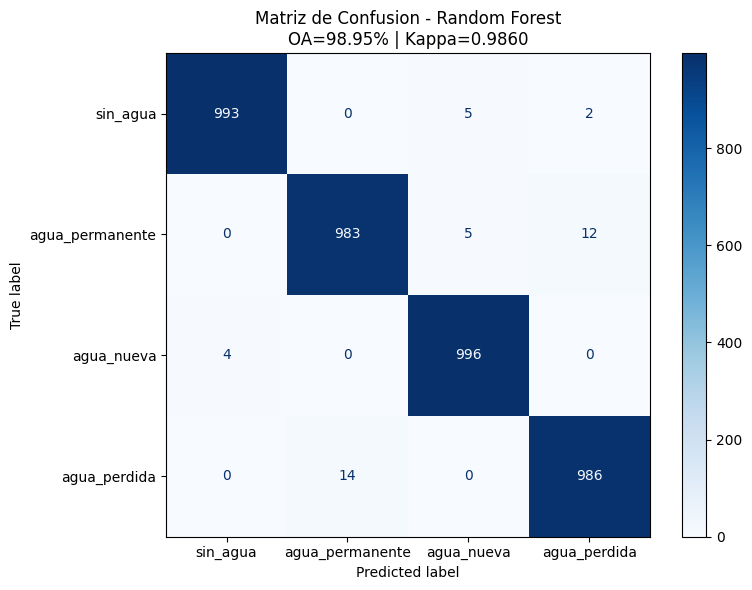

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_matriz_confusion.png


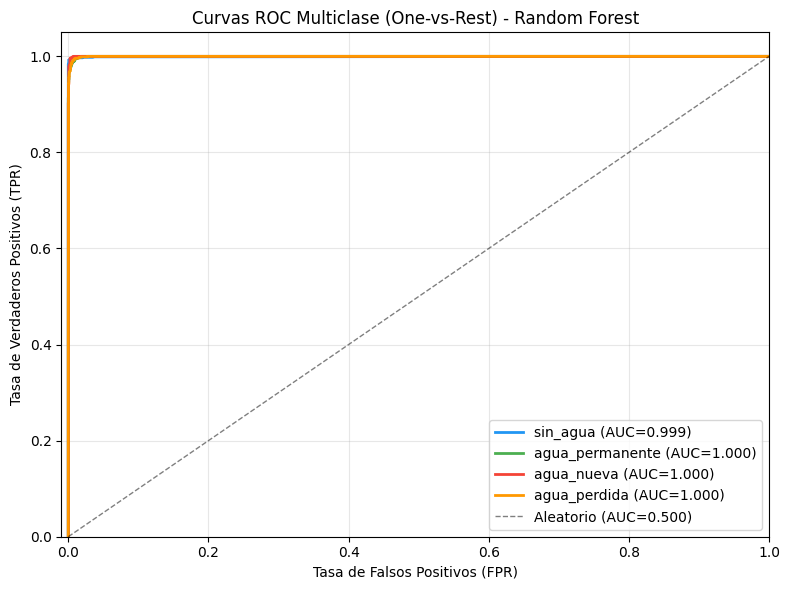

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_curvas_ROC.png

  Area Bajo la Curva (AUC) por clase:
    sin_agua: 0.9993
    agua_permanente: 0.9998
    agua_nueva: 0.9999
    agua_perdida: 0.9996
    Promedio (macro): 0.9997

[PASO 5] Analisis de importancia de features...

  Ranking de importancia de features:
     1. B11_post     0.2016 ####################
     2. B12_post     0.1548 ###############
     3. B11_pre      0.0869 ########
     4. B09_pre      0.0573 #####
     5. B07_pre      0.0531 #####
     6. B8A_post     0.0526 #####
     7. B12_pre      0.0504 #####
     8. B09_post     0.0499 ####
     9. B8A_pre      0.0443 ####
    10. B08_pre      0.0382 ###
    11. B08_post     0.0372 ###
    12. B07_post     0.0296 ##
    13. B06_pre      0.0289 ##
    14. B06_post     0.0209 ##
    15. B05_pre      0.0207 ##
    16. B03_post     0.0109 #
    17. B01_pre      0.0096 
    18. B02_pre      0.0092 
    19. B04_pre      0.0087 
    20. B05_post     0.0086 


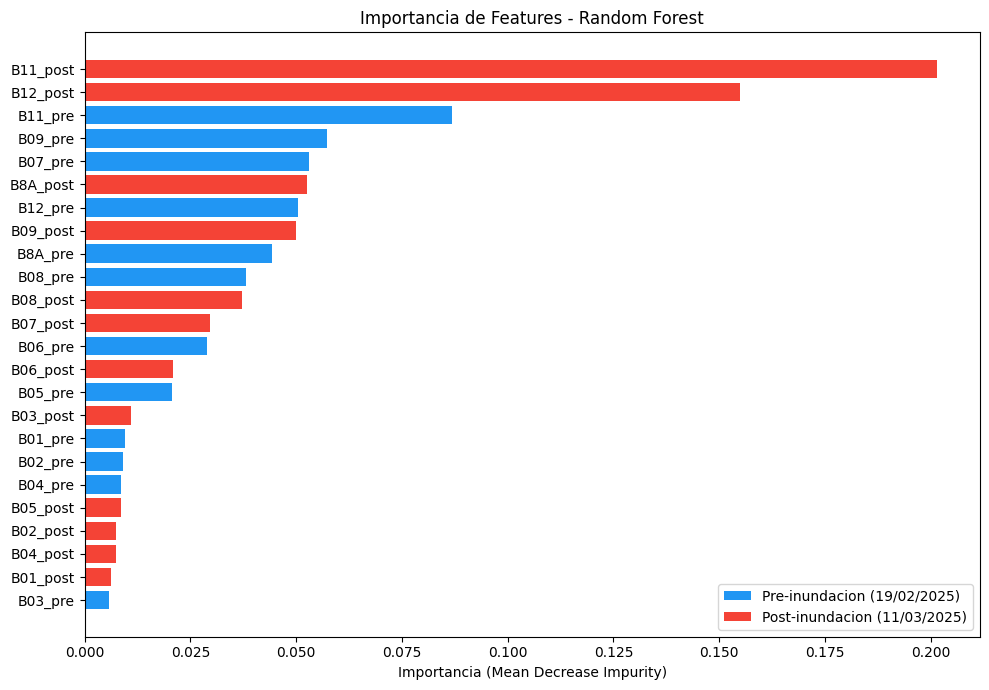

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_importancia_features.png

  Importancia agregada por periodo:
    Pre-inundacion:  0.4129 (41.3%)
    Post-inundacion: 0.5871 (58.7%)

[PASO 6] Exportando modelo y resultados...

  Modelo: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_mejor_modelo.pkl (9.0 MB)
  GridSearch: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_resultados_gridsearch.csv
  Importancias: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_importancia_features.csv
  Predicciones: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_predicciones_testeo.csv
  Metricas: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_metricas_resumen.csv

  RESUMEN DEL MODELO RANDOM FOREST

  Datos:
    Dataset total:     20,000 muestras x 24 features
    Entrenamiento:     16,000 muestras (80%)
    Testeo:            4,000 muestras (20%)
    Division:          Estratificada (stratify=y)

  Hiperparametros optimos (GridSearchCV, cv=5):
    max_

In [ ]:
"""
CLASIFICACION SUPERVISADA CON RANDOM FOREST
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

ESTRUCTURA DEL PIPELINE:
  Paso 1: Carga del dataset desde NPZ
  Paso 2: Division entrenamiento/testeo (80/20 estratificado)
  Paso 3: Optimizacion de hiperparametros con GridSearchCV (cv=5)
  Paso 4: Evaluacion (classification_report, matriz de confusion,
          Kappa, Accuracy, Precision, Recall, F1, curvas ROC con AUC)
  Paso 5: Analisis de importancia de features
  Paso 6: Exportacion del modelo con joblib
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Librerias ---
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    cohen_kappa_score, roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

# Semilla aleatoria para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Rutas
BASE_PATH = '/content/drive/MyDrive/sentinel_data'
RUTA_NPZ = os.path.join(BASE_PATH, 'dataset_rf', 'dataset_entrenamiento.npz')
CARPETA_SALIDA = os.path.join(BASE_PATH, 'resultados_rf')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Nombres de clases para visualizacion y reportes
CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

print("=" * 70)
print("  CLASIFICACION SUPERVISADA CON RANDOM FOREST")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 70)

# =============================================================================
# PASO 1: CARGA DEL DATASET DESDE NPZ
# =============================================================================
# Se carga el archivo NPZ generado en la etapa anterior.
# conservando los tipos de datos originales (float32, int8).
#
# Contenido del NPZ:
#   - features: matriz (20000, 24) con reflectancias de 12 bandas x 2 fechas
#   - clases: vector (20000,) con etiquetas 0, 1, 2, 3
#   - coords: matriz (20000, 2) con coordenadas (row, col) del pixel
#   - feature_names: nombres de las 24 columnas de features
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 1] Cargando dataset...\n")

if not os.path.exists(RUTA_NPZ):
    raise FileNotFoundError("No se encontro: " + RUTA_NPZ)

data = np.load(RUTA_NPZ, allow_pickle=True)

X = data['features']              # (20000, 24) - reflectancias
y = data['clases']                # (20000,)    - etiquetas
coords = data['coords']           # (20000, 2)  - coordenadas espaciales
feature_names = list(data['feature_names'])

print("  Features (X): shape={}, dtype={}".format(X.shape, X.dtype))
print("  Clases (y):   shape={}, dtype={}".format(y.shape, y.dtype))
print("  Coords:       shape={}".format(coords.shape))
print("  Features:     {}".format(len(feature_names)))
print()

# Distribucion de clases en el dataset completo
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y == clase_id)
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y) * 100))

# =============================================================================
# PASO 2: DIVISION ENTRENAMIENTO / TESTEO (80/20 ESTRATIFICADO)
# =============================================================================
# Se divide el dataset en 80% entrenamiento y 20% testeo usando
# stratify=y para garantizar que ambos conjuntos mantengan la misma
# proporcion de clases (25% cada una).
#
# La validacion cruzada de 5 pliegues se aplica dentro de GridSearchCV
# (Paso 3) sobre el conjunto de entrenamiento.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Division entrenamiento/testeo (80/20 estratificado)...\n")

X_train, X_test, y_train, y_test, coords_train, coords_test = train_test_split(
    X, y, coords,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print("  Entrenamiento: {:,} muestras (80%)".format(X_train.shape[0]))
print("  Testeo:        {:,} muestras (20%)".format(X_test.shape[0]))

# Verificar que la estratificacion se mantuvo
print("\n  Distribucion en entrenamiento:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y_train == clase_id)
    print("    Clase {} ({}): {:,}".format(clase_id, nombre, n))

print("\n  Distribucion en testeo:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y_test == clase_id)
    print("    Clase {} ({}): {:,}".format(clase_id, nombre, n))

# =============================================================================
# PASO 3: OPTIMIZACION DE HIPERPARAMETROS CON GRIDSEARCHCV (cv=5)
# =============================================================================
# Se define una grilla de 3 hiperparametros y se evalua cada combinacion
# mediante validacion cruzada estratificada de 5 pliegues sobre el
# conjunto de entrenamiento.
#
# Hiperparametros evaluados (3 x 3 x 3 = 27 combinaciones):
#   - n_estimators: cantidad de arboles en el bosque [50, 100, 200]
#   - max_depth: profundidad maxima de cada arbol [10, 20, None]
#   - min_samples_split: muestras minimas para dividir un nodo [2, 5, 10]
#
# Total de entrenamientos: 27 combinaciones x 5 pliegues = 135.
#
# scoring='accuracy'
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 3] Optimizacion de hiperparametros con GridSearchCV...\n")

# Grilla de hiperparametros
parametros = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

n_combinaciones = 1
for v in parametros.values():
    n_combinaciones *= len(v)

print("  Hiperparametros a evaluar:")
for param, valores in parametros.items():
    print("    {}: {}".format(param, valores))
print("  Total combinaciones: {}".format(n_combinaciones))
print("  Pliegues de validacion cruzada: 5")
print("  Total entrenamientos: {}".format(n_combinaciones * 5))

# Modelo base
modelo_base = RandomForestClassifier(random_state=RANDOM_SEED)

# Validacion cruzada estratificada de 5 pliegues
cv_estratificado = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Busqueda exhaustiva
busqueda = GridSearchCV(
    estimator=modelo_base,
    param_grid=parametros,
    cv=cv_estratificado,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\n  Ejecutando busqueda (esto puede tomar varios minutos)...")
t_inicio = time.time()
busqueda.fit(X_train, y_train)
t_total = time.time() - t_inicio

print("\n  Busqueda completada en {:.1f} segundos.".format(t_total))
print("\n  Mejores hiperparametros encontrados:")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("  Mejor accuracy en validacion cruzada: {:.4f}".format(
    busqueda.best_score_))

# Top 5 combinaciones
print("\n  Top 5 combinaciones:")
resultados_cv = pd.DataFrame(busqueda.cv_results_)
resultados_cv = resultados_cv.sort_values('rank_test_score')
for _, row in resultados_cv.head(5).iterrows():
    print("    #{}: accuracy={:.4f} | {}".format(
        int(row['rank_test_score']),
        row['mean_test_score'],
        row['params']))

# =============================================================================
# PASO 4: EVALUACION SOBRE EL CONJUNTO DE TESTEO
# =============================================================================
# Se evalua el mejor modelo encontrado sobre el 20% de datos que nunca
# participo en entrenamiento ni en validacion cruzada.
#
#   - Classification Report: Precision, Recall, F1-Score por clase
#   - Matriz de Confusion
#   - Overall Accuracy (OA): proporcion total de aciertos
#   - Kappa de Cohen
#   - Curvas ROC multiclase (One-vs-Rest) con Area Bajo la Curva (AUC)
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 4] Evaluacion sobre conjunto de testeo...\n")

# Extraer el mejor modelo de la busqueda
mejor_modelo = busqueda.best_estimator_

# Predicciones sobre testeo
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)

# --- 4a. Overall Accuracy ---
oa = accuracy_score(y_test, y_pred)
print("  Overall Accuracy (OA): {:.4f} ({:.2f}%)".format(oa, oa * 100))

# --- 4b. Coeficiente Kappa de Cohen ---

kappa = cohen_kappa_score(y_test, y_pred)

if kappa > 0.81:
    interp_kappa = "casi perfecto"
elif kappa > 0.61:
    interp_kappa = "sustancial"
elif kappa > 0.41:
    interp_kappa = "moderado"
else:
    interp_kappa = "bajo"

print("  Coeficiente Kappa:     {:.4f} ({})".format(kappa, interp_kappa))

# --- 4c. Classification Report (Precision, Recall, F1-Score) ---

nombres_clases = [CLASE_NOMBRES[i] for i in sorted(CLASE_NOMBRES.keys())]

reporte = classification_report(
    y_test, y_pred,
    target_names=nombres_clases,
    digits=4
)
print("\n  Classification Report:")
print(reporte)

# --- 4d. Matriz de Confusion ---

cm = confusion_matrix(y_test, y_pred)
print("  Matriz de Confusion:")
print(cm)

# --- 4e. Visualizacion de la Matriz de Confusion ---
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nombres_clases
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Matriz de Confusion - Random Forest\nOA={:.2f}% | Kappa={:.4f}'.format(
    oa * 100, kappa))
plt.tight_layout()

ruta_cm = os.path.join(CARPETA_SALIDA, 'RF_matriz_confusion.png')
plt.savefig(ruta_cm, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_cm))

# --- 4f. Curvas ROC Multiclase (One-vs-Rest) y Area Bajo la Curva ---

n_clases = len(CLASE_NOMBRES)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))
colores = ['#2196F3', '#4CAF50', '#F44336', '#FF9800']

auc_por_clase = {}
for i in range(n_clases):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    auc_por_clase[nombres_clases[i]] = auc_i
    ax.plot(fpr_i, tpr_i, color=colores[i], lw=2,
            label='{} (AUC={:.3f})'.format(nombres_clases[i], auc_i))

# Linea de referencia del clasificador aleatorio
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5,
        label='Aleatorio (AUC=0.500)')

ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) - Random Forest')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(CARPETA_SALIDA, 'RF_curvas_ROC.png')
plt.savefig(ruta_roc, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_roc))

# Resumen de AUC por clase
print("\n  Area Bajo la Curva (AUC) por clase:")
for nombre, auc_val in auc_por_clase.items():
    print("    {}: {:.4f}".format(nombre, auc_val))
auc_promedio = np.mean(list(auc_por_clase.values()))
print("    Promedio (macro): {:.4f}".format(auc_promedio))

# =============================================================================
# PASO 5: ANALISIS DE IMPORTANCIA DE FEATURES
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Analisis de importancia de features...\n")

importancias = mejor_modelo.feature_importances_

# Tabla ordenada de mayor a menor importancia
df_importancias = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': importancias
}).sort_values('Importancia', ascending=False)

print("  Ranking de importancia de features:")
for i, (_, row) in enumerate(df_importancias.iterrows(), 1):
    barra = '#' * int(row['Importancia'] * 100)
    print("    {:2d}. {:<12} {:.4f} {}".format(
        i, row['Feature'], row['Importancia'], barra))

# Visualizacion con barras horizontales coloreadas por periodo
fig, ax = plt.subplots(figsize=(10, 7))
df_plot = df_importancias.sort_values('Importancia', ascending=True)

# Azul para pre-inundacion, rojo para post-inundacion
colores_barras = []
for feat in df_plot['Feature']:
    if feat.endswith('_pre'):
        colores_barras.append('#2196F3')
    else:
        colores_barras.append('#F44336')

ax.barh(range(len(df_plot)), df_plot['Importancia'], color=colores_barras)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['Feature'])
ax.set_xlabel('Importancia (Mean Decrease Impurity)')
ax.set_title('Importancia de Features - Random Forest')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='Pre-inundacion (19/02/2025)'),
    Patch(facecolor='#F44336', label='Post-inundacion (11/03/2025)')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()

ruta_imp = os.path.join(CARPETA_SALIDA, 'RF_importancia_features.png')
plt.savefig(ruta_imp, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_imp))

# Importancia agregada por periodo
imp_pre = df_importancias[
    df_importancias['Feature'].str.endswith('_pre')]['Importancia'].sum()
imp_post = df_importancias[
    df_importancias['Feature'].str.endswith('_post')]['Importancia'].sum()
print("\n  Importancia agregada por periodo:")
print("    Pre-inundacion:  {:.4f} ({:.1f}%)".format(imp_pre, imp_pre * 100))
print("    Post-inundacion: {:.4f} ({:.1f}%)".format(imp_post, imp_post * 100))

# =============================================================================
# PASO 6: EXPORTACION DEL MODELO Y RESULTADOS
# =============================================================================
# Se exporta el modelo entrenado con joblib para poder reutilizarlo
# en la siguiente etapa (prediccion sobre la imagen completa).
# Tambien se guardan los resultados de evaluacion en CSV.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 6] Exportando modelo y resultados...\n")

# 6a. Modelo entrenado (.pkl) con joblib
ruta_modelo = os.path.join(CARPETA_SALIDA, 'RF_mejor_modelo.pkl')
joblib.dump(mejor_modelo, ruta_modelo)
tamano_modelo = os.path.getsize(ruta_modelo) / (1024 * 1024)
print("  Modelo: {} ({:.1f} MB)".format(ruta_modelo, tamano_modelo))

# 6b. Resultados de GridSearchCV (.csv)
ruta_cv = os.path.join(CARPETA_SALIDA, 'RF_resultados_gridsearch.csv')
resultados_cv.to_csv(ruta_cv, index=False)
print("  GridSearch: {}".format(ruta_cv))

# 6c. Importancia de features (.csv)
ruta_imp_csv = os.path.join(CARPETA_SALIDA, 'RF_importancia_features.csv')
df_importancias.to_csv(ruta_imp_csv, index=False)
print("  Importancias: {}".format(ruta_imp_csv))

# 6d. Predicciones sobre testeo con coordenadas (.csv)
# Incluye coordenadas para poder reconstruir espacialmente los errores
df_predicciones = pd.DataFrame({
    'row': coords_test[:, 0],
    'col': coords_test[:, 1],
    'clase_real': y_test,
    'clase_predicha': y_pred,
    'correcto': (y_test == y_pred).astype(int)
})
# Agregar probabilidades predichas por clase
for clase_id, nombre in CLASE_NOMBRES.items():
    df_predicciones['prob_{}'.format(nombre)] = y_proba[:, clase_id]

ruta_pred = os.path.join(CARPETA_SALIDA, 'RF_predicciones_testeo.csv')
df_predicciones.to_csv(ruta_pred, index=False)
print("  Predicciones: {}".format(ruta_pred))

# 6e. Resumen de metricas (.csv)
metricas = {
    'Overall_Accuracy': [oa],
    'Kappa': [kappa],
    'AUC_macro': [auc_promedio],
    'n_estimators': [busqueda.best_params_['n_estimators']],
    'max_depth': [str(busqueda.best_params_['max_depth'])],
    'min_samples_split': [busqueda.best_params_['min_samples_split']],
    'CV_best_score': [busqueda.best_score_],
    'train_samples': [X_train.shape[0]],
    'test_samples': [X_test.shape[0]],
    'n_features': [X_train.shape[1]],
    'random_seed': [RANDOM_SEED],
    'tiempo_gridsearch_seg': [round(t_total, 1)]
}
df_metricas = pd.DataFrame(metricas)
ruta_metricas = os.path.join(CARPETA_SALIDA, 'RF_metricas_resumen.csv')
df_metricas.to_csv(ruta_metricas, index=False)
print("  Metricas: {}".format(ruta_metricas))

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN DEL MODELO RANDOM FOREST")
print("=" * 70 + "\n")

print("  Datos:")
print("    Dataset total:     {:,} muestras x {} features".format(
    X.shape[0], X.shape[1]))
print("    Entrenamiento:     {:,} muestras (80%)".format(X_train.shape[0]))
print("    Testeo:            {:,} muestras (20%)".format(X_test.shape[0]))
print("    Division:          Estratificada (stratify=y)")
print()
print("  Hiperparametros optimos (GridSearchCV, cv=5):")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("    Accuracy en CV: {:.4f}".format(busqueda.best_score_))
print()
print("  Evaluacion sobre testeo:")
print("    Overall Accuracy: {:.4f} ({:.2f}%)".format(oa, oa * 100))
print("    Kappa de Cohen:   {:.4f} ({})".format(kappa, interp_kappa))
print("    AUC promedio:     {:.4f}".format(auc_promedio))
print()
print("  Archivos generados en {}:".format(CARPETA_SALIDA))
print("    -> RF_mejor_modelo.pkl (modelo exportado con joblib)")
print("    -> RF_resultados_gridsearch.csv")
print("    -> RF_importancia_features.csv")
print("    -> RF_predicciones_testeo.csv")
print("    -> RF_metricas_resumen.csv")
print("    -> RF_matriz_confusion.png")
print("    -> RF_curvas_ROC.png")
print("    -> RF_importancia_features.png")

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)

## 10) Implementación de SVM

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado correctamente.

  CLASIFICACION SUPERVISADA CON SUPPORT VECTOR MACHINE (SVM)
  Inundacion de Bahia Blanca - 7 de marzo de 2025

[PASO 1] Cargando dataset...

  Features (X): shape=(20000, 24), dtype=float32
  Clases (y):   shape=(20000,), dtype=int8
  Coords:       shape=(20000, 2)
  Features:     24

    Clase 0 (sin_agua): 5,000 (25.0%)
    Clase 1 (agua_permanente): 5,000 (25.0%)
    Clase 2 (agua_nueva): 5,000 (25.0%)
    Clase 3 (agua_perdida): 5,000 (25.0%)

[PASO 2] Division entrenamiento/testeo (80/20 estratificado)...

  Entrenamiento: 16,000 muestras (80%)
  Testeo:        4,000 muestras (20%)

  Distribucion en entrenamiento:
    Clase 0 (sin_agua): 4,000
    Clase 1 (agua_permanente): 4,000
    Clase 2 (agua_nueva): 4,000
    Clase 3 (agua_perdida): 4,000

  Distribucion en testeo:
    Clase 0 (sin_agua): 1,000
    Clase 1 (ag

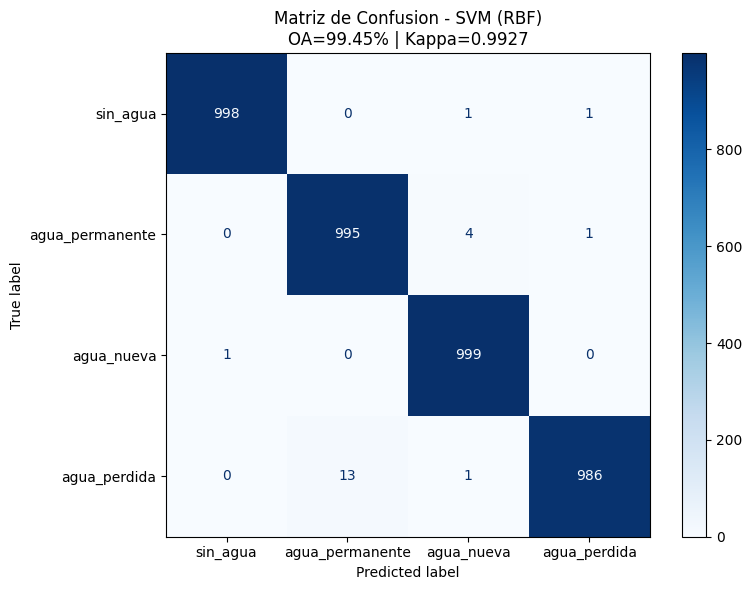

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_matriz_confusion.png


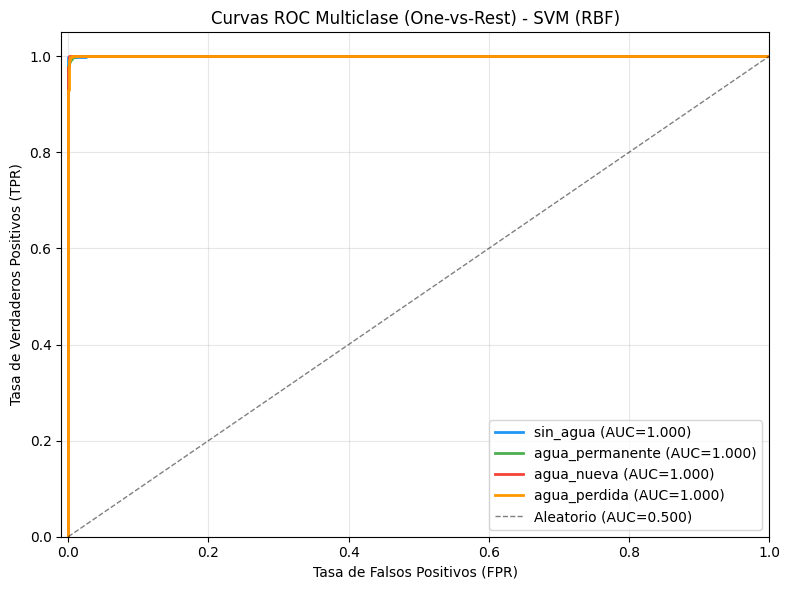

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_curvas_ROC.png

  Area Bajo la Curva (AUC) por clase:
    sin_agua: 1.0000
    agua_permanente: 0.9999
    agua_nueva: 1.0000
    agua_perdida: 1.0000
    Promedio (macro): 1.0000

  Calculando importancia por permutacion en el conjunto de testeo...
  Calculo completado en 25.9 segundos.

  Ranking de importancia por permutacion (caida media en accuracy):
     1. B11_post     0.3730 +/- 0.0056 ##########################################################################################################################################################################################
     2. B11_pre      0.1590 +/- 0.0025 ###############################################################################
     3. B12_pre      0.1031 +/- 0.0025 ###################################################
     4. B12_post     0.0681 +/- 0.0044 ##################################
     5. B03_post     0.0430 +/- 0.0028 #####################
   

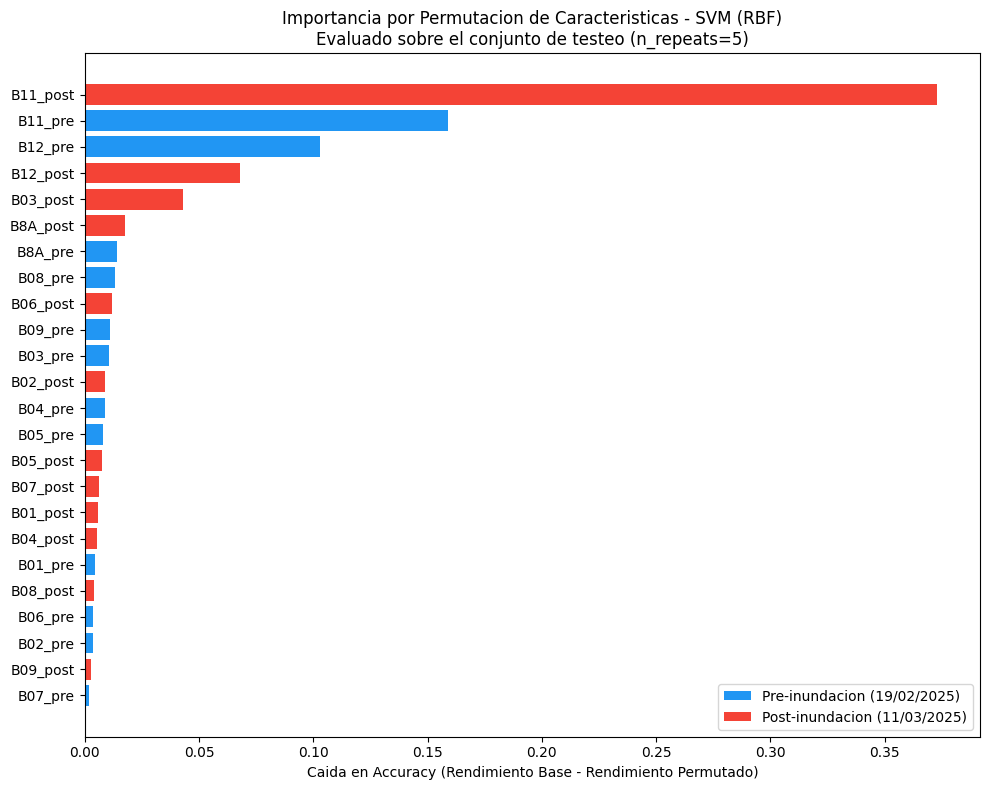

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_importancia_permutacion.png

[PASO 5] Exportando modelo y resultados...

  Modelo: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_mejor_modelo.pkl (0.1 MB)
  GridSearch: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_resultados_gridsearch.csv
  Predicciones: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_predicciones_testeo.csv
  Metricas: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_metricas_resumen.csv
  Importancias: /content/drive/MyDrive/sentinel_data/resultados_svm/SVM_importancia_valores.csv

  RESUMEN DEL MODELO SVM (RBF)

  Datos:
    Dataset total:     20,000 muestras x 24 features
    Entrenamiento:     16,000 muestras (80%)
    Testeo:            4,000 muestras (20%)
    Division:          Estratificada (stratify=y)
    Preprocesamiento:  StandardScaler dentro del Pipeline (sin leakage)

  Hiperparametros optimos (GridSearchCV, cv=5 estratificada):
    C: 100
    gamma:

In [ ]:
"""
CLASIFICACION SUPERVISADA CON SUPPORT VECTOR MACHINE (SVM)
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

ESTRUCTURA DEL PIPELINE:
  Paso 1: Carga del dataset desde NPZ
  Paso 2: Division entrenamiento/testeo (80/20 estratificado)
  Paso 3: Optimizacion de hiperparametros (C, gamma) con GridSearchCV sobre
          un Pipeline [StandardScaler -> SVC(rbf)] y CV estratificada de 5
  Paso 4: Evaluacion del mejor modelo (classification_report, matriz de
          confusion, Kappa, Accuracy, curvas ROC OvR con AUC) e importancia
          de variables por permutacion (sub-paso 4g), agnostica al modelo,
          para estimar la contribucion de cada banda pese a que el kernel RBF
          no expone una medida de importancia nativa
  Paso 5: Exportacion del modelo (Pipeline con probability=True) y resultados
          (incluye el CSV de importancias por permutacion)
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Montaje de Google Drive ---

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive montado correctamente.\n")
except ModuleNotFoundError:
    print("Aviso: no se esta en Google Colab; se omite el montaje de Drive.\n")
except Exception as e:
    print("Aviso: no se pudo montar Google Drive automaticamente: {}\n".format(e))

# --- Librerias ---
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    cohen_kappa_score, roc_curve, auc, ConfusionMatrixDisplay
)

# Semilla aleatoria para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Rutas
BASE_PATH = '/content/drive/MyDrive/sentinel_data'
RUTA_NPZ = os.path.join(BASE_PATH, 'dataset_rf', 'dataset_entrenamiento.npz')
CARPETA_SALIDA = os.path.join(BASE_PATH, 'resultados_svm')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Nombres de clases para visualizacion y reportes
CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

# -----------------------------------------------------------------------------
# CONTROL DE TIEMPO DE EJECUCION (MAX_TUNING)
# -----------------------------------------------------------------------------

MAX_TUNING = 6000

print("=" * 70)
print("  CLASIFICACION SUPERVISADA CON SUPPORT VECTOR MACHINE (SVM)")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 70)

# =============================================================================
# PASO 1: CARGA DEL DATASET DESDE NPZ
# =============================================================================
# Contenido del NPZ:
#   - features:      matriz (20000, 24) con reflectancias de 12 bandas x 2 fechas
#   - clases:        vector (20000,) con etiquetas 0, 1, 2, 3
#   - coords:        matriz (20000, 2) con coordenadas (row, col) del pixel
#   - feature_names: nombres de las 24 columnas de features
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 1] Cargando dataset...\n")

if not os.path.exists(RUTA_NPZ):
    # -------------------------------------------------------------------------
    # DIAGNOSTICO GUIADO
    # -------------------------------------------------------------------------
    print("  ERROR: no se encontro el archivo esperado:")
    print("    {}\n".format(RUTA_NPZ))

    if not os.path.exists('/content/drive/MyDrive'):
        # Causa 1: Drive no montado
        print("  Causa probable: Google Drive NO esta montado en esta sesion.")
        print("  Solucion: vuelva a ejecutar la celda (el montaje esta al inicio)")
        print("            o monte manualmente con:")
        print("              from google.colab import drive")
        print("              drive.mount('/content/drive')")
    else:
        # Drive montado: el problema esta en la ruta o en el archivo
        print("  Google Drive esta montado, pero el archivo no esta en esa ruta.")
        if os.path.exists(BASE_PATH):
            print("  La carpeta base SI existe: {}".format(BASE_PATH))
            print("  Contenido de la carpeta base:")
            for item in sorted(os.listdir(BASE_PATH)):
                print("    - {}".format(item))
        else:
            print("  La carpeta base NO existe: {}".format(BASE_PATH))
            print("  (revise si el nombre de la carpeta esta bien escrito)")

        # Buscar archivos .npz en el Drive para ayudar a localizar el dataset
        print("\n  Buscando archivos .npz en su Drive (puede tardar unos segundos)...")
        encontrados = glob.glob('/content/drive/MyDrive/**/*.npz', recursive=True)
        if encontrados:
            print("  Archivos .npz encontrados en su Drive:")
            for f in encontrados[:20]:
                print("    - {}".format(f))
            print("\n  Copie la ruta correcta y asignela a la variable RUTA_NPZ.")
        else:
            print("  No se encontraron archivos .npz en su Drive.")
            print("  Verifique que el dataset este subido a Google Drive.")

    raise FileNotFoundError(
        "No se encontro el dataset. Revise el diagnostico impreso mas arriba.")

data = np.load(RUTA_NPZ, allow_pickle=True)

X = data['features']              # (20000, 24) - reflectancias
y = data['clases']                # (20000,)    - etiquetas
coords = data['coords']           # (20000, 2)  - coordenadas espaciales
feature_names = list(data['feature_names'])

print("  Features (X): shape={}, dtype={}".format(X.shape, X.dtype))
print("  Clases (y):   shape={}, dtype={}".format(y.shape, y.dtype))
print("  Coords:       shape={}".format(coords.shape))
print("  Features:     {}".format(len(feature_names)))
print()

# Distribucion de clases en el dataset completo
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y == clase_id)
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y) * 100))

# =============================================================================
# PASO 2: DIVISION ENTRENAMIENTO / TESTEO (80/20 ESTRATIFICADO)
# =============================================================================
# Partición en 80% entrenamiento y 20% testeo, con stratify=y.
#
# La validacion cruzada de 5 pliegues se aplica dentro de GridSearchCV
# sobre el conjunto de entrenamiento; el conjunto de testeo permanece intacto.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Division entrenamiento/testeo (80/20 estratificado)...\n")

X_train, X_test, y_train, y_test, coords_train, coords_test = train_test_split(
    X, y, coords,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print("  Entrenamiento: {:,} muestras (80%)".format(X_train.shape[0]))
print("  Testeo:        {:,} muestras (20%)".format(X_test.shape[0]))

# Verificar que la estratificacion se mantuvo
print("\n  Distribucion en entrenamiento:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y_train == clase_id)
    print("    Clase {} ({}): {:,}".format(clase_id, nombre, n))

print("\n  Distribucion en testeo:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = np.sum(y_test == clase_id)
    print("    Clase {} ({}): {:,}".format(clase_id, nombre, n))

# =============================================================================
# PASO 3: OPTIMIZACION DE HIPERPARAMETROS (C, gamma) CON GRIDSEARCHCV (cv=5)
# =============================================================================
# Se construye un Pipeline de dos etapas:
#   [1] StandardScaler -> estandariza las 24 features (media 0, desvio 1)
#   [2] SVC(kernel='rbf') -> clasificador no lineal
#
# SVC entrena internamente con el esquema One-Versus-One
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 3] Optimizacion de hiperparametros con GridSearchCV...\n")

# Pipeline base: estandarizacion + SVM-RBF
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel='rbf',
        probability=False,
        decision_function_shape='ovr',
        class_weight=None,
        random_state=RANDOM_SEED
    ))
])

# Grilla de hiperparametros (los nombres llevan el prefijo del paso 'svc__')
parametros = {
    'svc__C':     [1, 10, 100],
    'svc__gamma': ['scale', 0.1, 1]
}

n_combinaciones = 1
for v in parametros.values():
    n_combinaciones *= len(v)

print("  Hiperparametros a evaluar:")
for param, valores in parametros.items():
    print("    {}: {}".format(param, valores))
print("  Total combinaciones: {}".format(n_combinaciones))
print("  Pliegues de validacion cruzada: 5 (estratificada)")
print("  Total entrenamientos: {}".format(n_combinaciones * 5))

if MAX_TUNING is not None and MAX_TUNING < X_train.shape[0]:
    frac = MAX_TUNING / X_train.shape[0]
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train,
        train_size=frac,
        random_state=RANDOM_SEED,
        stratify=y_train
    )
    print("\n  MAX_TUNING activo: la busqueda usa {:,} de {:,} muestras "
          "(estratificadas).".format(X_tune.shape[0], X_train.shape[0]))
else:
    X_tune, y_tune = X_train, y_train
    print("\n  MAX_TUNING desactivado: la busqueda usa todo X_train "
          "({:,} muestras).".format(X_train.shape[0]))

cv_estratificado = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Busqueda exhaustiva en grilla
busqueda = GridSearchCV(
    estimator=pipeline_base,
    param_grid=parametros,
    cv=cv_estratificado,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\n  Ejecutando busqueda ...")
t_inicio = time.time()
busqueda.fit(X_tune, y_tune)
t_total = time.time() - t_inicio

print("\n  Busqueda completada en {:.1f} segundos.".format(t_total))
print("\n  Mejores hiperparametros encontrados:")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("  Mejor accuracy en validacion cruzada: {:.4f}".format(
    busqueda.best_score_))

# Top 5 combinaciones
print("\n  Top 5 combinaciones:")
resultados_cv = pd.DataFrame(busqueda.cv_results_)
resultados_cv = resultados_cv.sort_values('rank_test_score')
for _, row in resultados_cv.head(5).iterrows():
    print("    #{}: accuracy={:.4f} | {}".format(
        int(row['rank_test_score']),
        row['mean_test_score'],
        row['params']))

# =============================================================================
# PASO 4: EVALUACION SOBRE EL CONJUNTO DE TESTEO
# =============================================================================
# Se construye el MODELO FINAL con los mejores hiperparametros
# Se reentrena sobre el 100% de X_train y se evalua sobre el 20%
#
#   - Classification Report: Precision, Recall, F1-Score por clase
#   - Matriz de Confusion
#   - Overall Accuracy (OA)
#   - Kappa de Cohen
#   - Curvas ROC multiclase (One-vs-Rest) con Area Bajo la Curva (AUC)
#   - Importancia de variables por permutacion (sub-paso 4g)
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 4] Evaluacion sobre conjunto de testeo...\n")

# Mejores hiperparametros hallados por la busqueda
mejor_C = busqueda.best_params_['svc__C']
mejor_gamma = busqueda.best_params_['svc__gamma']

# Modelo final
mejor_modelo = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel='rbf',
        C=mejor_C,
        gamma=mejor_gamma,
        probability=True,                  # habilita predict_proba (ROC)
        decision_function_shape='ovr',
        class_weight=None,
        random_state=RANDOM_SEED
    ))
])

print("  Reentrenando el mejor modelo sobre todo X_train "
      "(C={}, gamma={}, probability=True)...".format(mejor_C, mejor_gamma))
t0 = time.time()
mejor_modelo.fit(X_train, y_train)
print("  Reentrenamiento completado en {:.1f} segundos.".format(time.time() - t0))

# Predicciones y probabilidades sobre testeo
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)

# --- 4a. Overall Accuracy ---
oa = accuracy_score(y_test, y_pred)
print("\n  Overall Accuracy (OA): {:.4f} ({:.2f}%)".format(oa, oa * 100))

# --- 4b. Coeficiente Kappa de Cohen ---
kappa = cohen_kappa_score(y_test, y_pred)

if kappa > 0.81:
    interp_kappa = "casi perfecto"
elif kappa > 0.61:
    interp_kappa = "sustancial"
elif kappa > 0.41:
    interp_kappa = "moderado"
else:
    interp_kappa = "bajo"

print("  Coeficiente Kappa:     {:.4f} ({})".format(kappa, interp_kappa))

# --- 4c. Classification Report (Precision, Recall, F1-Score) ---
nombres_clases = [CLASE_NOMBRES[i] for i in sorted(CLASE_NOMBRES.keys())]

reporte = classification_report(
    y_test, y_pred,
    target_names=nombres_clases,
    digits=4
)
print("\n  Classification Report:")
print(reporte)

# --- 4d. Matriz de Confusion ---
cm = confusion_matrix(y_test, y_pred)
print("  Matriz de Confusion:")
print(cm)

# --- 4e. Visualizacion de la Matriz de Confusion ---
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nombres_clases
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Matriz de Confusion - SVM (RBF)\nOA={:.2f}% | Kappa={:.4f}'.format(
    oa * 100, kappa))
plt.tight_layout()

ruta_cm = os.path.join(CARPETA_SALIDA, 'SVM_matriz_confusion.png')
plt.savefig(ruta_cm, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_cm))

# --- 4f. Curvas ROC Multiclase (One-vs-Rest) y Area Bajo la Curva ---

n_clases = len(CLASE_NOMBRES)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))
colores = ['#2196F3', '#4CAF50', '#F44336', '#FF9800']

auc_por_clase = {}
for i in range(n_clases):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    auc_por_clase[nombres_clases[i]] = auc_i
    ax.plot(fpr_i, tpr_i, color=colores[i], lw=2,
            label='{} (AUC={:.3f})'.format(nombres_clases[i], auc_i))

# Linea de referencia del clasificador aleatorio
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5,
        label='Aleatorio (AUC=0.500)')

ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) - SVM (RBF)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(CARPETA_SALIDA, 'SVM_curvas_ROC.png')
plt.savefig(ruta_roc, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_roc))

# Resumen de AUC por clase
print("\n  Area Bajo la Curva (AUC) por clase:")
for nombre, auc_val in auc_por_clase.items():
    print("    {}: {:.4f}".format(nombre, auc_val))
auc_promedio = np.mean(list(auc_por_clase.values()))
print("    Promedio (macro): {:.4f}".format(auc_promedio))

# --- 4g. Importancia de Variables por Permutacion ---

print("\n  Calculando importancia por permutacion en el conjunto de testeo...")
t_perm = time.time()
resultado_perm = permutation_importance(
    mejor_modelo,
    X_test,
    y_test,
    n_repeats=5,
    scoring='accuracy',
    random_state=RANDOM_SEED,
    n_jobs=-1
)
print("  Calculo completado en {:.1f} segundos.".format(time.time() - t_perm))

# Tabla de importancias ordenada de mayor a menor (para tabla y CSV)
df_importancia = pd.DataFrame({
    'feature': feature_names,
    'importancia_media': resultado_perm.importances_mean,
    'desviacion_estandar': resultado_perm.importances_std
}).sort_values('importancia_media', ascending=False).reset_index(drop=True)

print("\n  Ranking de importancia por permutacion (caida media en accuracy):")
for i, row in df_importancia.iterrows():
    barra = '#' * int(max(row['importancia_media'], 0) * 500)
    print("    {:2d}. {:<12} {:.4f} +/- {:.4f} {}".format(
        i + 1, row['feature'], row['importancia_media'],
        row['desviacion_estandar'], barra))

# Visualizacion: barras horizontales coloreadas por periodo
df_plot = df_importancia.sort_values('importancia_media', ascending=True)

# Azul para pre-inundacion, rojo para post-inundacion
colores_barras = []
for feat in df_plot['feature']:
    if feat.endswith('_pre'):
        colores_barras.append('#2196F3')
    else:
        colores_barras.append('#F44336')

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(df_plot)), df_plot['importancia_media'], color=colores_barras)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['feature'])
ax.set_xlabel('Caida en Accuracy (Rendimiento Base - Rendimiento Permutado)')
ax.set_title('Importancia por Permutacion de Caracteristicas - SVM (RBF)\n'
             'Evaluado sobre el conjunto de testeo (n_repeats=5)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='Pre-inundacion (19/02/2025)'),
    Patch(facecolor='#F44336', label='Post-inundacion (11/03/2025)')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()

ruta_importancia_img = os.path.join(CARPETA_SALIDA, 'SVM_importancia_permutacion.png')
plt.savefig(ruta_importancia_img, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_importancia_img))

# =============================================================================
# PASO 5: EXPORTACION DEL MODELO Y RESULTADOS
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Exportando modelo y resultados...\n")

# 5a. Modelo entrenado (.pkl) con joblib  -> Pipeline (scaler + SVC)
ruta_modelo = os.path.join(CARPETA_SALIDA, 'SVM_mejor_modelo.pkl')
joblib.dump(mejor_modelo, ruta_modelo)
tamano_modelo = os.path.getsize(ruta_modelo) / (1024 * 1024)
print("  Modelo: {} ({:.1f} MB)".format(ruta_modelo, tamano_modelo))

# 5b. Resultados de GridSearchCV (.csv)
ruta_cv = os.path.join(CARPETA_SALIDA, 'SVM_resultados_gridsearch.csv')
resultados_cv.to_csv(ruta_cv, index=False)
print("  GridSearch: {}".format(ruta_cv))

# 5c. Predicciones sobre testeo con coordenadas (.csv)
df_predicciones = pd.DataFrame({
    'row': coords_test[:, 0],
    'col': coords_test[:, 1],
    'clase_real': y_test,
    'clase_predicha': y_pred,
    'correcto': (y_test == y_pred).astype(int)
})
# Agregar probabilidades predichas por clase
for clase_id, nombre in CLASE_NOMBRES.items():
    df_predicciones['prob_{}'.format(nombre)] = y_proba[:, clase_id]

ruta_pred = os.path.join(CARPETA_SALIDA, 'SVM_predicciones_testeo.csv')
df_predicciones.to_csv(ruta_pred, index=False)
print("  Predicciones: {}".format(ruta_pred))

# 5d. Resumen de metricas (.csv)
metricas = {
    'Overall_Accuracy': [oa],
    'Kappa': [kappa],
    'AUC_macro': [auc_promedio],
    'C': [mejor_C],
    'gamma': [str(mejor_gamma)],
    'kernel': ['rbf'],
    'CV_best_score': [busqueda.best_score_],
    'train_samples': [X_train.shape[0]],
    'test_samples': [X_test.shape[0]],
    'n_features': [X_train.shape[1]],
    'tuning_samples': [X_tune.shape[0]],
    'random_seed': [RANDOM_SEED],
    'tiempo_gridsearch_seg': [round(t_total, 1)]
}
df_metricas = pd.DataFrame(metricas)
ruta_metricas = os.path.join(CARPETA_SALIDA, 'SVM_metricas_resumen.csv')
df_metricas.to_csv(ruta_metricas, index=False)
print("  Metricas: {}".format(ruta_metricas))

# 5e. Valores de importancia por permutacion (.csv)
# Se exporta aqui la tabla calculada en el sub-paso 4g (orden descendente,
# de mayor a menor importancia media).
ruta_importancia_csv = os.path.join(CARPETA_SALIDA, 'SVM_importancia_valores.csv')
df_importancia.to_csv(ruta_importancia_csv, index=False)
print("  Importancias: {}".format(ruta_importancia_csv))

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN DEL MODELO SVM (RBF)")
print("=" * 70 + "\n")

print("  Datos:")
print("    Dataset total:     {:,} muestras x {} features".format(
    X.shape[0], X.shape[1]))
print("    Entrenamiento:     {:,} muestras (80%)".format(X_train.shape[0]))
print("    Testeo:            {:,} muestras (20%)".format(X_test.shape[0]))
print("    Division:          Estratificada (stratify=y)")
print("    Preprocesamiento:  StandardScaler dentro del Pipeline (sin leakage)")
print()
print("  Hiperparametros optimos (GridSearchCV, cv=5 estratificada):")
print("    C: {}".format(mejor_C))
print("    gamma: {}".format(mejor_gamma))
print("    Accuracy en CV: {:.4f}".format(busqueda.best_score_))
print()
print("  Evaluacion sobre testeo:")
print("    Overall Accuracy: {:.4f} ({:.2f}%)".format(oa, oa * 100))
print("    Kappa de Cohen:   {:.4f} ({})".format(kappa, interp_kappa))
print("    AUC promedio:     {:.4f}".format(auc_promedio))
print()
print("  Variable mas importante (permutacion): {} ({:.4f})".format(
    df_importancia.iloc[0]['feature'], df_importancia.iloc[0]['importancia_media']))
print()
print("  Archivos generados en {}:".format(CARPETA_SALIDA))
print("    -> SVM_mejor_modelo.pkl (Pipeline scaler+SVC exportado con joblib)")
print("    -> SVM_resultados_gridsearch.csv")
print("    -> SVM_predicciones_testeo.csv")
print("    -> SVM_metricas_resumen.csv")
print("    -> SVM_importancia_valores.csv")
print("    -> SVM_matriz_confusion.png")
print("    -> SVM_curvas_ROC.png")
print("    -> SVM_importancia_permutacion.png")

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)

## 11) Generación de nuevo dataset de entrenamiento

ESTRUCTURA DEL DATASET:
  Features (24 columnas):
    - 12 bandas espectrales x 2 fechas = 24 features de reflectancia
      Bandas: B01, B02, B03, B04, B05, B06, B07, B08, B8A, B09, B11, B12
      Excluida: True_color (compuesto RGB derivado, informacion redundante)

  Columnas auxiliares (no son features de entrenamiento):
    - row, col: coordenadas del pixel para reconstruccion espacial
    - clase: variable target (0=sin_agua, 1=agua_permanente, 2=agua_nueva,
             3=agua_perdida)

Esquema de particion espacial basado en
componentes conexas (blobs). Cada componente conexa se asigna de forma exclusiva a entrenamiento o a testeo, y se verifica que ninguna region de testeo se ubique a menos de 200 m (20 pixeles Sentinel-2) de una region de
entrenamiento de la misma clase

División: 80 / 20 para entrenamiento y testeo de forma estratificada entre clases

CUOTAS
  
  Entrenamiento: 16.000 pixeles (4.000 por clase)
  
  Testeo:         4.000 pixeles (1.000 por clase)



In [ ]:
"""
CONSTRUCCION DEL DATASET DE ENTRENAMIENTO Y TESTEO CON SEPARACION ESPACIAL
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Montaje de Google Drive ---

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive montado correctamente.\n")
except ModuleNotFoundError:
    print("Aviso: no se esta en Google Colab; se omite el montaje de Drive.\n")
except Exception as e:
    print("Aviso: no se pudo montar Google Drive automaticamente: {}\n".format(e))

import os
import zipfile
import numpy as np
import pandas as pd
import warnings

from scipy import ndimage
from scipy.spatial import cKDTree
from skimage.segmentation import find_boundaries

warnings.filterwarnings('ignore')

# --- Reproducibilidad ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)

# --- Rutas base ---
BASE_PATH = '/content/drive/MyDrive/sentinel_data'
CARPETA_SALIDA = os.path.join(BASE_PATH, 'dataset_blobs')

ZIPS = {
    'pre': {
        'ruta': os.path.join(BASE_PATH, 'pre_inundacion', '19_2_25.zip'),
        'prefijo_fecha': '2025-02-19',
        'etiqueta': 'Pre-inundacion (19/02/2025)'
    },
    'post': {
        'ruta': os.path.join(BASE_PATH, 'post_inundacion', '11_3_25.zip'),
        'prefijo_fecha': '2025-03-11',
        'etiqueta': 'Post-inundacion (11/03/2025)'
    }
}

BANDAS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08',
          'B8A', 'B09', 'B11', 'B12']

CLASE_MAP = {
    0:   0,   # sin_agua
    128: 1,   # agua_permanente
    255: 2,   # agua_nueva (inundacion)
    64:  3    # agua_perdida
}
VALOR_DE_CLASE = {v: k for k, v in CLASE_MAP.items()}

CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

# --- Cuotas de muestreo ---
N_TRAIN_POR_CLASE = 4000
N_TEST_POR_CLASE = 1000
MARGEN_MUESTREO = 1.10        # sobre-muestreo para absorber NaN/Inf

# --- Separacion espacial ---
BUFFER_OBJETIVO_M = 200.0
BUFFER_OBJETIVO_PX = int(round(BUFFER_OBJETIVO_M / RESOLUCION_M))   # 20
BUFFER_MIN_PX = 2

ESCALERA_BUFFER_PX = sorted(
    {int(round(BUFFER_OBJETIVO_PX * f)) for f in [1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2]}
    | {BUFFER_MIN_PX},
    reverse=True
)   # -> [20, 16, 12, 10, 8, 6, 4, 2]

# --- Regionalizacion ---
# Las componentes conexas mayores a TAM_MAX_REGION_PX se subdividen en
# teselas cuadradas de lado TAM_TESELA_PX.
SUBDIVIDIR_REGIONES_GRANDES = True
TAM_MAX_REGION_PX = 5000      # ~50 ha; por encima de esto se tesela
TAM_TESELA_PX = 64            # 640 m x 640 m

# --- Politica de asignacion de regiones ---
FACTOR_COBERTURA = 3.0        # capacidad objetivo = cuota x factor
MIN_REGIONES_TRAIN = 60       # diversidad espacial minima (si hay disponibles)
MIN_REGIONES_TEST = 25
FRACCION_MAX_POR_REGION = 0.15   # ninguna region aporta mas del 15% de la cuota

# --- Salidas opcionales ---
GENERAR_MAPA_ASIGNACION = True


# =============================================================================
# FUNCIONES AUXILIARES
# =============================================================================

def agrupar_por_etiqueta(etiquetas, rows, cols, n_regiones):
    """Agrupa coordenadas (row, col) por identificador de region.

    Devuelve un diccionario {region_id: array (n, 2) de coordenadas}.
    Se implementa con un unico ordenamiento y busquedas binarias para evitar
    recorrer la imagen una vez por region.
    """
    if len(etiquetas) == 0:
        return {}
    orden = np.argsort(etiquetas, kind='stable')
    etiq_ord = etiquetas[orden]
    rows_ord = rows[orden]
    cols_ord = cols[orden]

    ids = np.arange(1, n_regiones + 1)
    ini = np.searchsorted(etiq_ord, ids, side='left')
    fin = np.searchsorted(etiq_ord, ids, side='right')

    salida = {}
    for rid, a, b in zip(ids, ini, fin):
        if b > a:
            salida[int(rid)] = np.column_stack([rows_ord[a:b], cols_ord[a:b]])
    return salida


def regionalizar_clase(mascara, subdividir=True, tam_max=TAM_MAX_REGION_PX,
                       tesela=TAM_TESELA_PX):
    """Etiqueta componentes conexas (8-conectadas) sobre la mascara binaria.

    Las componentes cuyo tamano supera `tam_max` se subdividen en teselas
    regulares de lado `tesela`. Cada tesela de una componente grande pasa a ser
    una region independiente, elegible de forma exclusiva para train o test.

    Devuelve (raster_regiones, n_regiones, n_componentes_originales).
    """
    estructura_8 = np.ones((3, 3), dtype=int)
    componentes, n_comp = ndimage.label(mascara, structure=estructura_8)

    if not subdividir or n_comp == 0:
        return componentes.astype(np.int32), int(n_comp), int(n_comp)

    tamanos = np.bincount(componentes.ravel())
    grandes = np.zeros(tamanos.shape[0], dtype=bool)
    grandes[1:] = tamanos[1:] > tam_max

    if not grandes.any():
        return componentes.astype(np.int32), int(n_comp), int(n_comp)

    rows, cols = np.nonzero(mascara)
    lab = componentes[rows, cols].astype(np.int64)

    n_tes_col = int(np.ceil(mascara.shape[1] / tesela))
    tesela_id = (rows // tesela).astype(np.int64) * n_tes_col + (cols // tesela)
    n_teselas = int(np.ceil(mascara.shape[0] / tesela)) * n_tes_col + 1

    es_grande = grandes[lab]
    # Clave compuesta: componente original + tesela (solo si es componente grande)
    clave = lab * n_teselas + np.where(es_grande, tesela_id + 1, 0)

    _, nuevas = np.unique(clave, return_inverse=True)
    regiones = np.zeros(mascara.shape, dtype=np.int32)
    regiones[rows, cols] = (nuevas + 1).astype(np.int32)

    return regiones, int(nuevas.max() + 1), int(n_comp)


def contornos_por_region(regiones, n_regiones, pixeles_region):
    """Extrae los pixeles de contorno (borde interno) de cada region.

    La distancia minima entre dos regiones disjuntas y solidas se alcanza
    siempre entre pixeles de sus contornos, de modo que trabajar con bordes
    reduce el numero de puntos del KD-tree sin alterar el resultado.
    """
    bordes = find_boundaries(regiones, connectivity=2, mode='inner',
                             background=0)
    rows, cols = np.nonzero(bordes)
    etiquetas = regiones[rows, cols]
    contornos = agrupar_por_etiqueta(etiquetas, rows, cols, n_regiones)

    # Salvaguarda: regiones sin borde detectado usan todos sus pixeles
    for rid, pts in pixeles_region.items():
        if rid not in contornos or len(contornos[rid]) == 0:
            contornos[rid] = pts
    return contornos


def asignar_regiones(pixeles_region, contornos_region, cuota_train, cuota_test,
                     buffer_px, factor=FACTOR_COBERTURA,
                     min_train=MIN_REGIONES_TRAIN, min_test=MIN_REGIONES_TEST):
    """Asigna regiones a train o test respetando un buffer minimo.

    Estrategia: se recorren las regiones de mayor a menor tamano y se
    asigna cada una al conjunto con mayor deficit relativo de cobertura,
    siempre que su contorno se ubique a una distancia euclidea >= buffer_px
    de todas las regiones ya asignadas al conjunto opuesto. Las regiones que
    violan la restriccion para ambos conjuntos se descartan y actuan como
    zona de amortiguacion.

    Devuelve un diccionario con las regiones asignadas y los pixeles disponibles.
    """
    cap_train = cuota_train * factor
    cap_test = cuota_test * factor

    # Orden: tamano descendente. El desempate entre regiones de igual tamano es
    # aleatorio (pero reproducible) para que las teselas seleccionadas no queden
    # concentradas en un sector de la imagen por el orden de etiquetado raster.
    gen_orden = np.random.default_rng(RANDOM_SEED)
    claves = {r: gen_orden.random() for r in sorted(pixeles_region.keys())}
    orden = sorted(pixeles_region.keys(),
                   key=lambda r: (-len(pixeles_region[r]), claves[r]))

    train, test, descartadas = [], [], []
    px_train, px_test = 0, 0
    pts_train, pts_test = [], []
    tree_train, tree_test = None, None
    sucio_train, sucio_test = False, False

    def _tree(puntos):
        if not puntos:
            return None
        return cKDTree(np.vstack(puntos))

    def _compatible(cand, tree_opuesto):
        if tree_opuesto is None:
            return True
        distancias, _ = tree_opuesto.query(cand, k=1)
        return float(distancias.min()) >= buffer_px

    for rid in orden:
        completo = (px_train >= cap_train and px_test >= cap_test and
                    len(train) >= min_train and len(test) >= min_test)
        if completo:
            break

        cand = contornos_region[rid].astype(np.float64)

        falta_train = (px_train < cap_train) or (len(train) < min_train)
        falta_test = (px_test < cap_test) or (len(test) < min_test)

        ratio_train = px_train / cap_train if cap_train > 0 else 1.0
        ratio_test = px_test / cap_test if cap_test > 0 else 1.0
        preferencia = ['train', 'test'] if ratio_train <= ratio_test else ['test', 'train']

        asignada = False
        for orden_intento, destino in enumerate(preferencia):
            if destino == 'train' and not falta_train:
                continue
            if destino == 'test' and not falta_test:
                continue
            # Salvaguarda: si la region se pretendia para testeo y fue rechazada
            # por proximidad, no se absorbe en entrenamiento mientras el conjunto
            # de testeo siga incompleto (evita agotar las regiones candidatas).
            if (destino == 'train' and orden_intento == 1 and
                    len(test) < min_test):
                continue

            if destino == 'train':
                if sucio_test:
                    tree_test = _tree(pts_test)
                    sucio_test = False
                if _compatible(cand, tree_test):
                    train.append(rid)
                    px_train += len(pixeles_region[rid])
                    pts_train.append(contornos_region[rid].astype(np.float64))
                    sucio_train = True
                    asignada = True
                    break
            else:
                if sucio_train:
                    tree_train = _tree(pts_train)
                    sucio_train = False
                if _compatible(cand, tree_train):
                    test.append(rid)
                    px_test += len(pixeles_region[rid])
                    pts_test.append(contornos_region[rid].astype(np.float64))
                    sucio_test = True
                    asignada = True
                    break

        if not asignada:
            descartadas.append(rid)

    return {
        'train': train,
        'test': test,
        'descartadas': descartadas,
        'px_train': px_train,
        'px_test': px_test,
        'buffer_px': buffer_px
    }


def asignar_con_relajacion(pixeles_region, contornos_region, cuota_train,
                           cuota_test, escalera=ESCALERA_BUFFER_PX):
    """Aplica `asignar_regiones` reduciendo el buffer hasta cubrir las cuotas.

    La relajacion es especifica de la clase: se detiene en el primer buffer que
    permite alcanzar simultaneamente la cuota de train y la de test.
    """
    intentos = []
    resultado = None
    for buffer_px in escalera:
        res = asignar_regiones(pixeles_region, contornos_region,
                               cuota_train, cuota_test, buffer_px)
        intentos.append((buffer_px, res['px_train'], res['px_test']))
        resultado = res
        if res['px_train'] >= cuota_train and res['px_test'] >= cuota_test:
            break
    resultado['intentos'] = intentos
    return resultado


def repartir_cuota(cuota, tamanos, fraccion_max=FRACCION_MAX_POR_REGION):
    """Reparte la cuota de pixeles entre regiones proporcionalmente al tamano.

    Se impone un tope por region (fraccion_max de la cuota) para evitar que una
    unica region domine la muestra, y se redistribuye el remanente entre las
    regiones con capacidad libre.
    """
    tamanos = np.asarray(tamanos, dtype=np.int64)
    n = len(tamanos)
    if n == 0 or cuota <= 0:
        return np.zeros(n, dtype=np.int64)

    tope = np.maximum(1, int(np.ceil(cuota * fraccion_max)))
    capacidad = np.minimum(tamanos, tope)
    asignado = np.zeros(n, dtype=np.int64)
    restante = int(min(cuota, capacidad.sum()))

    while restante > 0:
        libres = capacidad - asignado
        activos = libres > 0
        if not activos.any():
            break
        pesos = tamanos * activos
        if pesos.sum() == 0:
            break
        reparto = np.floor(restante * pesos / pesos.sum()).astype(np.int64)
        reparto = np.minimum(reparto, libres)
        if reparto.sum() == 0:
            # Reparto unitario para cerrar el remanente
            idx = np.flatnonzero(activos)
            for i in idx:
                if restante == 0:
                    break
                asignado[i] += 1
                restante -= 1
            continue
        asignado += reparto
        restante -= int(reparto.sum())

    # Si el tope por region impide cubrir la cuota y aun queda capacidad real,
    # se relaja el tope (caso de clases con muy pocas regiones disponibles).
    faltante = int(min(cuota, tamanos.sum())) - int(asignado.sum())
    while faltante > 0:
        libres = tamanos - asignado
        activos = libres > 0
        if not activos.any():
            break
        pesos = tamanos * activos
        reparto = np.floor(faltante * pesos / pesos.sum()).astype(np.int64)
        reparto = np.minimum(reparto, libres)
        if reparto.sum() == 0:
            for i in np.flatnonzero(activos):
                if faltante == 0:
                    break
                asignado[i] += 1
                faltante -= 1
            continue
        asignado += reparto
        faltante -= int(reparto.sum())

    return asignado


def muestrear_pixeles(pixeles_region, regiones_asignadas, cuota, generador):
    """Selecciona `cuota` pixeles distribuidos entre las regiones asignadas."""
    if not regiones_asignadas:
        return np.empty((0, 2), dtype=np.int64), np.empty(0, dtype=np.int64)

    tamanos = [len(pixeles_region[r]) for r in regiones_asignadas]
    reparto = repartir_cuota(cuota, tamanos)

    coords, ids = [], []
    for rid, n_tomar in zip(regiones_asignadas, reparto):
        if n_tomar <= 0:
            continue
        pts = pixeles_region[rid]
        idx = generador.choice(len(pts), size=int(n_tomar), replace=False)
        coords.append(pts[idx])
        ids.append(np.full(int(n_tomar), rid, dtype=np.int64))

    if not coords:
        return np.empty((0, 2), dtype=np.int64), np.empty(0, dtype=np.int64)
    return np.vstack(coords), np.concatenate(ids)


def distancia_minima_entre_conjuntos(coords_a, coords_b):
    """Distancia euclidea minima (en pixeles) entre dos nubes de puntos."""
    if len(coords_a) == 0 or len(coords_b) == 0:
        return np.nan
    arbol = cKDTree(coords_a.astype(np.float64))
    distancias, _ = arbol.query(coords_b.astype(np.float64), k=1)
    return float(distancias.min())


# =============================================================================
# FIN DE FUNCIONES
# =============================================================================


print("=" * 78)
print("  DATASET CON PARTICION ESPACIAL POR COMPONENTES CONEXAS (BLOBS)")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 78)
print()
print("  Configuracion:")
print("    Cuota entrenamiento: {:,} px/clase ({:,} totales)".format(
    N_TRAIN_POR_CLASE, N_TRAIN_POR_CLASE * len(CLASE_NOMBRES)))
print("    Cuota testeo:        {:,} px/clase ({:,} totales)".format(
    N_TEST_POR_CLASE, N_TEST_POR_CLASE * len(CLASE_NOMBRES)))
print("    Buffer objetivo:     {:.0f} m ({} px)".format(
    BUFFER_OBJETIVO_M, BUFFER_OBJETIVO_PX))
print("    Escalera de buffer:  {} px".format(ESCALERA_BUFFER_PX))
print("    Subdivision:         {} (tesela {}x{} px, umbral {:,} px)".format(
    SUBDIVIDIR_REGIONES_GRANDES, TAM_TESELA_PX, TAM_TESELA_PX,
    TAM_MAX_REGION_PX))
print("    Semilla aleatoria:   {}".format(RANDOM_SEED))
print("    Bandas por fecha:    {} ({})".format(len(BANDAS), ', '.join(BANDAS)))


# =============================================================================
# PASO 1: CARGA DEL MAPA DE CAMBIO
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 1] Carga del mapa de cambio...\n")

ruta_npz = os.path.join(BASE_PATH, 'otsu_results', 'OTSU_mascaras_pre_post.npz')
if not os.path.exists(ruta_npz):
    raise FileNotFoundError("No se encontro: " + ruta_npz)

data_otsu = np.load(ruta_npz, allow_pickle=True)
mapa_cambio = data_otsu['mapa_cambio']
alto, ancho = mapa_cambio.shape
print("  Mapa de cambio: {} x {} pixeles ({:,} px totales)".format(
    alto, ancho, alto * ancho))


# =============================================================================
# PASO 2: REGIONALIZACION Y ASIGNACION EXCLUSIVA DE REGIONES
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 2] Regionalizacion por componentes conexas y asignacion...\n")

coords_train_lista, ids_train_lista, clases_train_lista = [], [], []
coords_test_lista, ids_test_lista, clases_test_lista = [], [], []
registro_log = []
mapa_asignacion = np.zeros((alto, ancho), dtype=np.uint8)  # 0=no usado,1=train,2=test,3=descartada

for clase_id in sorted(CLASE_NOMBRES.keys()):
    nombre = CLASE_NOMBRES[clase_id]
    valor = VALOR_DE_CLASE[clase_id]
    print("  " + "-" * 74)
    print("  Clase {} ({}) - valor {} en el mapa de cambio".format(
        clase_id, nombre, valor))

    mascara = (mapa_cambio == valor)
    n_px_clase = int(mascara.sum())

    regiones, n_regiones, n_comp = regionalizar_clase(
        mascara, subdividir=SUBDIVIDIR_REGIONES_GRANDES)

    rows, cols = np.nonzero(mascara)
    pixeles_region = agrupar_por_etiqueta(regiones[rows, cols], rows, cols,
                                          n_regiones)
    contornos_region = contornos_por_region(regiones, n_regiones, pixeles_region)

    print("    Pixeles de la clase:      {:,}".format(n_px_clase))
    print("    Componentes conexas:      {:,}".format(n_comp))
    print("    Regiones tras subdividir: {:,}".format(len(pixeles_region)))

    # --- Asignacion con relajacion progresiva del buffer ---
    resultado = asignar_con_relajacion(
        pixeles_region, contornos_region,
        cuota_train=int(N_TRAIN_POR_CLASE * MARGEN_MUESTREO),
        cuota_test=int(N_TEST_POR_CLASE * MARGEN_MUESTREO))

    buffer_aplicado = resultado['buffer_px']
    relajado = buffer_aplicado < BUFFER_OBJETIVO_PX

    print("    Buffer objetivo:          {} px ({:.0f} m)".format(
        BUFFER_OBJETIVO_PX, BUFFER_OBJETIVO_M))
    print("    Buffer aplicado:          {} px ({:.0f} m){}".format(
        buffer_aplicado, buffer_aplicado * RESOLUCION_M,
        "   [RELAJADO]" if relajado else ""))
    print("    Regiones train / test:    {:,} / {:,}   (descartadas: {:,})".format(
        len(resultado['train']), len(resultado['test']),
        len(resultado['descartadas'])))
    print("    Pixeles disponibles:      train {:,} | test {:,}".format(
        resultado['px_train'], resultado['px_test']))

    # --- Muestreo dentro de las regiones asignadas ---
    n_train_obj = int(np.ceil(N_TRAIN_POR_CLASE * MARGEN_MUESTREO))
    n_test_obj = int(np.ceil(N_TEST_POR_CLASE * MARGEN_MUESTREO))

    c_tr, i_tr = muestrear_pixeles(pixeles_region, resultado['train'],
                                   n_train_obj, rng)
    c_te, i_te = muestrear_pixeles(pixeles_region, resultado['test'],
                                   n_test_obj, rng)

    if len(c_tr) < N_TRAIN_POR_CLASE or len(c_te) < N_TEST_POR_CLASE:
        print("    ADVERTENCIA: cuota no alcanzada "
              "(train {:,} / test {:,}).".format(len(c_tr), len(c_te)))

    # --- Verificacion de la separacion efectiva ---
    dist_real_px = distancia_minima_entre_conjuntos(c_tr, c_te)
    print("    Distancia minima real train-test: {:.2f} px ({:.0f} m)".format(
        dist_real_px, dist_real_px * RESOLUCION_M))

    # region_id global y trazable: clase * 1e6 + etiqueta local
    offset = clase_id * 1000000
    coords_train_lista.append(c_tr)
    ids_train_lista.append(i_tr + offset)
    clases_train_lista.append(np.full(len(c_tr), clase_id, dtype=np.int64))

    coords_test_lista.append(c_te)
    ids_test_lista.append(i_te + offset)
    clases_test_lista.append(np.full(len(c_te), clase_id, dtype=np.int64))

    # Mapa de asignacion para control visual
    for rid in resultado['train']:
        pts = pixeles_region[rid]
        mapa_asignacion[pts[:, 0], pts[:, 1]] = 1
    for rid in resultado['test']:
        pts = pixeles_region[rid]
        mapa_asignacion[pts[:, 0], pts[:, 1]] = 2
    for rid in resultado['descartadas']:
        pts = pixeles_region[rid]
        mapa_asignacion[pts[:, 0], pts[:, 1]] = 3

    registro_log.append({
        'clase_id': clase_id,
        'clase_nombre': nombre,
        'px_totales_clase': n_px_clase,
        'componentes_conexas': n_comp,
        'regiones_disponibles': len(pixeles_region),
        'buffer_objetivo_px': BUFFER_OBJETIVO_PX,
        'buffer_objetivo_m': BUFFER_OBJETIVO_M,
        'buffer_aplicado_px': buffer_aplicado,
        'buffer_aplicado_m': buffer_aplicado * RESOLUCION_M,
        'buffer_relajado': bool(relajado),
        'n_regiones_train': len(resultado['train']),
        'n_regiones_test': len(resultado['test']),
        'n_regiones_descartadas': len(resultado['descartadas']),
        'px_disponibles_train': resultado['px_train'],
        'px_disponibles_test': resultado['px_test'],
        'cuota_train': N_TRAIN_POR_CLASE,
        'cuota_test': N_TEST_POR_CLASE,
        'px_muestreados_train': int(len(c_tr)),
        'px_muestreados_test': int(len(c_te)),
        'cuota_cumplida': bool(len(c_tr) >= N_TRAIN_POR_CLASE and
                               len(c_te) >= N_TEST_POR_CLASE),
        'dist_min_real_px': round(dist_real_px, 3),
        'dist_min_real_m': round(dist_real_px * RESOLUCION_M, 1)
    })

    del regiones, pixeles_region, contornos_region

coords_train = np.vstack(coords_train_lista)
region_train = np.concatenate(ids_train_lista)
clases_train = np.concatenate(clases_train_lista)

coords_test = np.vstack(coords_test_lista)
region_test = np.concatenate(ids_test_lista)
clases_test = np.concatenate(clases_test_lista)

n_train = len(clases_train)
n_test = len(clases_test)
print("\n  Total muestreado: train {:,} | test {:,}".format(n_train, n_test))


# =============================================================================
# PASO 3: EXTRACCION DE REFLECTANCIAS DESDE LOS ZIPs
# =============================================================================
# Se concatenan las coordenadas de ambos conjuntos y se realiza una unica
# lectura por banda.
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 3] Extraccion de reflectancias desde los ZIPs...\n")

import rasterio  # se importa aqui para no exigirlo en el resto del script

coords_todas = np.vstack([coords_train, coords_test])
N_total = len(coords_todas)
features = {}

for periodo, config in ZIPS.items():
    ruta_zip = config['ruta']
    print("  {}".format(config['etiqueta']))
    print("  ZIP: {}".format(ruta_zip))

    if not os.path.exists(ruta_zip):
        raise FileNotFoundError("No se encontro: " + ruta_zip)

    with zipfile.ZipFile(ruta_zip, 'r') as zf:
        tiff_files = [f for f in zf.namelist()
                      if f.lower().endswith(('.tiff', '.tif'))]

        for banda_nombre in BANDAS:
            archivo_banda = None
            patron = '_{}_('.format(banda_nombre)
            for tiff in tiff_files:
                if patron in tiff:
                    archivo_banda = tiff
                    break

            col_name = "{}_{}".format(banda_nombre, periodo)

            if archivo_banda is None:
                print("    ADVERTENCIA: no se encontro {} en el ZIP".format(
                    banda_nombre))
                features[col_name] = np.full(N_total, np.nan, dtype=np.float32)
                continue

            with zf.open(archivo_banda) as band_file:
                band_bytes = band_file.read()
                with rasterio.io.MemoryFile(band_bytes) as memfile:
                    with memfile.open() as src:
                        banda_data = src.read(1)
                        if banda_data.shape != (alto, ancho):
                            print("    ADVERTENCIA: {} tiene shape {} "
                                  "(esperado {})".format(
                                      banda_nombre, banda_data.shape,
                                      (alto, ancho)))
                        valores = banda_data[coords_todas[:, 0],
                                             coords_todas[:, 1]]
                        features[col_name] = valores.astype(np.float32)

            print("    {} -> {} (rango: {:.4f} a {:.4f})".format(
                banda_nombre, col_name, np.nanmin(features[col_name]),
                np.nanmax(features[col_name])))
    print()


# =============================================================================
# PASO 4: CONSTRUCCION DE LOS DATAFRAMES
# =============================================================================

print("=" * 78)
print("[PASO 4] Construccion de df_train y df_test...\n")

data_dict = {
    'row': coords_todas[:, 0].astype(np.int32),
    'col': coords_todas[:, 1].astype(np.int32),
    'region_id': np.concatenate([region_train, region_test]).astype(np.int64)
}
for banda in BANDAS:
    data_dict["{}_pre".format(banda)] = features["{}_pre".format(banda)]
    data_dict["{}_post".format(banda)] = features["{}_post".format(banda)]
data_dict['clase'] = np.concatenate([clases_train, clases_test]).astype(np.int64)

df_completo = pd.DataFrame(data_dict)
feature_cols = [c for c in df_completo.columns
                if c not in ['row', 'col', 'region_id', 'clase']]

df_train = df_completo.iloc[:n_train].reset_index(drop=True)
df_test = df_completo.iloc[n_train:].reset_index(drop=True)

print("  df_train: {} filas x {} columnas".format(*df_train.shape))
print("  df_test:  {} filas x {} columnas".format(*df_test.shape))
print("  Features ({}): {}".format(len(feature_cols), ', '.join(feature_cols)))


# =============================================================================
# PASO 5: LIMPIEZA Y AJUSTE EXACTO DE CUOTAS
# =============================================================================
# Se eliminan filas con NaN/Inf y luego se recorta cada clase a su cuota exacta.
# El sobre-muestreo previo (MARGEN_MUESTREO) permite absorber estas perdidas.
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 5] Limpieza y ajuste de cuotas...\n")


def limpiar_y_recortar(df, cuota, etiqueta):
    n_antes = len(df)
    valores = df[feature_cols].values
    mask_malos = np.isnan(valores).any(axis=1) | np.isinf(valores).any(axis=1)
    n_malos = int(mask_malos.sum())
    df = df[~mask_malos].reset_index(drop=True)

    partes = []
    for clase_id in sorted(CLASE_NOMBRES.keys()):
        sub = df[df['clase'] == clase_id]
        if len(sub) > cuota:
            sub = sub.sample(n=cuota, random_state=RANDOM_SEED)
        partes.append(sub)
    df = pd.concat(partes).sample(frac=1.0, random_state=RANDOM_SEED)
    df = df.reset_index(drop=True)

    print("  {}: {:,} -> {:,} filas (descartadas por NaN/Inf: {})".format(
        etiqueta, n_antes, len(df), n_malos))
    for clase_id, nombre in CLASE_NOMBRES.items():
        n = int((df['clase'] == clase_id).sum())
        marca = "" if n == cuota else "   [!] cuota incompleta"
        print("     Clase {} ({}): {:,}{}".format(clase_id, nombre, n, marca))
    return df


df_train = limpiar_y_recortar(df_train, N_TRAIN_POR_CLASE, "df_train")
print()
df_test = limpiar_y_recortar(df_test, N_TEST_POR_CLASE, "df_test")


# =============================================================================
# PASO 6: VERIFICACION FINAL DE INDEPENDENCIA ESPACIAL
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 6] Verificacion de independencia espacial...\n")

print("  Regiones compartidas entre train y test: {}".format(
    len(set(df_train['region_id']) & set(df_test['region_id']))))

print("\n  {:<20} {:>14} {:>14} {:>12}".format(
    "Clase", "dist_min (px)", "dist_min (m)", "buffer (m)"))
print("  " + "-" * 62)

verificacion = []
for clase_id, nombre in CLASE_NOMBRES.items():
    a = df_train.loc[df_train['clase'] == clase_id, ['row', 'col']].values
    b = df_test.loc[df_test['clase'] == clase_id, ['row', 'col']].values
    d_px = distancia_minima_entre_conjuntos(a, b)
    buf_m = [r['buffer_aplicado_m'] for r in registro_log
             if r['clase_id'] == clase_id][0]
    print("  {:<20} {:>14.2f} {:>14.1f} {:>12.0f}".format(
        nombre, d_px, d_px * RESOLUCION_M, buf_m))
    verificacion.append({'clase_id': clase_id, 'clase_nombre': nombre,
                         'dist_min_final_px': round(d_px, 3),
                         'dist_min_final_m': round(d_px * RESOLUCION_M, 1)})

df_log = pd.DataFrame(registro_log).merge(
    pd.DataFrame(verificacion), on=['clase_id', 'clase_nombre'], how='left')


# =============================================================================
# PASO 7: EXPORTACION
# =============================================================================

print("\n" + "=" * 78)
print("[PASO 7] Exportacion de resultados...\n")

os.makedirs(CARPETA_SALIDA, exist_ok=True)

ruta_train_csv = os.path.join(CARPETA_SALIDA, 'dataset_train_blobs.csv')
ruta_test_csv = os.path.join(CARPETA_SALIDA, 'dataset_test_blobs.csv')
df_train.to_csv(ruta_train_csv, index=False)
df_test.to_csv(ruta_test_csv, index=False)
print("  CSV train: {} ({:.1f} MB)".format(
    ruta_train_csv, os.path.getsize(ruta_train_csv) / 1024 / 1024))
print("  CSV test:  {} ({:.1f} MB)".format(
    ruta_test_csv, os.path.getsize(ruta_test_csv) / 1024 / 1024))

ruta_npz_out = os.path.join(CARPETA_SALIDA, 'dataset_blobs.npz')
np.savez_compressed(
    ruta_npz_out,
    X_train=df_train[feature_cols].values.astype(np.float32),
    y_train=df_train['clase'].values.astype(np.int8),
    coords_train=df_train[['row', 'col']].values.astype(np.int32),
    regiones_train=df_train['region_id'].values.astype(np.int64),
    X_test=df_test[feature_cols].values.astype(np.float32),
    y_test=df_test['clase'].values.astype(np.int8),
    coords_test=df_test[['row', 'col']].values.astype(np.int32),
    regiones_test=df_test['region_id'].values.astype(np.int64),
    feature_names=np.array(feature_cols),
    clase_nombres=np.array([CLASE_NOMBRES[i] for i in range(4)]),
    random_seed=RANDOM_SEED,
    buffer_objetivo_px=BUFFER_OBJETIVO_PX
)
print("  NPZ:       {} ({:.1f} MB)".format(
    ruta_npz_out, os.path.getsize(ruta_npz_out) / 1024 / 1024))

ruta_log_csv = os.path.join(CARPETA_SALIDA, 'log_buffers_por_clase.csv')
df_log.to_csv(ruta_log_csv, index=False)
print("  LOG CSV:   {}".format(ruta_log_csv))

ruta_log_txt = os.path.join(CARPETA_SALIDA, 'log_particion_espacial.txt')
with open(ruta_log_txt, 'w') as f:
    f.write("PARTICION ESPACIAL POR COMPONENTES CONEXAS (BLOBS)\n")
    f.write("Inundacion de Bahia Blanca - 7 de marzo de 2025\n")
    f.write("=" * 78 + "\n\n")
    f.write("Semilla aleatoria: {}\n".format(RANDOM_SEED))
    f.write("Buffer objetivo:   {} px ({:.0f} m)\n".format(
        BUFFER_OBJETIVO_PX, BUFFER_OBJETIVO_M))
    f.write("Escalera de relajacion: {} px\n".format(ESCALERA_BUFFER_PX))
    f.write("Subdivision de componentes > {:,} px en teselas de {} px\n\n".format(
        TAM_MAX_REGION_PX, TAM_TESELA_PX))
    f.write(df_log.to_string(index=False))
    f.write("\n")
print("  LOG TXT:   {}".format(ruta_log_txt))

if GENERAR_MAPA_ASIGNACION:
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap

    cmap = ListedColormap(['#f5f5f5', '#1f77b4', '#d62728', '#bdbdbd'])
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(mapa_asignacion, cmap=cmap, vmin=0, vmax=3, interpolation='nearest')
    ax.set_title("Asignacion espacial de regiones\n"
                 "azul = entrenamiento | rojo = testeo | gris = descartadas "
                 "(zona de amortiguacion)")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ruta_png = os.path.join(CARPETA_SALIDA, 'mapa_asignacion_train_test.png')
    fig.savefig(ruta_png, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print("  MAPA PNG:  {}".format(ruta_png))


# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 78)
print("  RESUMEN")
print("=" * 78 + "\n")
print("  df_train: {:,} filas ({:,} por clase)".format(
    len(df_train), N_TRAIN_POR_CLASE))
print("  df_test:  {:,} filas ({:,} por clase)".format(
    len(df_test), N_TEST_POR_CLASE))
print("  Features: {} (12 bandas x 2 fechas)".format(len(feature_cols)))
print("  Auxiliares: row, col, region_id | Target: clase")
print("  Semilla aleatoria: {}".format(RANDOM_SEED))
print()
clases_relajadas = df_log.loc[df_log['buffer_relajado'], 'clase_nombre'].tolist()
if clases_relajadas:
    print("  Clases con buffer relajado: {}".format(', '.join(clases_relajadas)))
else:
    print("  Ninguna clase requirio relajacion del buffer de {:.0f} m.".format(
    BUFFER_OBJETIVO_M))
print()
print("  Notas metodologicas:")
print("    - Etiquetas derivadas de umbralizacion de Otsu (pseudo-labels)")
print("    - Regiones = componentes conexas 8-conectadas, asignacion exclusiva")
print("    - Separacion verificada con cKDTree sobre pixeles de contorno")
print("\n" + "=" * 78)
print("  PROCESO COMPLETADO")
print("=" * 78)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado correctamente.

  DATASET CON PARTICION ESPACIAL POR COMPONENTES CONEXAS (BLOBS)
  Inundacion de Bahia Blanca - 7 de marzo de 2025

  Configuracion:
    Cuota entrenamiento: 4,000 px/clase (16,000 totales)
    Cuota testeo:        1,000 px/clase (4,000 totales)
    Buffer objetivo:     200 m (20 px)
    Escalera de buffer:  [20, 16, 12, 10, 8, 6, 4, 2] px
    Subdivision:         True (tesela 64x64 px, umbral 5,000 px)
    Semilla aleatoria:   42
    Bandas por fecha:    12 (B01, B02, B03, B04, B05, B06, B07, B08, B8A, B09, B11, B12)

[PASO 1] Carga del mapa de cambio...

  Mapa de cambio: 1666 x 2500 pixeles (4,165,000 px totales)

[PASO 2] Regionalizacion por componentes conexas y asignacion...

  --------------------------------------------------------------------------
  Clase 0 (sin_agua) - valor 0 en el mapa de cambio
    Pixeles de

## 12) Segunda implementación de SVM

Replicación de la operacionalización previa de SVM, cambiando el conjunto de datos por el dataframe que realiza una separación espacial entre entrenamiento y prueba.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado correctamente.

  CLASIFICACION SUPERVISADA CON SVM - PARTICION ESPACIAL (BLOBS)
  Inundacion de Bahia Blanca - 7 de marzo de 2025

[PASO 1] Cargando datasets ya particionados (CSV train / test)...

  CSV train: /content/drive/MyDrive/sentinel_data/dataset_blobs/dataset_train_blobs.csv -> 16,000 filas x 28 columnas
  CSV test:  /content/drive/MyDrive/sentinel_data/dataset_blobs/dataset_test_blobs.csv -> 4,000 filas x 28 columnas

  Features (24), en el orden del CSV:
    B01_pre, B01_post, B02_pre, B02_post, B03_pre, B03_post, B04_pre, B04_post, B05_pre, B05_post, B06_pre, B06_post, B07_pre, B07_post, B08_pre, B08_post, B8A_pre, B8A_post, B09_pre, B09_post, B11_pre, B11_post, B12_pre, B12_post

  X_train: shape=(16000, 24), dtype=float64
  X_test:  shape=(4000, 24), dtype=float64

  Distribucion de clases en train:
    Clase 0 (sin_agua):

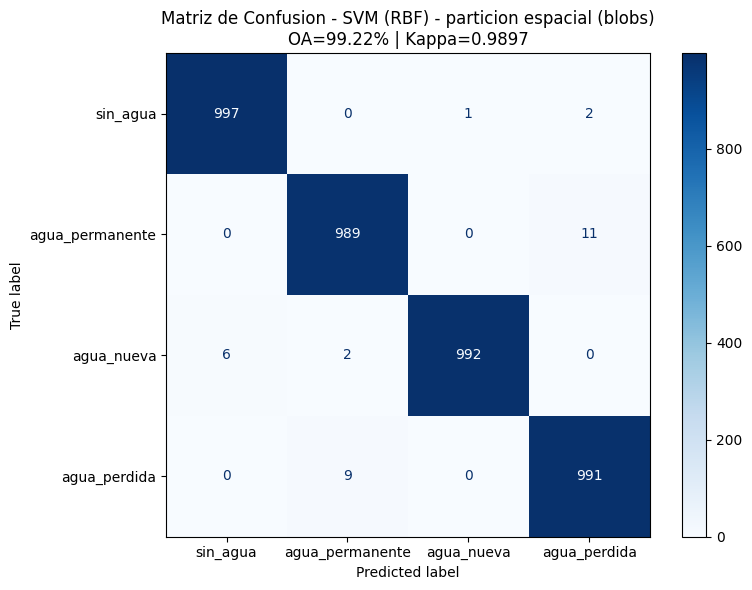

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_matriz_confusion.png


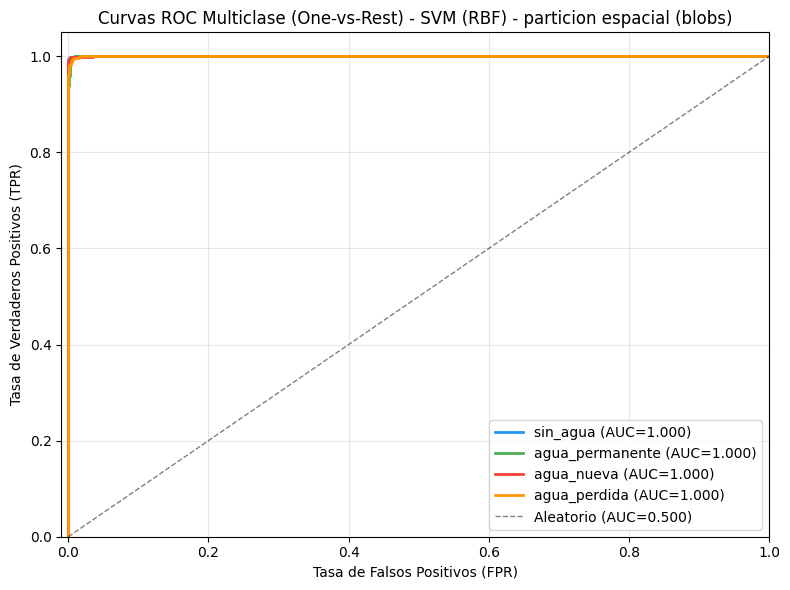

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_curvas_ROC.png

  Area Bajo la Curva (AUC) por clase:
    sin_agua: 1.0000
    agua_permanente: 0.9998
    agua_nueva: 1.0000
    agua_perdida: 0.9999
    Promedio (macro): 0.9999

  Calculando importancia por permutacion en el conjunto de testeo...
  Calculo completado en 19.7 segundos.

  Ranking de importancia por permutacion (caida media en accuracy):
     1. B11_post     0.2934 +/- 0.0022 ##################################################################################################################################################
     2. B11_pre      0.1328 +/- 0.0026 ##################################################################
     3. B12_pre      0.1208 +/- 0.0042 ############################################################
     4. B12_post     0.0414 +/- 0.0027 ####################
     5. B03_post     0.0193 +/- 0.0013 #########
     6. B09_post     0.0188 +/- 0.0023 #########
     7. B08_pre      0.

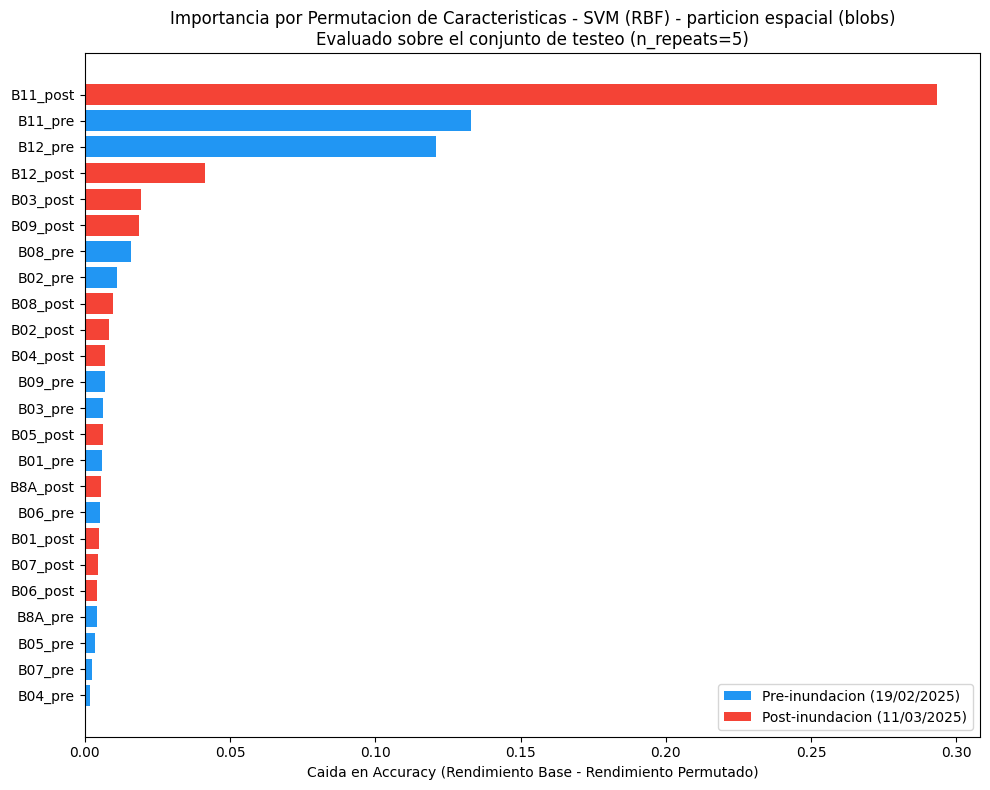

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_importancia_permutacion.png

[PASO 5] Exportando modelo y resultados...

  Modelo: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_mejor_modelo.pkl (0.1 MB)
  GridSearch: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_resultados_gridsearch.csv
  Predicciones: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_predicciones_testeo.csv
  Metricas: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_metricas_resumen.csv
  Importancias: /content/drive/MyDrive/sentinel_data/resultados_svm2/SVM_importancia_valores.csv

[PASO 6] Comparacion con el SVM de particion aleatoria (paso 10)...

  Metrica                      Paso 10 (random)   Este SVM (blobs)   Diferencia
  ------------------------------------------------------------------------------
  Overall Accuracy                       0.9945             0.9922      -0.0023
  Kappa de Cohen                         0.9927             0.9897      -

In [ ]:
"""
CLASIFICACION SUPERVISADA CON SUPPORT VECTOR MACHINE (SVM)
PARTICION ESPACIAL POR COMPONENTES CONEXAS (BLOBS)
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

Este script es la contraparte del paso 10) "Implementacion de SVM", que utiliza
como conjuntos de entrenamiento y testo a dos CSV creados en el paso 11)
y particionados espacialmente por componentes conexas.

ESTRUCTURA DEL PIPELINE:
  Paso 1: Carga de los CSV ya particionados (train_blobs / test_blobs)
  Paso 2: Verificacion de la particion
  Paso 3: Optimizacion de hiperparametros (C, gamma) con GridSearchCV sobre
          un Pipeline [StandardScaler -> SVC(rbf)] y CV estratificada de 5
          pliegues, submuestreando X_train con MAX_TUNING
  Paso 4: Evaluacion del mejor modelo (classification_report, matriz de
          confusion, Kappa, Accuracy, curvas ROC OvR con AUC) e importancia
          de variables por permutacion
  Paso 5: Exportacion del modelo (Pipeline con probability=True) y resultados
  Paso 6: Comparacion breve con los resultados del paso 10
          (particion aleatoria), si estan disponibles
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Montaje de Google Drive ---

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive montado correctamente.\n")
except ModuleNotFoundError:
    print("Aviso: no se esta en Google Colab; se omite el montaje de Drive.\n")
except Exception as e:
    print("Aviso: no se pudo montar Google Drive automaticamente: {}\n".format(e))

# --- Librerias ---
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    cohen_kappa_score, roc_curve, auc, ConfusionMatrixDisplay
)

# Semilla aleatoria para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Rutas
BASE_PATH = '/content/drive/MyDrive/sentinel_data'
RUTA_CSV_TRAIN = os.path.join(BASE_PATH, 'dataset_blobs', 'dataset_train_blobs.csv')
RUTA_CSV_TEST = os.path.join(BASE_PATH, 'dataset_blobs', 'dataset_test_blobs.csv')

CARPETA_SALIDA = os.path.join(BASE_PATH, 'resultados_svm2')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Carpeta del paso 10 (particion aleatoria) para la comparacion opcional
CARPETA_SALIDA_PASO10 = os.path.join(BASE_PATH, 'resultados_svm')

# Columnas auxiliares que no son features del modelo
COLUMNAS_AUXILIARES = ['row', 'col', 'region_id']
COLUMNA_TARGET = 'clase'

# Nombres de clases para visualizacion y reportes
CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

# -----------------------------------------------------------------------------
# CONTROL DE TIEMPO DE EJECUCION (MAX_TUNING)
# -----------------------------------------------------------------------------

MAX_TUNING = 6000

print("=" * 70)
print("  CLASIFICACION SUPERVISADA CON SVM - PARTICION ESPACIAL (BLOBS)")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 70)

# =============================================================================
# PASO 1: CARGA DE LOS CSV YA PARTICIONADOS (TRAIN_BLOBS / TEST_BLOBS)
# =============================================================================
# Carga directamente los dos CSV generados en el paso 11, que ya vienen
# particionados espacialmente por region (blob)
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 1] Cargando datasets ya particionados (CSV train / test)...\n")

for ruta, etiqueta in [(RUTA_CSV_TRAIN, 'train'), (RUTA_CSV_TEST, 'test')]:
    if not os.path.exists(ruta):
        print("  ERROR: no se encontro el archivo esperado ({}):".format(etiqueta))
        print("    {}\n".format(ruta))
        if not os.path.exists('/content/drive/MyDrive'):
            print("  Causa probable: Google Drive NO esta montado en esta sesion.")
        else:
            carpeta = os.path.dirname(ruta)
            if os.path.exists(carpeta):
                print("  La carpeta SI existe: {}".format(carpeta))
                print("  Contenido de la carpeta:")
                for item in sorted(os.listdir(carpeta)):
                    print("    - {}".format(item))
            else:
                print("  La carpeta NO existe: {}".format(carpeta))
                print("  (revise que el paso 11 se haya ejecutado y exportado el CSV)")
        raise FileNotFoundError(
            "No se encontro el dataset '{}'. Revise el diagnostico impreso "
            "mas arriba.".format(etiqueta))

df_train = pd.read_csv(RUTA_CSV_TRAIN)
df_test = pd.read_csv(RUTA_CSV_TEST)

print("  CSV train: {} -> {:,} filas x {} columnas".format(
    RUTA_CSV_TRAIN, df_train.shape[0], df_train.shape[1]))
print("  CSV test:  {} -> {:,} filas x {} columnas".format(
    RUTA_CSV_TEST, df_test.shape[0], df_test.shape[1]))

# --- Determinacion de las columnas de features, preservando el orden ---
# exacto en que aparecen en el CSV (Bxx_pre / Bxx_post intercalados por
# banda)
feature_names_train = [c for c in df_train.columns
                        if c not in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]]
feature_names_test = [c for c in df_test.columns
                       if c not in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]]

if feature_names_train != feature_names_test:
    raise ValueError(
        "Las columnas de features no coinciden (o no estan en el mismo "
        "orden) entre dataset_train_blobs.csv y dataset_test_blobs.csv.\n"
        "  train: {}\n  test:  {}".format(feature_names_train, feature_names_test))

feature_names = feature_names_train
print("\n  Features ({}), en el orden del CSV:".format(len(feature_names)))
print("    {}".format(', '.join(feature_names)))

for col in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]:
    if col not in df_train.columns or col not in df_test.columns:
        raise ValueError("Falta la columna esperada '{}' en alguno de los "
                          "dos CSV.".format(col))

# --- Arrays de trabajo: Ningun split train/test se realiza aqui ---
X_train = df_train[feature_names].values
y_train = df_train[COLUMNA_TARGET].values
coords_train = df_train[['row', 'col']].values
region_train = df_train['region_id'].values

X_test = df_test[feature_names].values
y_test = df_test[COLUMNA_TARGET].values
coords_test = df_test[['row', 'col']].values
region_test = df_test['region_id'].values

print("\n  X_train: shape={}, dtype={}".format(X_train.shape, X_train.dtype))
print("  X_test:  shape={}, dtype={}".format(X_test.shape, X_test.dtype))

# Distribucion de clases
print("\n  Distribucion de clases en train:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = int(np.sum(y_train == clase_id))
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y_train) * 100))

print("\n  Distribucion de clases en test:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = int(np.sum(y_test == clase_id))
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y_test) * 100))

# =============================================================================
# PASO 2: VERIFICACION DE LA PARTICION ESPACIAL
# =============================================================================
# Esta seccion solo confirma que no hay regiones (blobs) compartidas entre
# train y test, e informa la distancia minima real entre ambos conjuntos
# por clase, cuando se dispone de las coordenadas en pixeles Sentinel-2.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Verificacion de la particion espacial (train/test ya fijos)...\n")

regiones_compartidas = set(df_train['region_id']) & set(df_test['region_id'])
print("  Regiones (blobs) compartidas entre train y test: {}".format(
    len(regiones_compartidas)))
if regiones_compartidas:
    print("  ADVERTENCIA: se esperaba una asignacion exclusiva de regiones "
          "por conjunto (ver paso 11).")

try:
    from scipy.spatial import cKDTree
    RESOLUCION_M = 10.0  # Sentinel-2, 10 m/pixel
    print("\n  Distancia minima train-test por clase (verificacion, no altera "
          "la particion):")
    print("  {:<20} {:>14} {:>14}".format("Clase", "dist_min (px)", "dist_min (m)"))
    print("  " + "-" * 50)
    for clase_id, nombre in CLASE_NOMBRES.items():
        a = coords_train[y_train == clase_id]
        b = coords_test[y_test == clase_id]
        if len(a) == 0 or len(b) == 0:
            continue
        arbol = cKDTree(a.astype(np.float64))
        d_px = float(arbol.query(b.astype(np.float64), k=1)[0].min())
        print("  {:<20} {:>14.2f} {:>14.1f}".format(
            nombre, d_px, d_px * RESOLUCION_M))
except ImportError:
    print("  (scipy no disponible; se omite el calculo de distancia minima)")

print("\n  Confirmado: NO se aplica train_test_split entre train y test en "
      "este script. dataset_train_blobs.csv se usa integro como "
      "entrenamiento y dataset_test_blobs.csv integro como testeo.")

# =============================================================================
# PASO 3: OPTIMIZACION DE HIPERPARAMETROS (C, gamma) CON GRIDSEARCHCV (cv=5)
# =============================================================================
#   [1] StandardScaler -> estandariza las 24 features (media 0, desvio 1)
#   [2] SVC(kernel='rbf') -> clasificador no lineal, esquema One-Versus-One
#
# El unico split que se realiza en todo el script ocurre aqui, y es interno
# a X_train: un submuestreo estratificado para acotar
# el costo de GridSearchCV cuando X_train supera MAX_TUNING muestras.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 3] Optimizacion de hiperparametros con GridSearchCV...\n")

# Pipeline base: estandarizacion + SVM-RBF
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel='rbf',
        probability=False,
        decision_function_shape='ovr',
        class_weight=None,
        random_state=RANDOM_SEED
    ))
])

# Grilla de hiperparametros
parametros = {
    'svc__C':     [1, 10, 100],
    'svc__gamma': ['scale', 0.1, 1]
}

n_combinaciones = 1
for v in parametros.values():
    n_combinaciones *= len(v)

print("  Hiperparametros a evaluar:")
for param, valores in parametros.items():
    print("    {}: {}".format(param, valores))
print("  Total combinaciones: {}".format(n_combinaciones))
print("  Pliegues de validacion cruzada: 5 (estratificada)")
print("  Total entrenamientos: {}".format(n_combinaciones * 5))

if MAX_TUNING is not None and MAX_TUNING < X_train.shape[0]:
    frac = MAX_TUNING / X_train.shape[0]
    # Unico split del script: subdivision dentro de X_train para la busqueda
    # de hiperparametros. Nunca se toca X_test en esta operacion.
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train,
        train_size=frac,
        random_state=RANDOM_SEED,
        stratify=y_train
    )
    print("\n  MAX_TUNING activo: la busqueda usa {:,} de {:,} muestras "
          "(estratificadas, tomadas solo de X_train).".format(
              X_tune.shape[0], X_train.shape[0]))
else:
    X_tune, y_tune = X_train, y_train
    print("\n  MAX_TUNING desactivado: la busqueda usa todo X_train "
          "({:,} muestras).".format(X_train.shape[0]))

cv_estratificado = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Busqueda exhaustiva en grilla
busqueda = GridSearchCV(
    estimator=pipeline_base,
    param_grid=parametros,
    cv=cv_estratificado,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\n  Ejecutando busqueda ...")
t_inicio = time.time()
busqueda.fit(X_tune, y_tune)
t_total = time.time() - t_inicio

print("\n  Busqueda completada en {:.1f} segundos.".format(t_total))
print("\n  Mejores hiperparametros encontrados:")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("  Mejor accuracy en validacion cruzada: {:.4f}".format(
    busqueda.best_score_))

# Top 5 combinaciones
print("\n  Top 5 combinaciones:")
resultados_cv = pd.DataFrame(busqueda.cv_results_)
resultados_cv = resultados_cv.sort_values('rank_test_score')
for _, row in resultados_cv.head(5).iterrows():
    print("    #{}: accuracy={:.4f} | {}".format(
        int(row['rank_test_score']),
        row['mean_test_score'],
        row['params']))

# =============================================================================
# PASO 4: EVALUACION SOBRE EL CONJUNTO DE TESTEO (dataset_test_blobs.csv)
# =============================================================================
# Se construye el MODELO FINAL con los mejores hiperparametros.
# Se reentrena sobre el 100% de X_train (dataset_train_blobs.csv) y se
# evalua sobre X_test (dataset_test_blobs.csv), sin ninguna mezcla previa.
#
#   - Classification Report: Precision, Recall, F1-Score por clase
#   - Matriz de Confusion
#   - Overall Accuracy (OA)
#   - Kappa de Cohen
#   - Curvas ROC multiclase (One-vs-Rest) con Area Bajo la Curva (AUC)
#   - Importancia de variables por permutacion
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 4] Evaluacion sobre conjunto de testeo (particion espacial)...\n")

# Mejores hiperparametros hallados por la busqueda
mejor_C = busqueda.best_params_['svc__C']
mejor_gamma = busqueda.best_params_['svc__gamma']

# Modelo final
mejor_modelo = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel='rbf',
        C=mejor_C,
        gamma=mejor_gamma,
        probability=True,                  # habilita predict_proba (ROC)
        decision_function_shape='ovr',
        class_weight=None,
        random_state=RANDOM_SEED
    ))
])

print("  Reentrenando el mejor modelo sobre todo X_train "
      "(C={}, gamma={}, probability=True)...".format(mejor_C, mejor_gamma))
t0 = time.time()
mejor_modelo.fit(X_train, y_train)
print("  Reentrenamiento completado en {:.1f} segundos.".format(time.time() - t0))

# Predicciones y probabilidades sobre testeo
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)

# --- 4a. Overall Accuracy ---
oa = accuracy_score(y_test, y_pred)
print("\n  Overall Accuracy (OA): {:.4f} ({:.2f}%)".format(oa, oa * 100))

# --- 4b. Coeficiente Kappa de Cohen ---
kappa = cohen_kappa_score(y_test, y_pred)

if kappa > 0.81:
    interp_kappa = "casi perfecto"
elif kappa > 0.61:
    interp_kappa = "sustancial"
elif kappa > 0.41:
    interp_kappa = "moderado"
else:
    interp_kappa = "bajo"

print("  Coeficiente Kappa:     {:.4f} ({})".format(kappa, interp_kappa))

# --- 4c. Classification Report (Precision, Recall, F1-Score) ---
nombres_clases = [CLASE_NOMBRES[i] for i in sorted(CLASE_NOMBRES.keys())]

reporte = classification_report(
    y_test, y_pred,
    target_names=nombres_clases,
    digits=4
)
print("\n  Classification Report:")
print(reporte)

# --- 4d. Matriz de Confusion ---
cm = confusion_matrix(y_test, y_pred)
print("  Matriz de Confusion:")
print(cm)

# --- 4e. Visualizacion de la Matriz de Confusion ---
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nombres_clases
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Matriz de Confusion - SVM (RBF) - particion espacial (blobs)\n'
             'OA={:.2f}% | Kappa={:.4f}'.format(oa * 100, kappa))
plt.tight_layout()

ruta_cm = os.path.join(CARPETA_SALIDA, 'SVM_matriz_confusion.png')
plt.savefig(ruta_cm, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_cm))

# --- 4f. Curvas ROC Multiclase (One-vs-Rest) y Area Bajo la Curva ---

n_clases = len(CLASE_NOMBRES)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))
colores = ['#2196F3', '#4CAF50', '#F44336', '#FF9800']

auc_por_clase = {}
for i in range(n_clases):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    auc_por_clase[nombres_clases[i]] = auc_i
    ax.plot(fpr_i, tpr_i, color=colores[i], lw=2,
            label='{} (AUC={:.3f})'.format(nombres_clases[i], auc_i))

# Linea de referencia del clasificador aleatorio
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5,
        label='Aleatorio (AUC=0.500)')

ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) - SVM (RBF) - '
             'particion espacial (blobs)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(CARPETA_SALIDA, 'SVM_curvas_ROC.png')
plt.savefig(ruta_roc, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_roc))

# Resumen de AUC por clase
print("\n  Area Bajo la Curva (AUC) por clase:")
for nombre, auc_val in auc_por_clase.items():
    print("    {}: {:.4f}".format(nombre, auc_val))
auc_promedio = np.mean(list(auc_por_clase.values()))
print("    Promedio (macro): {:.4f}".format(auc_promedio))

# --- 4g. Importancia de Variables por Permutacion ---

print("\n  Calculando importancia por permutacion en el conjunto de testeo...")
t_perm = time.time()
resultado_perm = permutation_importance(
    mejor_modelo,
    X_test,
    y_test,
    n_repeats=5,
    scoring='accuracy',
    random_state=RANDOM_SEED,
    n_jobs=-1
)
print("  Calculo completado en {:.1f} segundos.".format(time.time() - t_perm))

# Tabla de importancias ordenada de mayor a menor (para tabla y CSV)
df_importancia = pd.DataFrame({
    'feature': feature_names,
    'importancia_media': resultado_perm.importances_mean,
    'desviacion_estandar': resultado_perm.importances_std
}).sort_values('importancia_media', ascending=False).reset_index(drop=True)

print("\n  Ranking de importancia por permutacion (caida media en accuracy):")
for i, row in df_importancia.iterrows():
    barra = '#' * int(max(row['importancia_media'], 0) * 500)
    print("    {:2d}. {:<12} {:.4f} +/- {:.4f} {}".format(
        i + 1, row['feature'], row['importancia_media'],
        row['desviacion_estandar'], barra))

# Visualizacion: barras horizontales coloreadas por periodo
df_plot = df_importancia.sort_values('importancia_media', ascending=True)

# Azul para pre-inundacion, rojo para post-inundacion
colores_barras = []
for feat in df_plot['feature']:
    if feat.endswith('_pre'):
        colores_barras.append('#2196F3')
    else:
        colores_barras.append('#F44336')

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(df_plot)), df_plot['importancia_media'], color=colores_barras)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['feature'])
ax.set_xlabel('Caida en Accuracy (Rendimiento Base - Rendimiento Permutado)')
ax.set_title('Importancia por Permutacion de Caracteristicas - SVM (RBF) - '
             'particion espacial (blobs)\n'
             'Evaluado sobre el conjunto de testeo (n_repeats=5)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='Pre-inundacion (19/02/2025)'),
    Patch(facecolor='#F44336', label='Post-inundacion (11/03/2025)')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()

ruta_importancia_img = os.path.join(CARPETA_SALIDA, 'SVM_importancia_permutacion.png')
plt.savefig(ruta_importancia_img, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_importancia_img))

# =============================================================================
# PASO 5: EXPORTACION DEL MODELO Y RESULTADOS
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Exportando modelo y resultados...\n")

# 5a. Modelo entrenado (.pkl) con joblib -> Pipeline (scaler + SVC)
ruta_modelo = os.path.join(CARPETA_SALIDA, 'SVM_mejor_modelo.pkl')
joblib.dump(mejor_modelo, ruta_modelo)
tamano_modelo = os.path.getsize(ruta_modelo) / (1024 * 1024)
print("  Modelo: {} ({:.1f} MB)".format(ruta_modelo, tamano_modelo))

# 5b. Resultados de GridSearchCV (.csv)
ruta_cv = os.path.join(CARPETA_SALIDA, 'SVM_resultados_gridsearch.csv')
resultados_cv.to_csv(ruta_cv, index=False)
print("  GridSearch: {}".format(ruta_cv))

# 5c. Predicciones sobre testeo con coordenadas y region_id (.csv)
# region_id se conserva como columna informativa (auxiliar), no se uso como
# input del modelo.
df_predicciones = pd.DataFrame({
    'row': coords_test[:, 0],
    'col': coords_test[:, 1],
    'region_id': region_test,
    'clase_real': y_test,
    'clase_predicha': y_pred,
    'correcto': (y_test == y_pred).astype(int)
})
# Agregar probabilidades predichas por clase
for clase_id, nombre in CLASE_NOMBRES.items():
    df_predicciones['prob_{}'.format(nombre)] = y_proba[:, clase_id]

ruta_pred = os.path.join(CARPETA_SALIDA, 'SVM_predicciones_testeo.csv')
df_predicciones.to_csv(ruta_pred, index=False)
print("  Predicciones: {}".format(ruta_pred))

# 5d. Resumen de metricas (.csv)
metricas = {
    'Overall_Accuracy': [oa],
    'Kappa': [kappa],
    'AUC_macro': [auc_promedio],
    'C': [mejor_C],
    'gamma': [str(mejor_gamma)],
    'kernel': ['rbf'],
    'CV_best_score': [busqueda.best_score_],
    'train_samples': [X_train.shape[0]],
    'test_samples': [X_test.shape[0]],
    'n_features': [X_train.shape[1]],
    'tuning_samples': [X_tune.shape[0]],
    'random_seed': [RANDOM_SEED],
    'tiempo_gridsearch_seg': [round(t_total, 1)],
    'particion': ['espacial_blobs'],
    'buffer_objetivo_m': [200]
}
df_metricas = pd.DataFrame(metricas)
ruta_metricas = os.path.join(CARPETA_SALIDA, 'SVM_metricas_resumen.csv')
df_metricas.to_csv(ruta_metricas, index=False)
print("  Metricas: {}".format(ruta_metricas))

# 5e. Valores de importancia por permutacion (.csv)
ruta_importancia_csv = os.path.join(CARPETA_SALIDA, 'SVM_importancia_valores.csv')
df_importancia.to_csv(ruta_importancia_csv, index=False)
print("  Importancias: {}".format(ruta_importancia_csv))

# =============================================================================
# PASO 6: COMPARACION CON EL SVM DEL PASO 10 (PARTICION ALEATORIA)
# =============================================================================
# Se comparan los resultados del paso 10 en cuanto a Overall Accuracy, Kappa
# y AUC macro.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 6] Comparacion con el SVM de particion aleatoria (paso 10)...\n")

ruta_metricas_paso10 = os.path.join(CARPETA_SALIDA_PASO10, 'SVM_metricas_resumen.csv')

if os.path.exists(ruta_metricas_paso10):
    df_metricas_paso10 = pd.read_csv(ruta_metricas_paso10)
    oa_10 = float(df_metricas_paso10['Overall_Accuracy'].iloc[0])
    kappa_10 = float(df_metricas_paso10['Kappa'].iloc[0])
    auc_10 = float(df_metricas_paso10['AUC_macro'].iloc[0])

    oa_2 = float(oa)
    kappa_2 = float(kappa)
    auc_2 = float(auc_promedio)

    print("  {:<28} {:>16} {:>18} {:>12}".format(
        "Metrica", "Paso 10 (random)", "Este SVM (blobs)", "Diferencia"))
    print("  " + "-" * 78)
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "Overall Accuracy", oa_10, oa_2, oa_2 - oa_10))
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "Kappa de Cohen", kappa_10, kappa_2, kappa_2 - kappa_10))
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "AUC macro", auc_10, auc_2, auc_2 - auc_10))

    print("\n  Interpretacion:")
    if oa_2 < oa_10 or kappa_2 < kappa_10 or auc_2 < auc_10:
        print("    El desempeno bajo al controlar la autocorrelacion espacial "
              "(particion por blobs con buffer >= 200 m)")
    else:
        print("    El desempeno se mantuvo estable o mejoro respecto de la "
              "particion aleatoria del paso 10")

    df_comparacion = pd.DataFrame({
        'metrica': ['Overall_Accuracy', 'Kappa', 'AUC_macro'],
        'paso10_particion_aleatoria': [oa_10, kappa_10, auc_10],
        'svm2_particion_espacial_blobs': [oa_2, kappa_2, auc_2],
        'diferencia': [oa_2 - oa_10, kappa_2 - kappa_10, auc_2 - auc_10]
    })
    ruta_comparacion = os.path.join(
        CARPETA_SALIDA, 'SVM_comparacion_random_vs_espacial.csv')
    df_comparacion.to_csv(ruta_comparacion, index=False)
    print("\n  Comparacion exportada: {}".format(ruta_comparacion))
else:
    print("  No se encontro {} (resultados del paso 10).".format(
        ruta_metricas_paso10))
    print("  Se omite la comparacion. Ejecute primero el paso 10 si desea "
          "contrastar ambos esquemas de particion.")

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN DEL MODELO SVM (RBF) - PARTICION ESPACIAL (BLOBS)")
print("=" * 70 + "\n")

print("  Datos:")
print("    Entrenamiento:     {:,} muestras (dataset_train_blobs.csv)".format(
    X_train.shape[0]))
print("    Testeo:            {:,} muestras (dataset_test_blobs.csv)".format(
    X_test.shape[0]))
print("    Division:          por regiones/blobs, exclusiva por conjunto, "
      "buffer objetivo >= 200 m")
print("    Preprocesamiento:  StandardScaler dentro del Pipeline (sin leakage)")
print()
print("  Hiperparametros optimos (GridSearchCV, cv=5 estratificada, "
      "MAX_TUNING={:,}):".format(MAX_TUNING))
print("    C: {}".format(mejor_C))
print("    gamma: {}".format(mejor_gamma))
print("    Accuracy en CV: {:.4f}".format(busqueda.best_score_))
print()
print("  Evaluacion sobre testeo:")
print("    Overall Accuracy: {:.4f} ({:.2f}%)".format(oa, oa * 100))
print("    Kappa de Cohen:   {:.4f} ({})".format(kappa, interp_kappa))
print("    AUC promedio:     {:.4f}".format(auc_promedio))
print()
print("  Variable mas importante (permutacion): {} ({:.4f})".format(
    df_importancia.iloc[0]['feature'], df_importancia.iloc[0]['importancia_media']))
print()
print("  Archivos generados en {}:".format(CARPETA_SALIDA))
print("    -> SVM_mejor_modelo.pkl (Pipeline scaler+SVC exportado con joblib)")
print("    -> SVM_resultados_gridsearch.csv")
print("    -> SVM_predicciones_testeo.csv")
print("    -> SVM_metricas_resumen.csv")
print("    -> SVM_importancia_valores.csv")
print("    -> SVM_matriz_confusion.png")
print("    -> SVM_curvas_ROC.png")
print("    -> SVM_importancia_permutacion.png")
if os.path.exists(ruta_metricas_paso10):
    print("    -> SVM_comparacion_random_vs_espacial.csv (comparacion con paso 10)")

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)

## 13) Segunda implementación de RF

Replicación de la operacionalización previa de RF, cambiando el conjunto de datos por el dataframe que realiza una separación espacial entre entrenamiento y prueba.


Mounted at /content/drive
Google Drive montado correctamente.

  CLASIFICACION SUPERVISADA CON RANDOM FOREST - PARTICION ESPACIAL
  Inundacion de Bahia Blanca - 7 de marzo de 2025

[PASO 1] Cargando datasets ya particionados (CSV train / test)...

  CSV train: /content/drive/MyDrive/sentinel_data/dataset_blobs/dataset_train_blobs.csv -> 16,000 filas x 28 columnas
  CSV test:  /content/drive/MyDrive/sentinel_data/dataset_blobs/dataset_test_blobs.csv -> 4,000 filas x 28 columnas

  Features (24), en el orden del CSV:
    B01_pre, B01_post, B02_pre, B02_post, B03_pre, B03_post, B04_pre, B04_post, B05_pre, B05_post, B06_pre, B06_post, B07_pre, B07_post, B08_pre, B08_post, B8A_pre, B8A_post, B09_pre, B09_post, B11_pre, B11_post, B12_pre, B12_post

  X_train: shape=(16000, 24), dtype=float64
  X_test:  shape=(4000, 24), dtype=float64

  Distribucion de clases en train:
    Clase 0 (sin_agua): 4,000 (25.0%)
    Clase 1 (agua_permanente): 4,000 (25.0%)
    Clase 2 (agua_nueva): 4,000 (25.0%)
 

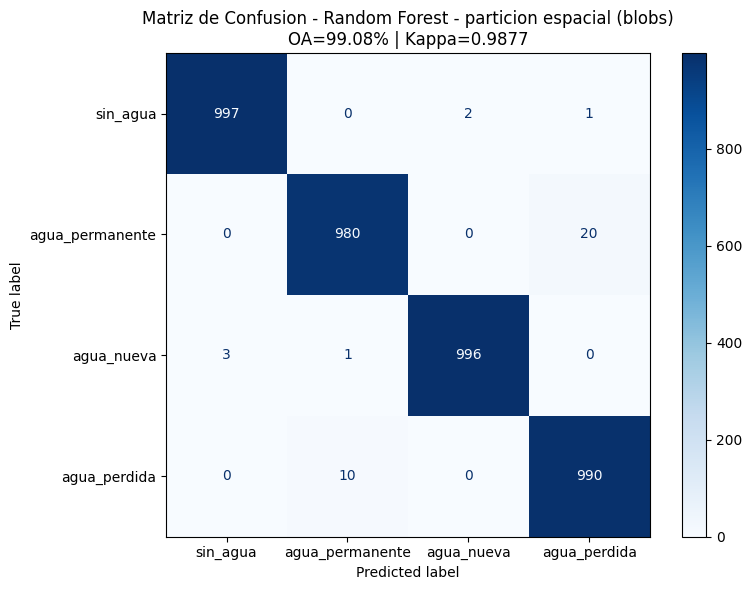

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_matriz_confusion.png


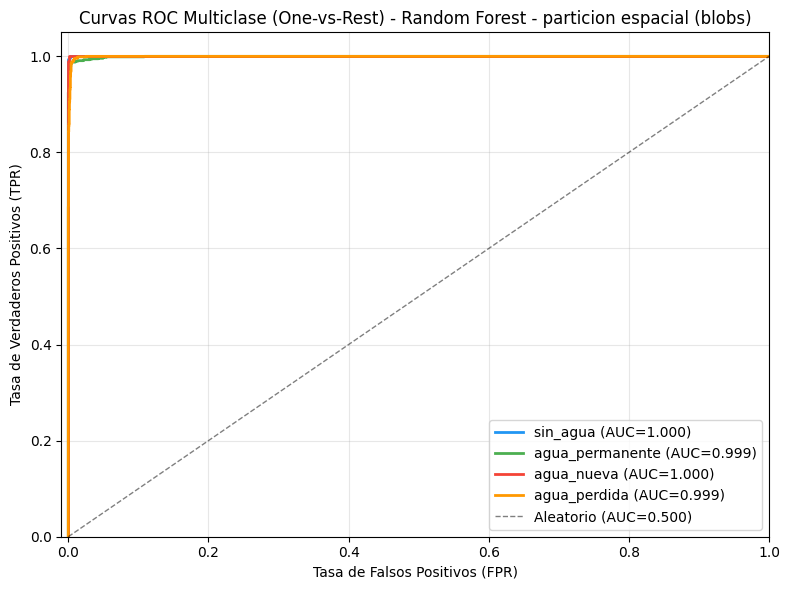

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_curvas_ROC.png

  Area Bajo la Curva (AUC) por clase:
    sin_agua: 1.0000
    agua_permanente: 0.9995
    agua_nueva: 1.0000
    agua_perdida: 0.9995
    Promedio (macro): 0.9997

[PASO 5] Analisis de importancia de features...

  Ranking de importancia de features:
     1. B11_post     0.1820 ##################
     2. B12_post     0.1470 ##############
     3. B11_pre      0.0889 ########
     4. B09_post     0.0662 ######
     5. B09_pre      0.0615 ######
     6. B8A_post     0.0608 ######
     7. B07_pre      0.0530 #####
     8. B8A_pre      0.0502 #####
     9. B12_pre      0.0453 ####
    10. B08_post     0.0442 ####
    11. B06_pre      0.0308 ###
    12. B08_pre      0.0295 ##
    13. B05_pre      0.0259 ##
    14. B07_post     0.0236 ##
    15. B01_pre      0.0199 #
    16. B06_post     0.0170 #
    17. B02_pre      0.0116 #
    18. B04_pre      0.0087 
    19. B05_post     0.0076 
    20. B03_post     0.007

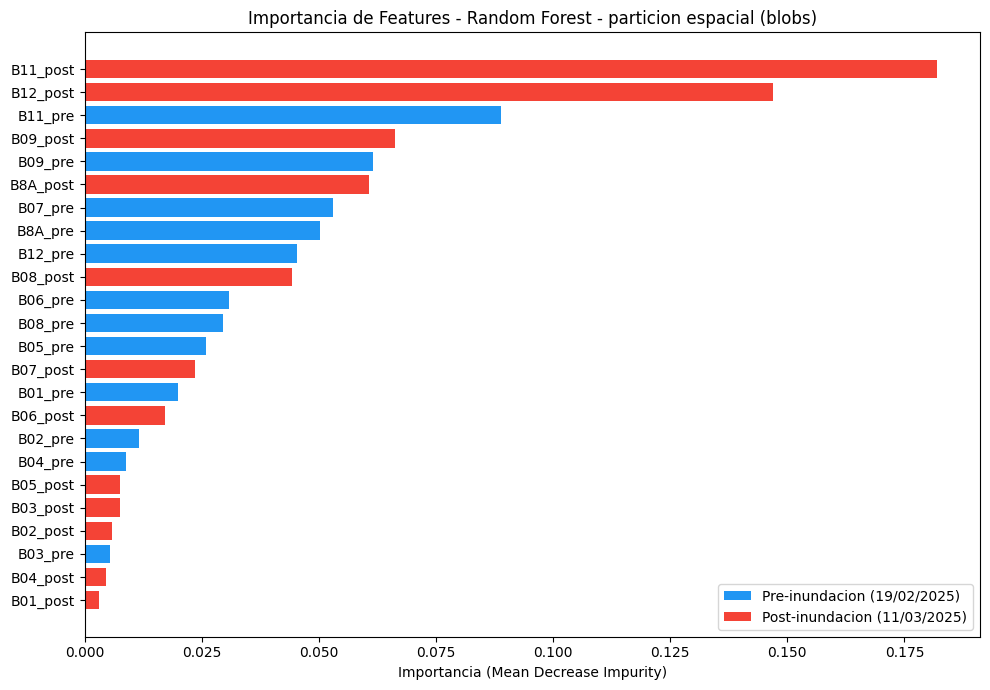

  Guardada: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_importancia_features.png

  Importancia agregada por periodo:
    Pre-inundacion:  0.4306 (43.1%)
    Post-inundacion: 0.5694 (56.9%)

[PASO 6] Exportando modelo y resultados...

  Modelo: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_mejor_modelo.pkl (2.1 MB)
  GridSearch: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_resultados_gridsearch.csv
  Importancias: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_importancia_features.csv
  Predicciones: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_predicciones_testeo.csv
  Metricas: /content/drive/MyDrive/sentinel_data/resultados_rf2/RF_metricas_resumen.csv

[PASO 7] Comparacion con el RF de particion aleatoria (paso 9)...

  Fuente paso 9: /content/drive/MyDrive/sentinel_data/resultados_rf/RF_metricas_resumen.csv

  Metrica                       Paso 9 (random)    Este RF (blobs)   Diferencia
  ----------------------------------------------

In [ ]:
"""
CLASIFICACION SUPERVISADA CON RANDOM FOREST
PARTICION ESPACIAL POR COMPONENTES CONEXAS (BLOBS)
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

ESTRUCTURA DEL PIPELINE:
  Paso 1: Carga de los CSV ya particionados (train_blobs / test_blobs)
  Paso 2: Verificacion de la particion (no se vuelve a dividir nada)
  Paso 3: Optimizacion de hiperparametros con GridSearchCV (cv=5 estratificada)
          sobre n_estimators, max_depth y min_samples_split
  Paso 4: Evaluacion (classification_report, matriz de confusion,
          Kappa, Accuracy, Precision, Recall, F1, curvas ROC con AUC)
  Paso 5: Analisis de importancia de features (feature_importances_)
  Paso 6: Exportacion del modelo con joblib y de los resultados
  Paso 7 (opcional): Comparacion breve con los resultados del paso 9
          (particion aleatoria)
"""

# =============================================================================
# CONFIGURACION INICIAL
# =============================================================================

# --- Montaje de Google Drive ---

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive montado correctamente.\n")
except ModuleNotFoundError:
    print("Aviso: no se esta en Google Colab; se omite el montaje de Drive.\n")
except Exception as e:
    print("Aviso: no se pudo montar Google Drive automaticamente: {}\n".format(e))

# --- Librerias ---
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    cohen_kappa_score, roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

# Semilla aleatoria para reproducibilidad
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Rutas
BASE_PATH = '/content/drive/MyDrive/sentinel_data'
RUTA_CSV_TRAIN = os.path.join(BASE_PATH, 'dataset_blobs', 'dataset_train_blobs.csv')
RUTA_CSV_TEST = os.path.join(BASE_PATH, 'dataset_blobs', 'dataset_test_blobs.csv')

CARPETA_SALIDA = os.path.join(BASE_PATH, 'resultados_rf2')
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# Carpeta del paso 9 (particion aleatoria), para la comparacion final
CARPETA_SALIDA_PASO9 = os.path.join(BASE_PATH, 'resultados_rf')

# Columnas auxiliares que no son features del modelo
COLUMNAS_AUXILIARES = ['row', 'col', 'region_id']
COLUMNA_TARGET = 'clase'

# Nombres de clases para visualizacion y reportes
CLASE_NOMBRES = {
    0: 'sin_agua',
    1: 'agua_permanente',
    2: 'agua_nueva',
    3: 'agua_perdida'
}

print("=" * 70)
print("  CLASIFICACION SUPERVISADA CON RANDOM FOREST - PARTICION ESPACIAL")
print("  Inundacion de Bahia Blanca - 7 de marzo de 2025")
print("=" * 70)

# =============================================================================
# PASO 1: CARGA DE LOS CSV YA PARTICIONADOS (TRAIN_BLOBS / TEST_BLOBS)
# =============================================================================
# A diferencia del paso 9 (NPZ + train_test_split 80/20 aleatorio), aqui se
# cargan directamente los dos CSV generados en el paso 11, que ya vienen
# particionados espacialmente por region (blob): No se debe volver a mezclar
# ni redividir train y test en ningun punto de este script.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 1] Cargando datasets ya particionados (CSV train / test)...\n")

for ruta, etiqueta in [(RUTA_CSV_TRAIN, 'train'), (RUTA_CSV_TEST, 'test')]:
    if not os.path.exists(ruta):
        print("  ERROR: no se encontro el archivo esperado ({}):".format(etiqueta))
        print("    {}\n".format(ruta))
        if not os.path.exists('/content/drive/MyDrive'):
            print("  Causa probable: Google Drive NO esta montado en esta sesion.")
        else:
            carpeta = os.path.dirname(ruta)
            if os.path.exists(carpeta):
                print("  La carpeta SI existe: {}".format(carpeta))
                print("  Contenido de la carpeta:")
                for item in sorted(os.listdir(carpeta)):
                    print("    - {}".format(item))
            else:
                print("  La carpeta NO existe: {}".format(carpeta))
                print("  (revise que el paso 11 se haya ejecutado y exportado el CSV)")
        raise FileNotFoundError(
            "No se encontro el dataset '{}'. Revise el diagnostico impreso "
            "mas arriba.".format(etiqueta))

df_train = pd.read_csv(RUTA_CSV_TRAIN)
df_test = pd.read_csv(RUTA_CSV_TEST)

print("  CSV train: {} -> {:,} filas x {} columnas".format(
    RUTA_CSV_TRAIN, df_train.shape[0], df_train.shape[1]))
print("  CSV test:  {} -> {:,} filas x {} columnas".format(
    RUTA_CSV_TEST, df_test.shape[0], df_test.shape[1]))

# --- Determinacion de las columnas de features, preservando el orden ---
# exacto en que aparecen en el CSV (Bxx_pre / Bxx_post intercalados por
# banda).
feature_names_train = [c for c in df_train.columns
                        if c not in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]]
feature_names_test = [c for c in df_test.columns
                       if c not in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]]

if feature_names_train != feature_names_test:
    raise ValueError(
        "Las columnas de features no coinciden (o no estan en el mismo "
        "orden) entre dataset_train_blobs.csv y dataset_test_blobs.csv.\n"
        "  train: {}\n  test:  {}".format(feature_names_train, feature_names_test))

feature_names = feature_names_train
print("\n  Features ({}), en el orden del CSV:".format(len(feature_names)))
print("    {}".format(', '.join(feature_names)))

for col in COLUMNAS_AUXILIARES + [COLUMNA_TARGET]:
    if col not in df_train.columns or col not in df_test.columns:
        raise ValueError("Falta la columna esperada '{}' en alguno de los "
                          "dos CSV.".format(col))

# --- Arrays de trabajo: Ningun split train/test se realiza aqui ---
X_train = df_train[feature_names].values
y_train = df_train[COLUMNA_TARGET].values
coords_train = df_train[['row', 'col']].values
region_train = df_train['region_id'].values

X_test = df_test[feature_names].values
y_test = df_test[COLUMNA_TARGET].values
coords_test = df_test[['row', 'col']].values
region_test = df_test['region_id'].values

print("\n  X_train: shape={}, dtype={}".format(X_train.shape, X_train.dtype))
print("  X_test:  shape={}, dtype={}".format(X_test.shape, X_test.dtype))

# Distribucion de clases
print("\n  Distribucion de clases en train:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = int(np.sum(y_train == clase_id))
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y_train) * 100))

print("\n  Distribucion de clases en test:")
for clase_id, nombre in CLASE_NOMBRES.items():
    n = int(np.sum(y_test == clase_id))
    print("    Clase {} ({}): {:,} ({:.1f}%)".format(
        clase_id, nombre, n, n / len(y_test) * 100))

# =============================================================================
# PASO 2: VERIFICACION DE LA PARTICION ESPACIAL (SIN VOLVER A DIVIDIR NADA)
# =============================================================================
# Esta seccion solo audita la particion ya realizada en el paso 11: confirma
# que no hay regiones (blobs) compartidas entre train y test, e informa la
# distancia minima real entre ambos conjuntos por clase, en pixeles
# Sentinel-2 (10 m/px).
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 2] Verificacion de la particion espacial (train/test ya fijos)...\n")

regiones_compartidas = set(df_train['region_id']) & set(df_test['region_id'])
print("  Regiones (blobs) compartidas entre train y test: {}".format(
    len(regiones_compartidas)))
if regiones_compartidas:
    print("  ADVERTENCIA: se esperaba una asignacion exclusiva de regiones "
          "por conjunto (ver paso 11).")

try:
    from scipy.spatial import cKDTree
    RESOLUCION_M = 10.0  # Sentinel-2, 10 m/pixel
    print("\n  Distancia minima train-test por clase (verificacion, no altera "
          "la particion):")
    print("  {:<20} {:>14} {:>14}".format("Clase", "dist_min (px)", "dist_min (m)"))
    print("  " + "-" * 50)
    for clase_id, nombre in CLASE_NOMBRES.items():
        a = coords_train[y_train == clase_id]
        b = coords_test[y_test == clase_id]
        if len(a) == 0 or len(b) == 0:
            continue
        arbol = cKDTree(a.astype(np.float64))
        d_px = float(arbol.query(b.astype(np.float64), k=1)[0].min())
        print("  {:<20} {:>14.2f} {:>14.1f}".format(
            nombre, d_px, d_px * RESOLUCION_M))
except ImportError:
    print("  (scipy no disponible; se omite el calculo de distancia minima)")

print("\n  Confirmado: NO se aplica train_test_split en este script. "
      "dataset_train_blobs.csv se usa integro como entrenamiento y "
      "dataset_test_blobs.csv integro como testeo.")

# =============================================================================
# PASO 3: OPTIMIZACION DE HIPERPARAMETROS CON GRIDSEARCHCV (cv=5)
# =============================================================================
# Misma grilla que en el paso 9, evaluada mediante validacion cruzada
# estratificada de 5 pliegues sobre el conjunto de entrenamiento:
#
#   - n_estimators: cantidad de arboles en el bosque [50, 100, 200]
#   - max_depth: profundidad maxima de cada arbol [10, 20, None]
#   - min_samples_split: muestras minimas para dividir un nodo [2, 5, 10]
#
# Total de entrenamientos: 27 combinaciones x 5 pliegues = 135.
#
# scoring='accuracy'
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 3] Optimizacion de hiperparametros con GridSearchCV...\n")

# Grilla de hiperparametros (identica al paso 9)
parametros = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

n_combinaciones = 1
for v in parametros.values():
    n_combinaciones *= len(v)

print("  Hiperparametros a evaluar:")
for param, valores in parametros.items():
    print("    {}: {}".format(param, valores))
print("  Total combinaciones: {}".format(n_combinaciones))
print("  Pliegues de validacion cruzada: 5 (estratificada)")
print("  Total entrenamientos: {}".format(n_combinaciones * 5))

# Modelo base
modelo_base = RandomForestClassifier(random_state=RANDOM_SEED)

# Validacion cruzada estratificada de 5 pliegues
cv_estratificado = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Busqueda exhaustiva
busqueda = GridSearchCV(
    estimator=modelo_base,
    param_grid=parametros,
    cv=cv_estratificado,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\n  Ejecutando busqueda (esto puede tomar varios minutos)...")
t_inicio = time.time()
busqueda.fit(X_train, y_train)
t_total = time.time() - t_inicio

print("\n  Busqueda completada en {:.1f} segundos.".format(t_total))
print("\n  Mejores hiperparametros encontrados:")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("  Mejor accuracy en validacion cruzada: {:.4f}".format(
    busqueda.best_score_))

# Top 5 combinaciones
print("\n  Top 5 combinaciones:")
resultados_cv = pd.DataFrame(busqueda.cv_results_)
resultados_cv = resultados_cv.sort_values('rank_test_score')
for _, row in resultados_cv.head(5).iterrows():
    print("    #{}: accuracy={:.4f} | {}".format(
        int(row['rank_test_score']),
        row['mean_test_score'],
        row['params']))

# =============================================================================
# PASO 4: EVALUACION SOBRE EL CONJUNTO DE TESTEO (dataset_test_blobs.csv)
# =============================================================================
# Se evalua el mejor modelo encontrado sobre el conjunto de testeo
# espacialmente independiente, que nunca participo en entrenamiento ni en
# validacion cruzada.
#
#   - Classification Report: Precision, Recall, F1-Score por clase
#   - Matriz de Confusion
#   - Overall Accuracy (OA): proporcion total de aciertos
#   - Kappa de Cohen
#   - Curvas ROC multiclase (One-vs-Rest) con Area Bajo la Curva (AUC)
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 4] Evaluacion sobre conjunto de testeo (particion espacial)...\n")

# Extraer el mejor modelo de la busqueda
mejor_modelo = busqueda.best_estimator_

# Predicciones sobre testeo
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)

# --- 4a. Overall Accuracy ---
oa = accuracy_score(y_test, y_pred)
print("  Overall Accuracy (OA): {:.4f} ({:.2f}%)".format(oa, oa * 100))

# --- 4b. Coeficiente Kappa de Cohen ---

kappa = cohen_kappa_score(y_test, y_pred)

if kappa > 0.81:
    interp_kappa = "casi perfecto"
elif kappa > 0.61:
    interp_kappa = "sustancial"
elif kappa > 0.41:
    interp_kappa = "moderado"
else:
    interp_kappa = "bajo"

print("  Coeficiente Kappa:     {:.4f} ({})".format(kappa, interp_kappa))

# --- 4c. Classification Report (Precision, Recall, F1-Score) ---

nombres_clases = [CLASE_NOMBRES[i] for i in sorted(CLASE_NOMBRES.keys())]

reporte = classification_report(
    y_test, y_pred,
    target_names=nombres_clases,
    digits=4
)
print("\n  Classification Report:")
print(reporte)

# --- 4d. Matriz de Confusion ---

cm = confusion_matrix(y_test, y_pred)
print("  Matriz de Confusion:")
print(cm)

# --- 4e. Visualizacion de la Matriz de Confusion ---
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nombres_clases
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Matriz de Confusion - Random Forest - particion espacial (blobs)\n'
             'OA={:.2f}% | Kappa={:.4f}'.format(oa * 100, kappa))
plt.tight_layout()

ruta_cm = os.path.join(CARPETA_SALIDA, 'RF_matriz_confusion.png')
plt.savefig(ruta_cm, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_cm))

# --- 4f. Curvas ROC Multiclase (One-vs-Rest) y Area Bajo la Curva ---

n_clases = len(CLASE_NOMBRES)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))
colores = ['#2196F3', '#4CAF50', '#F44336', '#FF9800']

auc_por_clase = {}
for i in range(n_clases):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    auc_por_clase[nombres_clases[i]] = auc_i
    ax.plot(fpr_i, tpr_i, color=colores[i], lw=2,
            label='{} (AUC={:.3f})'.format(nombres_clases[i], auc_i))

# Linea de referencia del clasificador aleatorio
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5,
        label='Aleatorio (AUC=0.500)')

ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) - Random Forest - '
             'particion espacial (blobs)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()

ruta_roc = os.path.join(CARPETA_SALIDA, 'RF_curvas_ROC.png')
plt.savefig(ruta_roc, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_roc))

# Resumen de AUC por clase
print("\n  Area Bajo la Curva (AUC) por clase:")
for nombre, auc_val in auc_por_clase.items():
    print("    {}: {:.4f}".format(nombre, auc_val))
auc_promedio = np.mean(list(auc_por_clase.values()))
print("    Promedio (macro): {:.4f}".format(auc_promedio))

# =============================================================================
# PASO 5: ANALISIS DE IMPORTANCIA DE FEATURES
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 5] Analisis de importancia de features...\n")

importancias = mejor_modelo.feature_importances_

# Tabla ordenada de mayor a menor importancia
df_importancias = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': importancias
}).sort_values('Importancia', ascending=False)

print("  Ranking de importancia de features:")
for i, (_, row) in enumerate(df_importancias.iterrows(), 1):
    barra = '#' * int(row['Importancia'] * 100)
    print("    {:2d}. {:<12} {:.4f} {}".format(
        i, row['Feature'], row['Importancia'], barra))

# Visualizacion con barras horizontales coloreadas por periodo
fig, ax = plt.subplots(figsize=(10, 7))
df_plot = df_importancias.sort_values('Importancia', ascending=True)

# Azul para pre-inundacion, rojo para post-inundacion
colores_barras = []
for feat in df_plot['Feature']:
    if feat.endswith('_pre'):
        colores_barras.append('#2196F3')
    else:
        colores_barras.append('#F44336')

ax.barh(range(len(df_plot)), df_plot['Importancia'], color=colores_barras)
ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['Feature'])
ax.set_xlabel('Importancia (Mean Decrease Impurity)')
ax.set_title('Importancia de Features - Random Forest - '
             'particion espacial (blobs)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2196F3', label='Pre-inundacion (19/02/2025)'),
    Patch(facecolor='#F44336', label='Post-inundacion (11/03/2025)')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()

ruta_imp = os.path.join(CARPETA_SALIDA, 'RF_importancia_features.png')
plt.savefig(ruta_imp, dpi=150, bbox_inches='tight')
plt.show()
print("  Guardada: {}".format(ruta_imp))

# Importancia agregada por periodo
imp_pre = df_importancias[
    df_importancias['Feature'].str.endswith('_pre')]['Importancia'].sum()
imp_post = df_importancias[
    df_importancias['Feature'].str.endswith('_post')]['Importancia'].sum()
print("\n  Importancia agregada por periodo:")
print("    Pre-inundacion:  {:.4f} ({:.1f}%)".format(imp_pre, imp_pre * 100))
print("    Post-inundacion: {:.4f} ({:.1f}%)".format(imp_post, imp_post * 100))

# =============================================================================
# PASO 6: EXPORTACION DEL MODELO Y RESULTADOS
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 6] Exportando modelo y resultados...\n")

# 6a. Modelo entrenado (.pkl) con joblib
ruta_modelo = os.path.join(CARPETA_SALIDA, 'RF_mejor_modelo.pkl')
joblib.dump(mejor_modelo, ruta_modelo)
tamano_modelo = os.path.getsize(ruta_modelo) / (1024 * 1024)
print("  Modelo: {} ({:.1f} MB)".format(ruta_modelo, tamano_modelo))

# 6b. Resultados de GridSearchCV (.csv)
ruta_cv = os.path.join(CARPETA_SALIDA, 'RF_resultados_gridsearch.csv')
resultados_cv.to_csv(ruta_cv, index=False)
print("  GridSearch: {}".format(ruta_cv))

# 6c. Importancia de features (.csv)
ruta_imp_csv = os.path.join(CARPETA_SALIDA, 'RF_importancia_features.csv')
df_importancias.to_csv(ruta_imp_csv, index=False)
print("  Importancias: {}".format(ruta_imp_csv))

# 6d. Predicciones sobre testeo con coordenadas y region_id (.csv)
# Incluye coordenadas para poder reconstruir espacialmente los errores.
# region_id se conserva como columna informativa (auxiliar).
df_predicciones = pd.DataFrame({
    'row': coords_test[:, 0],
    'col': coords_test[:, 1],
    'region_id': region_test,
    'clase_real': y_test,
    'clase_predicha': y_pred,
    'correcto': (y_test == y_pred).astype(int)
})
# Agregar probabilidades predichas por clase
for clase_id, nombre in CLASE_NOMBRES.items():
    df_predicciones['prob_{}'.format(nombre)] = y_proba[:, clase_id]

ruta_pred = os.path.join(CARPETA_SALIDA, 'RF_predicciones_testeo.csv')
df_predicciones.to_csv(ruta_pred, index=False)
print("  Predicciones: {}".format(ruta_pred))

# 6e. Resumen de metricas (.csv)
metricas = {
    'Overall_Accuracy': [oa],
    'Kappa': [kappa],
    'AUC_macro': [auc_promedio],
    'n_estimators': [busqueda.best_params_['n_estimators']],
    'max_depth': [str(busqueda.best_params_['max_depth'])],
    'min_samples_split': [busqueda.best_params_['min_samples_split']],
    'CV_best_score': [busqueda.best_score_],
    'train_samples': [X_train.shape[0]],
    'test_samples': [X_test.shape[0]],
    'n_features': [X_train.shape[1]],
    'random_seed': [RANDOM_SEED],
    'tiempo_gridsearch_seg': [round(t_total, 1)],
    'particion': ['espacial_blobs'],
    'buffer_objetivo_m': [200]
}
df_metricas = pd.DataFrame(metricas)
ruta_metricas = os.path.join(CARPETA_SALIDA, 'RF_metricas_resumen.csv')
df_metricas.to_csv(ruta_metricas, index=False)
print("  Metricas: {}".format(ruta_metricas))

# =============================================================================
# PASO 7: COMPARACION CON EL RF DEL PASO 9 (PARTICION ALEATORIA)
# =============================================================================
# Los resultados del paso 9 (particion aleatoria estratificada,
# sin control de autocorrelacion espacial) se comparan brevemente
# en Overall Accuracy, Kappa y AUC macro.
# =============================================================================

print("\n" + "=" * 70)
print("[PASO 7] Comparacion con el RF de particion aleatoria (paso 9)...\n")

# Se contemplan ambas convenciones de nombre por robustez
CANDIDATOS_METRICAS_PASO9 = [
    os.path.join(CARPETA_SALIDA_PASO9, 'RF_metricas_resumen.csv'),
    os.path.join(CARPETA_SALIDA_PASO9, 'rf_metricas_resumen.csv')
]
ruta_metricas_paso9 = None
for candidato in CANDIDATOS_METRICAS_PASO9:
    if os.path.exists(candidato):
        ruta_metricas_paso9 = candidato
        break

if ruta_metricas_paso9 is not None:
    df_metricas_paso9 = pd.read_csv(ruta_metricas_paso9)
    oa_9 = float(df_metricas_paso9['Overall_Accuracy'].iloc[0])
    kappa_9 = float(df_metricas_paso9['Kappa'].iloc[0])
    auc_9 = float(df_metricas_paso9['AUC_macro'].iloc[0])

    oa_2 = float(oa)
    kappa_2 = float(kappa)
    auc_2 = float(auc_promedio)

    print("  Fuente paso 9: {}\n".format(ruta_metricas_paso9))
    print("  {:<28} {:>16} {:>18} {:>12}".format(
        "Metrica", "Paso 9 (random)", "Este RF (blobs)", "Diferencia"))
    print("  " + "-" * 78)
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "Overall Accuracy", oa_9, oa_2, oa_2 - oa_9))
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "Kappa de Cohen", kappa_9, kappa_2, kappa_2 - kappa_9))
    print("  {:<28} {:>16.4f} {:>18.4f} {:>+12.4f}".format(
        "AUC macro", auc_9, auc_2, auc_2 - auc_9))

    print("\n  Interpretacion:")
    if oa_2 < oa_9 or kappa_2 < kappa_9 or auc_2 < auc_9:
        print("    El desempeno bajo al controlar la autocorrelacion espacial "
              "(particion por blobs con buffer >= 200 m):")
    else:
        print("    El desempeno se mantuvo estable o mejoro respecto de la "
              "particion aleatoria del paso 9, pese al control de la")
        print("    autocorrelacion espacial.")

    df_comparacion = pd.DataFrame({
        'metrica': ['Overall_Accuracy', 'Kappa', 'AUC_macro'],
        'paso9_particion_aleatoria': [oa_9, kappa_9, auc_9],
        'rf2_particion_espacial_blobs': [oa_2, kappa_2, auc_2],
        'diferencia': [oa_2 - oa_9, kappa_2 - kappa_9, auc_2 - auc_9]
    })
    ruta_comparacion = os.path.join(
        CARPETA_SALIDA, 'RF_comparacion_random_vs_espacial.csv')
    df_comparacion.to_csv(ruta_comparacion, index=False)
    print("\n  Comparacion exportada: {}".format(ruta_comparacion))
else:
    print("  No se encontro el resumen de metricas del paso 9 en:")
    for candidato in CANDIDATOS_METRICAS_PASO9:
        print("    - {}".format(candidato))
    print("  Se omite la comparacion. Ejecute primero el paso 9 si desea "
          "contrastar ambos esquemas de particion.")

# =============================================================================
# RESUMEN FINAL
# =============================================================================

print("\n" + "=" * 70)
print("  RESUMEN DEL MODELO RANDOM FOREST - PARTICION ESPACIAL (BLOBS)")
print("=" * 70 + "\n")

print("  Datos:")
print("    Entrenamiento:     {:,} muestras (dataset_train_blobs.csv)".format(
    X_train.shape[0]))
print("    Testeo:            {:,} muestras (dataset_test_blobs.csv)".format(
    X_test.shape[0]))
print("    Division:          por regiones/blobs, exclusiva por conjunto, "
      "buffer objetivo >= 200 m")
print()
print("  Hiperparametros optimos (GridSearchCV, cv=5 estratificada):")
for param, valor in busqueda.best_params_.items():
    print("    {}: {}".format(param, valor))
print("    Accuracy en CV: {:.4f}".format(busqueda.best_score_))
print()
print("  Evaluacion sobre testeo:")
print("    Overall Accuracy: {:.4f} ({:.2f}%)".format(oa, oa * 100))
print("    Kappa de Cohen:   {:.4f} ({})".format(kappa, interp_kappa))
print("    AUC promedio:     {:.4f}".format(auc_promedio))
print()
print("  Variable mas importante (MDI): {} ({:.4f})".format(
    df_importancias.iloc[0]['Feature'], df_importancias.iloc[0]['Importancia']))
print()
print("  Archivos generados en {}:".format(CARPETA_SALIDA))
print("    -> RF_mejor_modelo.pkl (modelo exportado con joblib)")
print("    -> RF_resultados_gridsearch.csv")
print("    -> RF_importancia_features.csv")
print("    -> RF_predicciones_testeo.csv")
print("    -> RF_metricas_resumen.csv")
print("    -> RF_matriz_confusion.png")
print("    -> RF_curvas_ROC.png")
print("    -> RF_importancia_features.png")
if ruta_metricas_paso9 is not None:
    print("    -> RF_comparacion_random_vs_espacial.csv (comparacion con paso 9)")

print("\n" + "=" * 70)
print("  PROCESO COMPLETADO")
print("=" * 70)

## 14) Implementación de red neuronal convolucional U-Net

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.5 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Los resultados y el modelo se guardarán en: /content/drive/MyDrive/sentinel_data/resultados_unet


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


==================== Época 1 de 100 ====================
Pérdida Entrenamiento (Loss): 1.3248
Pérdida Validación (Loss):    2.7761

Desempeño en Validación:
  • Accuracy  : 0.8608
  • F1_Dice   : 0.8608
  • Kappa     : -0.0098
  • Precision : 0.8608
  • Recall    : 0.8608
  • mIoU      : 0.2188

🌟 ¡Nuevo récord! Modelo guardado en: /content/drive/MyDrive/sentinel_data/resultados_unet/mejor_modelo_unet.pth

==================== Época 2 de 100 ====================
Pérdida Entrenamiento (Loss): 1.0253
Pérdida Validación (Loss):    4.7321

Desempeño en Validación:
  • Accuracy  : 0.8881
  • F1_Dice   : 0.8881
  • Kappa     : 0.0017
  • Precision : 0.8881
  • Recall    : 0.8881
  • mIoU      : 0.2223

⚠️ Sin mejora por 1 época(s)...

==================== Época 3 de 100 ====================
Pérdida Entrenamiento (Loss): 0.9137
Pérdida Validación (Loss):    0.9499

Desempeño en Validación:
  • Accuracy  : 0.8882
  • F1_Dice   : 0.8882
  • Kappa     : 0.0027
  • Precision : 0.8882
  • Recall 

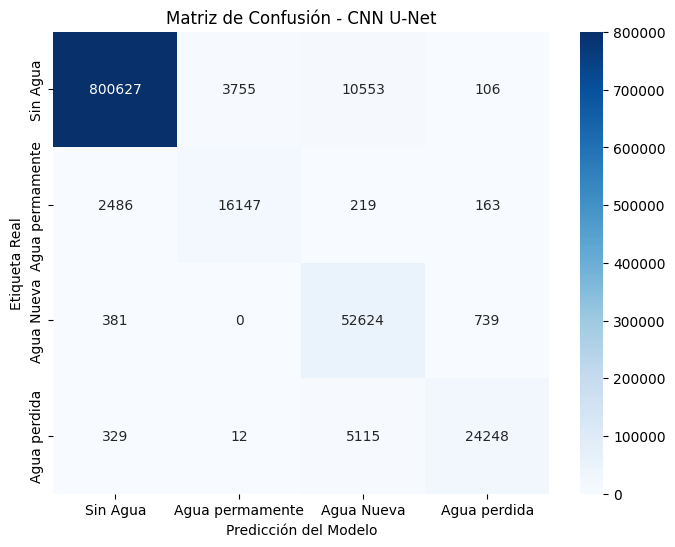

Calculando y exportando Curvas ROC...


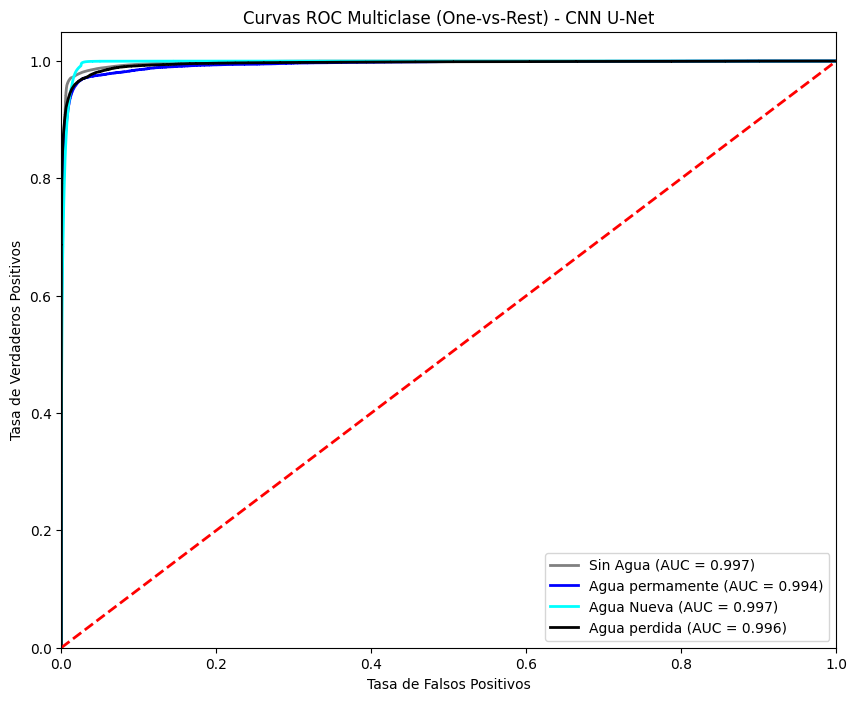

In [ ]:
"""
CLASIFICACION CON RED NEURONAL CONVOLUCIONAL U-NET
Evento: Inundacion de Bahia Blanca, 7 de marzo de 2025
Tesis: Deteccion y clasificacion de danos por inundaciones en imagenes
       satelitales opticas mediante aprendizaje automatico
Autor: Gabriel Alejandro Orozco

ESTRUCTURA DEL PIPELINE:
  Fase 1: Carga de imágenes Sentinel 2 y máscaras derivadas de Otsu
  Fase 2: Procesamiento y división en entrenamiento y testeo
  Fase 3: Implementacion del modelo con reporte de metricas y parada anticipada
"""
!pip install segmentation-models-pytorch torchmetrics -q

import os
import math
import rasterio
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc
import segmentation_models_pytorch as smp
import torch.optim as optim
import torchmetrics
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# FASE 1: CARGA DE DATOS DE ENTRADA
# ==============================================================================

# 1. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Crear la carpeta para guardar los resultados si no existe
ruta_guardado = '/content/drive/MyDrive/sentinel_data/resultados_unet'
os.makedirs(ruta_guardado, exist_ok=True)
ruta_mejor_modelo = os.path.join(ruta_guardado, 'mejor_modelo_unet.pth')
print(f"Los resultados y el modelo se guardarán en: {ruta_guardado}")

# 3. Carga de imágenes X (24 bandas temporales)
carpeta_pre = '/content/drive/MyDrive/sentinel_data/tiff_unet/pre_inundacion_cnn/'
carpeta_post = '/content/drive/MyDrive/sentinel_data/tiff_unet/post_inundacion_cnn/'
prefijo_pre = "2025-02-19-00_00_2025-02-19-23_59_Sentinel-2_L2A_"
prefijo_post = "2025-03-11-00_00_2025-03-11-23_59_Sentinel-2_L2A_"
sufijo = "_(Raw).tiff"
bandas = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']

canales = []
for banda in bandas:
    with rasterio.open(os.path.join(carpeta_pre, f"{prefijo_pre}{banda}{sufijo}")) as src:
        canales.append(src.read(1))
for banda in bandas:
    with rasterio.open(os.path.join(carpeta_post, f"{prefijo_post}{banda}{sufijo}")) as src:
        canales.append(src.read(1))

imagen_multitemporal = np.stack(canales, axis=0)

# 4. Carga y remapeo de etiquetas Y (0, 1, 2, 3)
ruta_mascaras = '/content/drive/MyDrive/sentinel_data/otsu_results/OTSU_mascaras_pre_post.npz'
archivo_npz = np.load(ruta_mascaras)
mascara_y = archivo_npz['mapa_cambio']

mascara_y[mascara_y == 64] = 2
mascara_y[mascara_y == 128] = 3
mascara_y[mascara_y == 255] = 1
mascara_y = np.expand_dims(mascara_y, axis=0)

# ==============================================================================
# FASE 2: PREPROCESAMIENTO Y DIVISIÓN (80/20)
# ==============================================================================
alto_original, ancho_original = 1666, 2500
tamano_parche = 256

nuevo_alto = math.ceil(alto_original / tamano_parche) * tamano_parche
nuevo_ancho = math.ceil(ancho_original / tamano_parche) * tamano_parche
padding_config = ((0, 0), (0, nuevo_alto - alto_original), (0, nuevo_ancho - ancho_original))

imagen_X_pad = np.pad(imagen_multitemporal, padding_config, mode='constant', constant_values=0)
mascara_Y_pad = np.pad(mascara_y, padding_config, mode='constant', constant_values=0)

X_parches, Y_parches = [], []
for i in range(0, nuevo_alto, tamano_parche):
    for j in range(0, nuevo_ancho, tamano_parche):
        X_parches.append(imagen_X_pad[:, i:i+tamano_parche, j:j+tamano_parche])
        Y_parches.append(mascara_Y_pad[:, i:i+tamano_parche, j:j+tamano_parche])

tensor_X = torch.tensor(np.stack(X_parches, axis=0), dtype=torch.float32)
tensor_Y = torch.tensor(np.stack(Y_parches, axis=0), dtype=torch.long).squeeze(1)

# División 80% Entrenamiento / 20% Testeo
X_train, X_val, Y_train, Y_val = train_test_split(tensor_X, tensor_Y, test_size=0.20, random_state=42)

# Configuración de los DataLoaders
dataloader_train = DataLoader(TensorDataset(X_train, Y_train), batch_size=8, shuffle=True)
dataloader_val = DataLoader(TensorDataset(X_val, Y_val), batch_size=8, shuffle=False)

# ==============================================================================
# FASE 3: MODELO, MÉTRICAS Y BUCLE CON REPORTE Y PARADA ANTICIPADA
# ==============================================================================
modelo = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=24, classes=4)
dice_loss = smp.losses.DiceLoss(mode='multiclass')
focal_loss = smp.losses.FocalLoss(mode='multiclass')

def funcion_perdida_combinada(predicciones, etiquetas):
    return dice_loss(predicciones, etiquetas) + focal_loss(predicciones, etiquetas)

optimizador = optim.Adam(modelo.parameters(), lr=0.001)

coleccion_metricas = torchmetrics.MetricCollection({
    'Accuracy': torchmetrics.Accuracy(task="multiclass", num_classes=4),
    'mIoU': torchmetrics.JaccardIndex(task="multiclass", num_classes=4),
    'F1_Dice': torchmetrics.F1Score(task="multiclass", num_classes=4),
    'Kappa': torchmetrics.CohenKappa(task="multiclass", num_classes=4),
    'Precision': torchmetrics.Precision(task="multiclass", num_classes=4),
    'Recall': torchmetrics.Recall(task="multiclass", num_classes=4)
})

# --- INICIO DE CONFIGURACIÓN DE ÉPOCAS ---
mejor_error_val = float('inf')
epocas = 100               # Límite alto para permitir que el modelo decida
paciencia = 7              # Cuántas épocas perdonamos sin mejoras
contador_sin_mejora = 0    # Contador de épocas sin mejora
# --------------------------------------------------

for epoca in range(epocas):
    print(f"\n==================== Época {epoca + 1} de {epocas} ====================")

    # --- FASE 1: ENTRENAMIENTO ---
    modelo.train()
    error_train_acumulado = 0.0

    for lote_X, lote_Y in dataloader_train:
        optimizador.zero_grad()
        predicciones = modelo(lote_X)
        error = funcion_perdida_combinada(predicciones, lote_Y)
        error.backward()
        optimizador.step()
        error_train_acumulado += error.item()

    promedio_train = error_train_acumulado / len(dataloader_train)
    print(f"Pérdida Entrenamiento (Loss): {promedio_train:.4f}")

    # --- FASE 2: VALIDACIÓN Y MÉTRICAS ---
    modelo.eval()
    error_val_acumulado = 0.0

    with torch.no_grad():
        for lote_X, lote_Y in dataloader_val:
            predicciones = modelo(lote_X)
            error = funcion_perdida_combinada(predicciones, lote_Y)
            error_val_acumulado += error.item()
            coleccion_metricas(predicciones, lote_Y)

    promedio_val = error_val_acumulado / len(dataloader_val)
    print(f"Pérdida Validación (Loss):    {promedio_val:.4f}")

    resultados_epoca = coleccion_metricas.compute()
    coleccion_metricas.reset()

    print("\nDesempeño en Validación:")
    for nombre_metrica, valor in resultados_epoca.items():
        print(f"  • {nombre_metrica:10s}: {valor.item():.4f}")

    # --- CHECKPOINT CON PARADA ANTICIPADA ---
    if promedio_val < mejor_error_val:
        mejor_error_val = promedio_val
        torch.save(modelo.state_dict(), ruta_mejor_modelo)
        print(f"\n🌟 ¡Nuevo récord! Modelo guardado en: {ruta_mejor_modelo}")
        contador_sin_mejora = 0  # Reinicio de la cuenta
    else:
        contador_sin_mejora += 1
        print(f"\n⚠️ Sin mejora por {contador_sin_mejora} época(s)...")

        if contador_sin_mejora >= paciencia:  # Instrucción de corte
            print(f"\n🛑 Parada anticipada activada en la época {epoca + 1}. El modelo ha convergido.")
            break
# ==============================================================================
# FASE 4: DIAGNÓSTICO FINAL Y EXPORTACIÓN DE GRÁFICOS
# ==============================================================================

# 1. Cargar el mejor modelo guardado
modelo.load_state_dict(torch.load(ruta_mejor_modelo))
modelo.eval()

todas_pred_probabilidades = []
todas_pred_clases = []
todas_etiquetas = []

print("Generando examen final unificado...")
with torch.no_grad():
    for lote_X, lote_Y in dataloader_val:
        puntajes_crudos = modelo(lote_X)
        probabilidades = F.softmax(puntajes_crudos, dim=1)
        clases_predichas = torch.argmax(puntajes_crudos, dim=1)

        todas_pred_probabilidades.append(probabilidades.cpu())
        todas_pred_clases.append(clases_predichas.cpu())
        todas_etiquetas.append(lote_Y.cpu())

# Unimos los lotes y aplanamos
tensor_probabilidades = torch.cat(todas_pred_probabilidades)
tensor_clases = torch.cat(todas_pred_clases)
tensor_etiquetas = torch.cat(todas_etiquetas)

etiquetas_planas = tensor_etiquetas.flatten()
clases_planas = tensor_clases.flatten()

nombres_clases = ['Sin Agua', 'Agua permamente', 'Agua Nueva', 'Agua perdida']

# ---------------------------------------------------------
# GRÁFICO 1: MATRIZ DE CONFUSIÓN
# ---------------------------------------------------------
print("Calculando y exportando Matriz de Confusión...")
matriz_numeros = confusion_matrix(etiquetas_planas, clases_planas)

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_numeros, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - CNN U-Net')

ruta_matriz = os.path.join(ruta_guardado, 'matriz_confusion.png')
plt.savefig(ruta_matriz, dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# GRÁFICO 2: CURVAS ROC MULTICLASE
# ---------------------------------------------------------
print("Calculando y exportando Curvas ROC...")
etiquetas_one_hot = F.one_hot(etiquetas_planas, num_classes=4)

# Aplanamos las probabilidades manteniendo las 4 columnas
probabilidades_planas = tensor_probabilidades.permute(0, 2, 3, 1).reshape(-1, 4)

plt.figure(figsize=(10, 8))
colores = ['gray', 'blue', 'cyan', 'black']

for i in range(4):
    # Usamos probabilidades_planas en lugar de tensor_probabilidades
    fpr, tpr, _ = roc_curve(etiquetas_one_hot[:, i], probabilidades_planas[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colores[i], lw=2, label=f'{nombres_clases[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curvas ROC Multiclase (One-vs-Rest) - CNN U-Net')
plt.legend(loc="lower right")

ruta_roc = os.path.join(ruta_guardado, 'curva_roc.png')
plt.savefig(ruta_roc, dpi=300, bbox_inches='tight')
plt.show()